# Azul — agente R1 de aprendizaje por refuerzo


Instalaciones e importaciones

In [ ]:
%pip install -q gymnasium stable-baselines3 sb3-contrib pettingzoo

In [ ]:
%pip install imageio imageio-ffmpeg pillow

In [ ]:
# @title
import sympy
import sympy.logic
import sympy.logic.boolalg

import torch
from stable_baselines3 import PPO
from sb3_contrib import MaskablePPO

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# @title
from pathlib import Path
import argparse
import json
import csv
import numpy as np
from unittest.mock import patch
from IPython.display import clear_output, display
from PIL import Image
import imageio.v2 as imageio
import matplotlib.pyplot as plt
import pandas as pd
import io


Código de implementación de Azul

In [ ]:
# @title
import numpy as np
import random
import matplotlib.pyplot as plt
import matplotlib.patches as patches

class Azul:

  def __init__(self, tableros, bolsas, centro, moda, descuento, ronda, Ficha_blanca):
    self.tableros = tableros
    self.bolsas = bolsas
    self.centro = centro
    self.moda = moda
    self.descuento = descuento #no estoy seguro si DCS o DC5 en la imagen y eso signifique descuento
    # self.puntaje = puntaje ######este segun yo no es necesario ahora al crear la clase jugador#######
    self.ronda =  ronda
    self.Ficha_blanca = Ficha_blanca
    # Reserva física: 20 fichas de cada uno de los 5 colores.
    # Se consume al preparar cada ronda; no se repone entre rondas.
    self.bolsa_grande = [color for color in range(1, 6) for _ in range(20)]
    self.repartidas_por_color = {color: 0 for color in range(1, 6)}
    self.historial_repartos = []

  def Sacar_fichas(self,ficha,n_bolsa): ######### puedes implementar que mueva las fichas al centro tambien a la hora de sacarlas de la bolsa#########
    if ficha in self.bolsas[n_bolsa]:
      cantidad_sacada = self.bolsas[n_bolsa].count(ficha)
      sobrante = [f for f in self.bolsas[n_bolsa] if f != ficha]
      self.centro.extend(sobrante)
      self.bolsas[n_bolsa] = [0,0,0,0]
      # self.bolsas[n_bolsa][self.bolsas[n_bolsa] == ficha] = 0
      # self.centro.extend(self.bolsas[n_bolsa])
      # self.bolsas[n_bolsa][self.bolsas[n_bolsa] != 0] = 0
      # self.centro = [x for x in self.centro if x != 0]
      return cantidad_sacada
    else:
      return 'No esta la ficha'

  def Poner_ficha_tablero(self,ficha,cantidad, fila,n_jugador):
    linea = self.tableros[n_jugador]['lineas_patron'][fila]
    if np.all((linea == 0) | (linea == ficha)): #np.unique(self.tableros[n_jugador]['lineas_patron'][fila]) == np.array([0]) or np.unique(self.tableros[n_jugador]['lineas_patron'][fila]) == np.array([0,ficha]):
      n,c = np.unique(linea, return_counts=True) #np.unique(self.tableros[n_jugador]['lineas_patron'][fila],return_counts=True)
      d = dict(zip(n,c))
      if 0 in d:
        sobrantes = cantidad - d[0]
        if sobrantes > 0:
          if ficha in d:
            for i in range(0,min(d[0],cantidad)):
              linea[i+d[ficha]] = ficha
            return sobrantes
          else:
            for i in range(0,min(d[0],cantidad)):
              linea[i] = ficha
            return sobrantes
        else:
          if ficha in d:
            for i in range(0,min(d[0],cantidad)):
              linea[i+d[ficha]] = ficha
            return 0
          else:
            for i in range(0,min(d[0],cantidad)):
              linea[i] = ficha
            return 0
      else:
        return cantidad
    else:
      return 'falla'



  def Sacar_ficha_centro(self,ficha): #####puedes hacer que retorne la cantidad para el tema de colocarlo en el tablero?#########
    if ficha in self.centro:
      cantidad_sacada = self.centro.count(ficha)
      #self.centro[self.centro == ficha] = 0
      #self.centro = [x for x in self.centro if x != 0]
      self.centro = [x for x in self.centro if x != ficha]
      return cantidad_sacada
    else:
      return 'No esta la ficha'


  def Poner_ficha_muralla(self, ficha,n_jugador, n_tablero, fila):

      muro = self.tableros[n_jugador][n_tablero][1]
      patron_base = [1, 2, 3, 4, 5]
      columna = (patron_base.index(ficha) + fila) % 5
      if muro[fila][columna] != 0:
          return "Error: Ya hay una ficha en esa posición del muro."

      muro[fila][columna] = ficha
      puntos = 1
      c = columna - 1
      while c >= 0 and muro[fila][c] != 0:
          puntos += 1
          c -= 1

      c = columna + 1
      while c < 5 and muro[fila][c] != 0:
          puntos += 1
          c += 1

      f = fila - 1
      while f >= 0 and muro[f][columna] != 0:
          puntos += 1
          f -= 1

      f = fila + 1
      while f < 5 and muro[f][columna] != 0:
          puntos += 1
          f += 1

      return puntos















def crear_azul(num_jugadores=2):
    """Cada llamada crea una partida NUEVA, con tableros independientes."""
    bolsas = [[0, 0, 0, 0] for _ in range(5)]  # Se llenan en preparar_ronda()
    centro = []
    moda = np.zeros(5, dtype=int)
    tableros = []
    for _ in range(num_jugadores):
        tableros.append({
            'lineas_patron': [np.zeros(i, dtype=int) for i in range(1, 6)],
            'muro': np.zeros((5, 5), dtype=int)
        })
    descuento = [np.zeros(7, dtype=int) for _ in range(num_jugadores)]
    return Azul(tableros, bolsas, centro, moda, descuento, 1, True)


class Jugador:
    def __init__(self, nombre):
        self.nombre = nombre
        self.puntos = 0

    def sumar_puntos(self, cantidad):
        self.puntos += cantidad



class Partida:
  def __init__(self, azul, seed=None):
    self.filas_puntuadas = set()
    self.azul = azul
    self.jugadores = [Jugador("Jugador 1"), Jugador("Jugador 2")]
    self.turno = 0
    self.rng = np.random.default_rng(seed)
    self.azul.moda = self.rng.permutation(np.arange(1, 6))
    self.descuentos_ronda = [0, 0]
    self.sobrantes_ronda = [0, 0]
    self.terminada = False
    self.azul.ronda = 1
    self.preparar_ronda()

  def siguiente_turno(self):
    self.turno = (self.turno + 1) % 2

  def realizar_jugada(self, bolsa, ficha, fila):
      if not 1 <= ficha <= 5:
        print("Color inválido.")
        return False

      if not 0 <= bolsa <= len(self.azul.bolsas):
        print("Bolsa inválida.")
        return False

      if bolsa == 0: #vemos si hay fichas del color
        disponibles = np.asarray(self.azul.centro)
      else:
        disponibles = np.asarray(self.azul.bolsas[bolsa - 1])

      if not np.any(disponibles == ficha):
        print("No hay fichas de ese color.")
        return False

      tablero = self.azul.tableros[self.turno]['lineas_patron']

      if not 0 <= fila <= len(tablero):
        print("Fila inválida.")
        return False

      if fila != 0: #vemos si la fila permite el color
        casillas = tablero[fila - 1]
        if not np.any(casillas == 0):
          print("La fila está completa. Elige otra fila o la fila 0 para descartar.")
          return False
        if np.any((casillas != 0) & (casillas != ficha)):
          print("La fila contiene otro color.")
          return False

      # Sacar fichas del centro o de una fábrica
      if bolsa == 0:
        cantidad = self.azul.Sacar_ficha_centro(ficha)

        if self.azul.Ficha_blanca:
          self.azul.Ficha_blanca = False
          self.dueno_ficha_blanca = self.turno
          self.descuentos_ronda[self.turno] += 1
          print("Tomaste la ficha blanca: -1 punto.")

      else:
        cantidad = self.azul.Sacar_fichas(ficha, bolsa - 1)

      if fila == 0: #colocar las fichas y contar restantes
        sobrantes = cantidad
      else:
        sobrantes = self.azul.Poner_ficha_tablero(ficha, cantidad, fila - 1, self.turno )

      # descuentos
      penalizaciones = [1, 1, 2, 2, 3, 3]
      inicio = self.sobrantes_ronda[self.turno]
      fin = min(inicio + sobrantes, len(penalizaciones))
      descuento = sum(penalizaciones[inicio:fin])

      self.descuentos_ronda[self.turno] += descuento
      self.sobrantes_ronda[self.turno] += sobrantes

      print("Fichas tomadas:", cantidad)
      print("Fichas sobrantes:", sobrantes)

      return True


  def quedan_fichas(self):
    return (any(np.any(np.asarray(bolsa) != 0) for bolsa in self.azul.bolsas)
            or np.any(np.asarray(self.azul.centro) != 0))

  def jugadas_posibles(self):
    """Tuplas (bolsa, color, fila), donde fila 0 significa descarte."""
    opciones = []
    fuentes = [(0, self.azul.centro)] + [
        (i + 1, bolsa) for i, bolsa in enumerate(self.azul.bolsas)
    ]
    tablero = self.azul.tableros[self.turno]['lineas_patron']
    for n_bolsa, fichas in fuentes:
      fichas = np.asarray(fichas)
      colores = np.unique(fichas[(fichas >= 1) & (fichas <= 5)])
      for color in colores:
        color = int(color)
        opciones.append((n_bolsa, color, 0))  # Descartar todo el color elegido.
        for i, fila in enumerate(tablero, start=1):
          if np.any(fila == 0) and np.all((fila == 0) | (fila == color)):
            opciones.append((n_bolsa, color, i))
    return opciones

  def jugar_turno(self, jugada, mostrar=False):
    """Recibe (bolsa, color, fila). No pide datos por consola."""
    if self.terminada:
      print("La partida ya terminó.")
      return False

    if not isinstance(jugada, (tuple, list)) or len(jugada) != 3:
      raise ValueError("La jugada debe ser una tupla (bolsa, ficha, fila).")
    if not all(isinstance(valor, (int, np.integer)) for valor in jugada):
      raise ValueError("Bolsa, ficha y fila deben ser números enteros.")

    if mostrar:
      self.mostrar_estado()

    bolsa, ficha, fila = (int(v) for v in jugada)
    print(f"\nTurno de {self.jugadores[self.turno].nombre}: {(bolsa, ficha, fila)}")
    if not self.realizar_jugada(bolsa, ficha, fila):
      return False

    self.siguiente_turno()
    if not self.quedan_fichas():
      self.finalizar_ronda()
      if self.azul.ronda < 5:
        self.azul.ronda += 1
        self.preparar_ronda()
      else:
        self.terminada = True
        self.mostrar_resultado_final()
    return True

  def jugar_ronda(self, jugadas, mostrar=False):
    """Recibe una secuencia de jugadas. Se detiene al acabar la ronda."""
    ronda_actual = self.azul.ronda
    for jugada in jugadas:
      if self.terminada or self.azul.ronda != ronda_actual:
        break
      self.jugar_turno(jugada, mostrar=mostrar)
    return self.estado()

  def jugar(self, jugadas, mostrar=False):
    """Acepta una sola jugada (bolsa, ficha, fila) o una lista de jugadas."""
    if (isinstance(jugadas, (tuple, list)) and len(jugadas) == 3
        and all(isinstance(x, (int, np.integer)) for x in jugadas)):
      return self.jugar_turno(jugadas, mostrar=mostrar)
    for jugada in jugadas:
      if self.terminada:
        break
      self.jugar_turno(jugada, mostrar=mostrar)
    return self.estado()

  def estado(self):
    return {
      'ronda': self.azul.ronda,
      'turno': self.turno,
      'puntos': [j.puntos for j in self.jugadores],
      'terminada': self.terminada,
    }

  def estado_reserva(self):
    """Estado de las fichas extraídas y las que quedan disponibles."""
    return {
      'ronda_actual': self.azul.ronda,
      'restantes_total': len(self.azul.bolsa_grande),
      'restantes_por_color': {
        color: self.azul.bolsa_grande.count(color) for color in range(1, 6)
      },
      'repartidas_por_color': self.azul.repartidas_por_color.copy(),
      'historial_repartos': [
        {
          'ronda': registro['ronda'],
          'bolsas': [bolsa.copy() for bolsa in registro['bolsas']],
          'por_color': registro['por_color'].copy(),
        }
        for registro in self.azul.historial_repartos
      ],
    }

  def mostrar_resultado_final(self):
    print("\n========== FIN DE PARTIDA ==========")
    puntos = [jugador.puntos for jugador in self.jugadores]
    for jugador in self.jugadores:
      print(jugador.nombre, ":", jugador.puntos)
    if puntos[0] == puntos[1]:
      print("\nEmpate")
    else:
      ganador = self.jugadores[int(np.argmax(puntos))]
      print(f"\nGanador: {ganador.nombre} con {ganador.puntos} puntos.")

  def finalizar_ronda(self):
    moda = int(self.azul.moda[self.azul.ronda - 1])
    print(f"\nResultados de la ronda {self.azul.ronda}")
    print("Moda:", moda)
    for j, jugador in enumerate(self.jugadores):
      puntos_filas = 0
      puntos_moda =0
      for fila in self.azul.tableros[j]['lineas_patron']:
        puntos_moda += np.count_nonzero(fila == moda) # contar fichas de moda
        if np.all(fila != 0): #si la fila esta completa
          puntos_filas += len(fila)
          fila[:] = 0 #vaciar las compleras

      descuento = self.descuentos_ronda[j]
      puntos_ronda = puntos_filas + puntos_moda - descuento
      jugador.sumar_puntos(puntos_ronda)
      print(f"\n{jugador.nombre}")
      print("Puntos por filas:", puntos_filas)
      print("Puntos por moda:", puntos_moda)
      print("Descuentos:", descuento)
      print("Puntos de la ronda:", puntos_ronda)
      print("Total acumulado:", jugador.puntos)
    self.azul.puntaje = np.array([jugador.puntos for jugador in self.jugadores])

  def preparar_ronda(self):
    self.dueno_ficha_blanca = None
    self.sobrantes_ronda = [0, 0]
    # Extraer fichas SIN reposición de la misma reserva durante las 5 rondas.
    fichas_por_fabrica = 4
    total_a_extraer = len(self.azul.bolsas) * fichas_por_fabrica
    if len(self.azul.bolsa_grande) < total_a_extraer:
      raise ValueError("No hay suficientes fichas en la reserva para esta ronda.")

    self.rng.shuffle(self.azul.bolsa_grande)
    extraidas = [self.azul.bolsa_grande.pop() for _ in range(total_a_extraer)]
    for i in range(len(self.azul.bolsas)):
      inicio = i * fichas_por_fabrica
      self.azul.bolsas[i] = extraidas[inicio:inicio + fichas_por_fabrica]

    conteo_ronda = {color: extraidas.count(color) for color in range(1, 6)}
    for color, cantidad in conteo_ronda.items():
      self.azul.repartidas_por_color[color] += cantidad
    self.azul.historial_repartos.append({
      'ronda': self.azul.ronda,
      'bolsas': [bolsa.copy() for bolsa in self.azul.bolsas],
      'por_color': conteo_ronda.copy(),
    })
    # self.azul.centro = np.array([], dtype=int) #vaciar el centro
    self.azul.centro = []                       ####Lo mismo que las bolsas####
    self.azul.Ficha_blanca = True #restaurar la ficha blanca
    self.descuentos_ronda = [0, 0] #reiniciar los descuentos
    print(f"\n========== RONDA {self.azul.ronda} ==========")
    print("Moda de la ronda:", self.azul.moda[self.azul.ronda - 1])

  def mostrar_estado(self):
      """Muestra gráficamente el estado actual de la partida."""

      fig, ax = plt.subplots(figsize=(14, 9))
      ax.axis('off')

      colores_map = {
          0: '#E0E0E0',
          1: '#1E90FF',
          2: '#FFD700',
          3: '#DC143C',
          4: '#2F4F4F',
          5: '#FAFAFA',
          99: '#FF8C00'
      }

      # --- ENCABEZADO ---
      ax.text(
          0.5, 0.96,
          f"RONDA {self.azul.ronda} — Turno de: {self.jugadores[self.turno].nombre}",
          ha='center', va='center',
          fontsize=16, fontweight='bold',
          transform=ax.transAxes
      )

      # --- MODA ACTUAL ---
      moda = int(self.azul.moda[self.azul.ronda - 1])

      ax.text(
          0.49, 0.915, "Moda actual:",
          fontsize=12, fontweight='bold',
          ha='right', va='center',
          transform=ax.transAxes
      )

      rect = patches.Rectangle(
          (0.51, 0.895), 0.04, 0.04,
          facecolor=colores_map[moda],
          edgecolor='black',
          linewidth=1.5,
          transform=ax.transAxes
      )
      ax.add_patch(rect)

      ax.text(
          0.53, 0.915, str(moda),
          ha='center', va='center',
          fontsize=11, fontweight='bold',
          color='white' if moda == 4 else 'black',
          transform=ax.transAxes
      )

      # --- FÁBRICAS ---
      ax.text(
          0.5, 0.86, "Bolsas:",
          fontsize=12, fontweight='bold',
          ha='center', transform=ax.transAxes
      )

      n_fabricas = len(self.azul.bolsas)
      separacion = 0.18
      inicio = 0.5 - ((n_fabricas - 1) * separacion) / 2

      for i, fabrica in enumerate(self.azul.bolsas):

          x_base = inicio + i * separacion

          ax.text(
              x_base, 0.82, f"Bolsa {i+1}",
              fontsize=10, ha='center',
              transform=ax.transAxes
          )

          for j, ficha in enumerate(fabrica):

              x_pos = x_base - len(fabrica) * 0.0175 + j * 0.035
              col = colores_map.get(int(ficha), '#FFFFFF')

              rect = patches.Rectangle(
                  (x_pos, 0.76), 0.03, 0.04,
                  facecolor=col, edgecolor='black',
                  transform=ax.transAxes
              )
              ax.add_patch(rect)

              if ficha != 0:
                  ax.text(
                      x_pos + 0.015, 0.78, str(ficha),
                      ha='center', va='center',
                      fontsize=8, fontweight='bold',
                      color='white' if ficha == 4 else 'black',
                      transform=ax.transAxes
                  )

      # --- CENTRO DE LA MESA ---
      ax.text(
          0.5, 0.70,
          f"Centro (Total: {len(self.azul.centro)}):",
          fontsize=12, fontweight='bold',
          ha='center', transform=ax.transAxes
      )

      center_tiles = self.azul.centro
      visibles = center_tiles[:16]

      for idx, ficha in enumerate(visibles):

          row_c = idx // 8
          col_c = idx % 8

          cantidad_fila = min(8, len(visibles) - row_c * 8)
          x_inicio = 0.5 - (cantidad_fila * 0.03) / 2

          x_c = x_inicio + col_c * 0.03
          y_c = 0.63 - row_c * 0.045

          col = colores_map.get(int(ficha), '#FFFFFF')

          rect = patches.Rectangle(
              (x_c, y_c), 0.025, 0.035,
              facecolor=col, edgecolor='black',
              transform=ax.transAxes
          )
          ax.add_patch(rect)

          texto_ficha = 'BF' if ficha == 99 else str(ficha)

          ax.text(
              x_c + 0.0125, y_c + 0.0175,
              texto_ficha if ficha != 0 else '',
              ha='center', va='center',
              fontsize=7, fontweight='bold',
              color='white' if ficha == 4 else 'black',
              transform=ax.transAxes
          )

      # --- FICHA DE PENALIZACIÓN DEL CENTRO ---
      if self.azul.Ficha_blanca:

          rect = patches.Rectangle(
              (0.43, 0.52), 0.035, 0.04,
              facecolor=colores_map[99],
              edgecolor='black',
              linewidth=1.5,
              transform=ax.transAxes
          )
          ax.add_patch(rect)

          ax.text(
              0.4475, 0.54, "-1",
              ha='center', va='center',
              fontsize=9, fontweight='bold',
              transform=ax.transAxes
          )

          ax.text(
              0.48, 0.54, "Ficha de penalización disponible",
              fontsize=10, va='center',
              transform=ax.transAxes
          )

      # --- TABLEROS DE LOS JUGADORES ---
      for j_idx, jugador in enumerate(self.jugadores):

          x_offset = 0.07 + j_idx * 0.48
          y_offset = 0.36

          # Información del jugador
          ax.text(
              x_offset, 0.48,
              f"{jugador.nombre} | Puntos Totales: {jugador.puntos}",
              fontsize=11, fontweight='bold',
              transform=ax.transAxes
          )

          ax.text(
              x_offset, 0.445,
              f"Penalización Ronda: {self.descuentos_ronda[j_idx]}",
              fontsize=10,
              transform=ax.transAxes
          )

          # --- FICHA -1 DEL JUGADOR ---
          if getattr(self, 'dueno_ficha_blanca', None) == j_idx:

              rect = patches.Rectangle(
                  (x_offset + 0.27, 0.40), 0.035, 0.035,
                  facecolor=colores_map[99],
                  edgecolor='black',
                  linewidth=1.5,
                  transform=ax.transAxes
              )
              ax.add_patch(rect)

              ax.text(
                  x_offset + 0.2875, 0.4175, "-1",
                  ha='center', va='center',
                  fontsize=9, fontweight='bold',
                  transform=ax.transAxes
              )

              ax.text(
                  x_offset + 0.31, 0.4175, "Centro",
                  fontsize=9, va='center',
                  transform=ax.transAxes
              )

          # --- LÍNEAS DE PATRÓN ---
          ax.text(
              x_offset, y_offset,
              "Líneas de Patrón:",
              fontsize=10,
              transform=ax.transAxes
          )

          tablero_lineas = self.azul.tableros[j_idx]['lineas_patron']

          for fila_idx, fila in enumerate(tablero_lineas):

              for col_idx, ficha in enumerate(fila):

                  x_pos = x_offset + col_idx * 0.045
                  y_pos = y_offset - 0.065 - fila_idx * 0.055

                  col = colores_map.get(int(ficha), '#FFFFFF')

                  rect = patches.Rectangle(
                      (x_pos, y_pos), 0.04, 0.04,
                      facecolor=col, edgecolor='black',
                      transform=ax.transAxes
                  )
                  ax.add_patch(rect)

                  if ficha != 0:
                      ax.text(
                          x_pos + 0.02, y_pos + 0.02,
                          str(ficha),
                          ha='center', va='center',
                          fontsize=8, fontweight='bold',
                          color='white' if ficha == 4 else 'black',
                          transform=ax.transAxes
                      )

      plt.tight_layout()
      plt.show()

class PartidaSolitaria(Partida):
  def __init__(self, azul):
    super().__init__(azul)
    self.jugadores[1].nombre = "Computador"

  def jugada_computador(self):
    opciones = self.jugadas_posibles()
    if not opciones:
      raise ValueError("No quedan jugadas válidas para el computador.")
    indice = self.rng.integers(len(opciones))
    return opciones[indice]

  def jugar_turno(self, jugada, mostrar=False):
    """Recibe una jugada HUMANA y luego hace jugar al computador."""
    if self.turno != 0:
      raise ValueError("Ahora no es el turno del jugador humano.")

    valido = super().jugar_turno(jugada, mostrar=mostrar)
    if not valido:
      return False

    # El computador puede comenzar la ronda siguiente si acabó la anterior.
    while not self.terminada and self.turno == 1:
      jugada_cpu = self.jugada_computador()
      super().jugar_turno(jugada_cpu, mostrar=mostrar)
    return True




Implementación de Gym y de PettingZOO

In [ ]:
# @title
#Fue corregido con IA
NUM_ACCIONES = 6 * 5 * 6
PENALIZACIONES = (1, 1, 2, 2, 3, 3)


def codificar(jugada):
    bolsa, color, fila = (int(x) for x in jugada)
    if not (0 <= bolsa <= 5 and 1 <= color <= 5 and 0 <= fila <= 5):
        raise ValueError(f'Jugada fuera de rango: {jugada}')
    return (bolsa * 5 + color - 1) * 6 + fila


def decodificar(accion):
    accion = int(accion)
    if not 0 <= accion < NUM_ACCIONES:
        raise ValueError(f'Acción inválida: {accion}')
    bolsa, resto = divmod(accion, 30)
    color_menos_1, fila = divmod(resto, 6)
    return (bolsa, color_menos_1 + 1, fila)


def jugadas_legales(partida):
    return partida.jugadas_posibles() if not partida.terminada else []


def mascara_acciones(partida):
    mascara = np.zeros(NUM_ACCIONES, dtype=bool)
    for jugada in jugadas_legales(partida):
        mascara[codificar(jugada)] = True
    return mascara


def jugada_uniforme(partida, rng):

    opciones = jugadas_legales(partida)
    if not opciones:
        raise ValueError('No quedan jugadas posibles')
    return opciones[int(rng.integers(len(opciones)))]


def valor_heuristico(partida, jugada):

    bolsa, color, fila = jugada
    disponibles = (partida.azul.centro if bolsa == 0
                    else partida.azul.bolsas[bolsa - 1])
    cantidad = disponibles.count(color)
    jugador = partida.turno
    moda = int(partida.azul.moda[partida.azul.ronda - 1])
    if fila == 0:
        colocadas, sobrantes, bono = 0, cantidad, -1.0
    else:
        linea = partida.azul.tableros[jugador]['lineas_patron'][fila-1]
        libres = int(np.count_nonzero(linea == 0))
        colocadas = min(cantidad, libres)
        sobrantes = cantidad-colocadas
        bono = 2.0 * len(linea) * (cantidad >= libres) + 0.4 * (len(linea) - libres)
    inicio = partida.sobrantes_ronda[jugador]
    penalidad = sum(PENALIZACIONES[inicio:min(inicio+sobrantes, len(PENALIZACIONES))])
    penalidad_centro = int(bolsa == 0 and partida.azul.Ficha_blanca)
    return (1.1*colocadas + 1.4*(color == moda)*colocadas
            + bono - 2.0*penalidad - 1.3*penalidad_centro)


def jugada_heuristica(partida, rng):
    opciones = jugadas_legales(partida)
    if not opciones:
        raise ValueError('No quedan jugadas posibles')
    valores = np.array([valor_heuristico(partida, j) for j in opciones])
    mejores = np.flatnonzero(np.isclose(valores, valores.max()))
    return opciones[int(rng.choice(mejores))]


def observacion(partida, jugador):
    az = partida.azul
    rival = 1 - jugador
    moda = int(az.moda[az.ronda-1])
    datos = [az.ronda/5.0]
    datos += [float(moda == c) for c in range(1, 6)]
    for fabrica in az.bolsas:
        datos.extend(fabrica.count(c)/4 for c in range(1, 6))
    datos.extend(az.centro.count(c)/20 for c in range(1, 6))
    datos.append(float(az.Ficha_blanca))
    datos.extend(az.bolsa_grande.count(c)/20 for c in range(1, 6))
    for j in (jugador, rival):
        for linea in az.tableros[j]['lineas_patron']:
            color = next((int(x) for x in linea if x != 0), 0)
            datos.extend((color/5, np.count_nonzero(linea)/len(linea)))
    datos.extend(partida.jugadores[j].puntos/100 for j in (jugador, rival))
    datos.extend(partida.descuentos_ronda[j]/20 for j in (jugador, rival))
    datos.extend(partida.sobrantes_ronda[j]/20 for j in (jugador, rival))
    return np.asarray(datos, dtype=np.float32)


def nueva_partida(semilla):

    with redirect_stdout(io.StringIO()):
        return Partida(crear_azul(), seed=semilla)


def _jugar_sin_imprimir(partida, jugada):
    with redirect_stdout(io.StringIO()):
        ok = partida.jugar_turno(jugada)
    if not ok:
        raise RuntimeError(f'Fallo al ejecutar jugada legal: {jugada}')


try:
    import gymnasium as gym
    from gymnasium import spaces
except ImportError:
    gym, spaces = None, None

if gym is not None:
    class AzulGym(gym.Env):

        metadata = {'render_modes': []}

        def __init__(self, oponente='uniforme', factor_rival=0.0):
            super().__init__()
            if oponente not in ('uniforme','heuristica'):
                raise ValueError('oponente debe ser uniforme o heuristica')
            self.oponente = oponente
            self.factor_rival = float(factor_rival)
            self.action_space = spaces.Discrete(NUM_ACCIONES)
            self.observation_space = spaces.Box(low=-np.inf, high=np.inf,
                                                shape=(len(observacion(nueva_partida(0), 0)),),
                                                dtype=np.float32)
            self.num_episodios = 0
            self.partida = None
            self.asiento = 0
            self.puntos_antes = [0,0]
            self.rng_rival = None
            self.pasos_invalidos = 0

        def reset(self, *, seed=None, options=None):
            super().reset(seed=seed)
            options = options or {}
            if 'asiento' in options:
                self.asiento = int(options['asiento'])
            else:
                self.asiento = self.num_episodios % 2
            if self.asiento not in (0,1):
                raise ValueError('El asiento debe ser 0 o 1')
            self.num_episodios += 1
            semilla_juego = int(self.np_random.integers(0, 2**31-1))
            self.partida = nueva_partida(semilla_juego)
            self.rng_rival = np.random.default_rng(int(self.np_random.integers(0,2**31-1)))
            self.puntos_antes = [0, 0]
            self.pasos_invalidos = 0
            self._avanzar_rival()
            return observacion(self.partida, self.asiento), self._info()

        def _info(self):
            puntos = [int(j.puntos) for j in self.partida.jugadores]
            es_final = self.partida.terminada
            return {'asiento':self.asiento, 'ronda':int(self.partida.azul.ronda),
                    'puntos':puntos, 'victoria':int(es_final and puntos[self.asiento]>puntos[1-self.asiento]),
                    'empate':int(es_final and puntos[0]==puntos[1]),
                    'repartidas_por_color':self.partida.azul.repartidas_por_color.copy()}

        def _recompensa_cierre(self, ronda_antes):
            if self.partida.azul.ronda == ronda_antes and not self.partida.terminada:
                return 0.0
            despues = [int(j.puntos) for j in self.partida.jugadores]
            agente = despues[self.asiento] - self.puntos_antes[self.asiento]
            rival = despues[1-self.asiento] - self.puntos_antes[1-self.asiento]
            self.puntos_antes = despues
            return float(agente - self.factor_rival*rival)

        def _avanzar_rival(self):
            ganancia = 0.0
            while not self.partida.terminada and self.partida.turno != self.asiento:
                poli = jugada_uniforme if self.oponente=='uniforme' else jugada_heuristica
                jugada = poli(self.partida, self.rng_rival)
                ronda_antes = self.partida.azul.ronda
                _jugar_sin_imprimir(self.partida, jugada)
                ganancia += self._recompensa_cierre(ronda_antes)
            return ganancia

        def action_masks(self):
            if self.partida is None:
                return np.zeros(NUM_ACCIONES,dtype=bool)
            return mascara_acciones(self.partida)

        def step(self, action):
            if self.partida is None or self.partida.terminada:
                raise RuntimeError('Ejecuta reset() antes de step()')
            jugada = decodificar(action)
            if jugada not in jugadas_legales(self.partida):
                self.pasos_invalidos += 1
                truncado = self.pasos_invalidos >= 100
                return observacion(self.partida, self.asiento), -5.0, False, truncado, {
                    **self._info(), 'accion_invalida':True, 'jugada':jugada}
            ronda_antes = self.partida.azul.ronda
            _jugar_sin_imprimir(self.partida, jugada)
            recompensa = self._recompensa_cierre(ronda_antes)
            recompensa += self._avanzar_rival()
            return observacion(self.partida, self.asiento), recompensa, self.partida.terminada, False, {
                **self._info(), 'accion_invalida':False, 'jugada':jugada}
else:
    class AzulGym:
        def __init__(self,*args,**kwargs):
            raise ImportError('Falta Gymnasium: ejecuta %pip install gymnasium stable-baselines3 sb3-contrib pettingzoo')


try:
    from pettingzoo import AECEnv
except ImportError:
    AECEnv = None

if AECEnv is not None and spaces is not None:
    class AzulAEC(AECEnv):
        metadata = {'name':'azul_aec_v0', 'render_modes':[]}

        def __init__(self):
            super().__init__()
            self.possible_agents = ['jugador_0','jugador_1']
            self._action_spaces = {a:spaces.Discrete(NUM_ACCIONES) for a in self.possible_agents}
            dim = len(observacion(nueva_partida(0), 0))
            self._observation_spaces = {a:spaces.Dict({
                'observation':spaces.Box(-np.inf,np.inf,shape=(dim,),dtype=np.float32),
                'action_mask':spaces.MultiBinary(NUM_ACCIONES)
            }) for a in self.possible_agents}
            self.partida = None

        def action_space(self, agent):
            return self._action_spaces[agent]

        def observation_space(self, agent):
            return self._observation_spaces[agent]

        def reset(self, seed=None, options=None):
            self.agents = list(self.possible_agents)
            self.partida = nueva_partida(seed)
            self.agent_selection = self.possible_agents[self.partida.turno]
            self.rewards = {a:0.0 for a in self.agents}
            self._cumulative_rewards = {a:0.0 for a in self.agents}
            self.terminations = {a:False for a in self.agents}
            self.truncations = {a:False for a in self.agents}
            self.infos = {a:{} for a in self.agents}

        def observe(self, agent):
            j = self.possible_agents.index(agent)
            mask = (mascara_acciones(self.partida).astype(np.int8)
                    if self.agents and self.agent_selection==agent and not self.terminations[agent]
                    else np.zeros(NUM_ACCIONES,dtype=np.int8))
            return {'observation':observacion(self.partida,j), 'action_mask':mask}

        def step(self, action):
            if self.terminations[self.agent_selection] or self.truncations[self.agent_selection]:
                return self._was_dead_step(action)
            actor=self.agent_selection
            if action is None or not mascara_acciones(self.partida)[int(action)]:
                raise ValueError(f'Jugada ilegal para {actor}: {action}')
            self._cumulative_rewards[actor]=0.0
            self._clear_rewards()
            puntos_antes=[j.puntos for j in self.partida.jugadores]
            ronda_antes=self.partida.azul.ronda
            _jugar_sin_imprimir(self.partida, decodificar(action))
            if self.partida.azul.ronda != ronda_antes or self.partida.terminada:
                for j, agente in enumerate(self.possible_agents):
                    self.rewards[agente]=float(self.partida.jugadores[j].puntos-puntos_antes[j])
            if self.partida.terminada:
                self.terminations={a:True for a in self.possible_agents}
            self.agent_selection=self.possible_agents[self.partida.turno]
            self._accumulate_rewards()
else:
    class AzulAEC:
        def __init__(self,*args,**kwargs):
            raise ImportError('Falta PettingZoo: ejecuta %pip install pettingzoo')

#Termina lo corregido con IA


Implementación para el entrenamiento de $R_1$

In [ ]:
# @title
#Fue corregido con IA
def partida_baseline(poli0, poli1, semilla):
    p = nueva_partida(int(semilla))
    generadores = [np.random.default_rng(int(semilla)+100), np.random.default_rng(int(semilla)+200)]
    mientras = 0
    while not p.terminada:
        j=p.turno
        accion=(poli0 if j==0 else poli1)(p,generadores[j])
        assert accion in jugadas_legales(p), f'Política devolvió jugada ilegal: {accion}'
        _jugar_sin_imprimir(p,accion)
        mientras+=1
        assert mientras<=100, 'Posible bucle de juego'
    assert len(p.azul.historial_repartos)==5
    assert p.azul.repartidas_por_color == {c:20 for c in range(1,6)}
    return [int(x.puntos) for x in p.jugadores]


def evaluar_baseline(poli_a, poli_b, n=100, semilla=15000):
    victorias=empates=0
    diferencias=[]
    for i in range(n):
        if i%2 == 0:
            a,b=partida_baseline(poli_a,poli_b,semilla+i)
        else:
            b,a=partida_baseline(poli_b,poli_a,semilla+i)
        victorias += a>b
        empates += a==b
        diferencias.append(a-b)
    return {'partidas':n,'victorias':int(victorias),'empates':int(empates),
            'derrotas':int(n-victorias-empates),
            'tasa_victorias':round(100*victorias/n,2),
            'diferencia_media_puntos':round(float(np.mean(diferencias)),2)}


def comprobar_base(n=100):
    p = nueva_partida(123)
    for jugada in jugadas_legales(p):
        assert decodificar(codificar(jugada))==jugada
        assert mascara_acciones(p)[codificar(jugada)]
    rng=np.random.default_rng(42)
    opciones=jugadas_legales(p)
    conteo={x:0 for x in opciones}
    for _ in range(10000):
        conteo[jugada_uniforme(p,rng)]+=1
    freqs=np.array(list(conteo.values())) / 10000
    esperado=1 / len(opciones)
    assert np.max(np.abs(freqs-esperado))<0.012, 'Distribución uniforme sospechosa'
    uniformes=evaluar_baseline(jugada_uniforme,jugada_uniforme,n,semilla=18000)
    heuristicas=evaluar_baseline(jugada_heuristica,jugada_uniforme,n,semilla=19000)
    return {'jugadas_legales_inicio':len(opciones),
            'frecuencia_uniforme_min':float(freqs.min()),
            'frecuencia_uniforme_max':float(freqs.max()),
            'probabilidad_esperada':esperado,
            'uniforme_vs_uniforme':uniformes,
            'heuristica_vs_uniforme':heuristicas}


def evaluar_r1(modelo, n=100, semilla=50000, oponente='uniforme'):
    env=AzulGym(oponente=oponente)
    victorias=empates=0
    diferencias=[]
    for i in range(n):
        obs, info = env.reset(seed=semilla+i, options={'asiento':i%2})
        terminado=truncado=False
        while not (terminado or truncado):
            accion,_=modelo.predict(obs,action_masks=env.action_masks(),deterministic=True)
            obs,recompensa,terminado,truncado,info=env.step(int(accion))
        if truncado:
            raise RuntimeError('Partida truncada: revisar entrenamiento')
        puntajes=info['puntos']
        a=puntajes[env.asiento];b=puntajes[1-env.asiento]
        victorias+=a>b;empates+=a==b
        diferencias.append(a-b)
    return {'partidas':n,'victorias':int(victorias),'empates':int(empates),
            'derrotas':int(n-victorias-empates),
            'tasa_victorias':round(100*victorias/n,2),
            'diferencia_media_puntos':round(float(np.mean(diferencias)),2)}


def entrenar_r1(pasos_max=100000, tamano_bloque=10000, n_evaluacion=100,
                objetivo_victorias=60.0, ruta='resultados_R1', semilla=2026):
    from sb3_contrib import MaskablePPO
    ruta=Path(ruta)
    ruta.mkdir(exist_ok=True,parents=True)
    # Pre-test, además se escribe para comparar posteriores cambios.
    baselines=comprobar_base(n=min(100,n_evaluacion))
    (ruta/'pruebas_estrategias.json').write_text(json.dumps(baselines,indent=2,ensure_ascii=False))
    print('Estrategia uniforme:',baselines['uniforme_vs_uniforme'])
    print('Heurística vs uniforme:',baselines['heuristica_vs_uniforme'])
    entorno=AzulGym(oponente='uniforme',factor_rival=0.0)
    modelo=MaskablePPO(
        'MlpPolicy', entorno, verbose=0, seed=semilla,
        learning_rate=3e-4, gamma=0.99, n_steps=256,
        batch_size=64, n_epochs=5, ent_coef=0.005,
        policy_kwargs={'net_arch':[64,64]}
    )
    historial=[]
    mejor=-1.0
    pasos_entrenados=0
    while pasos_entrenados < pasos_max:
        bloque=min(tamano_bloque,pasos_max-pasos_entrenados)
        modelo.learn(total_timesteps=bloque,reset_num_timesteps=False)
        pasos_entrenados=int(modelo.num_timesteps)
        resultado=evaluar_r1(modelo,n=n_evaluacion,semilla=50000)
        fila={'pasos':pasos_entrenados,**resultado}
        historial.append(fila)
        print(f'Iteración {len(historial)}: {pasos_entrenados} pasos, '
              f'victorias={resultado["tasa_victorias"]:.1f} %, '
              f'empates={resultado["empates"]}/{n_evaluacion}')
        if resultado['tasa_victorias']>mejor:
            mejor=resultado['tasa_victorias']
            modelo.save(str(ruta/'R1_mejor.zip'))
        with open(ruta/'historial_entrenamiento.csv','w',newline='',encoding='utf8') as f:
            writer=csv.DictWriter(f,fieldnames=list(historial[0]))
            writer.writeheader();writer.writerows(historial)
        if resultado['tasa_victorias']>=objetivo_victorias:
            break
    modelo.save(str(ruta/'R1_ultima.zip'))
    # La prueba final usa datos distintos de la evaluación usada para selección de modelo.
    mejor_modelo=MaskablePPO.load(str(ruta/'R1_mejor.zip'))
    final=evaluar_r1(mejor_modelo,n=max(200,n_evaluacion),semilla=90000)
    salida={'objetivo_porcentaje':objetivo_victorias,
            'pasos_entrenamiento':pasos_entrenados,
            'mejor_tasa_validacion':mejor,
            'objetivo_alcanzado_en_validacion':bool(mejor>=objetivo_victorias),
            'test_final_no_visto':final,
            'objetivo_confirmado_en_test':bool(final['tasa_victorias']>=objetivo_victorias),
            'historial':historial}
    (ruta/'resumen_R1.json').write_text(json.dumps(salida,indent=2,ensure_ascii=False))
    print('Prueba final (200+ partidas):',final)
    print('Modelos guardados en:',ruta.resolve())
    return salida

#Termina lo corregido con IA

Entrenamiento de agentes de forma lineal:

$Uniforme → R_1 → R_2 → ... → R_n$

In [ ]:
# @title
#Fue corregido con IA
if gym is not None:

    class AzulGym(gym.Env):

        metadata = {'render_modes': []}

        def __init__(self,oponente='uniforme',factor_rival=0.0,modelo_oponente=None):
            super().__init__()
            if oponente not in ('uniforme','heuristica','modelo'):
                raise ValueError("oponente debe ser 'uniforme', ""'heuristica' o 'modelo'")

            if (oponente == 'modelo' and modelo_oponente is None):
                raise ValueError("Si oponente='modelo', ""debes entregar modelo_oponente.")

            self.oponente = oponente
            self.factor_rival = float(factor_rival)

            self.modelo_oponente = modelo_oponente

            self.action_space = spaces.Discrete(NUM_ACCIONES)

            partida_prueba = nueva_partida(0)

            dimension_observacion = len(observacion(partida_prueba,0))

            self.observation_space = spaces.Box(low=-np.inf,high=np.inf,shape=(dimension_observacion,),dtype=np.float32)


            self.num_episodios = 0
            self.partida = None

            self.asiento = 0

            self.puntos_antes = [0, 0]

            self.rng_rival = None

            self.pasos_invalidos = 0


        def reset(self,*,seed=None,options=None):

            super().reset(seed=seed)

            options = options or {}


            if 'asiento' in options:

                self.asiento = int(options['asiento'])

            else:

                self.asiento = (self.num_episodios % 2)

            if self.asiento not in (0, 1):

                raise ValueError("El asiento debe ser 0 o 1")

            self.num_episodios += 1


            semilla_juego = int(self.np_random.integers(0,2**31 - 1))

            self.partida = nueva_partida(semilla_juego)


            self.rng_rival = np.random.default_rng(int(self.np_random.integers(0,2**31 - 1)))

            self.puntos_antes = [0, 0]

            self.pasos_invalidos = 0

            self._avanzar_rival()

            return (observacion(self.partida,self.asiento),self._info())


        def _info(self):

            puntos = [int(j.puntos) for j in self.partida.jugadores]

            es_final = self.partida.terminada

            return {'asiento': self.asiento,
                    'ronda': int(self.partida.azul.ronda),
                    'puntos': puntos,
                    'victoria': int(es_final and puntos[self.asiento] > puntos[1 - self.asiento]),
                    'empate': int(es_final and puntos[0] == puntos[1]),
                'repartidas_por_color': self.partida.azul.repartidas_por_color.copy()}


        def _recompensa_cierre(self,ronda_antes):

            if (self.partida.azul.ronda == ronda_antes and not self.partida.terminada):

                return 0.0
            despues = [int(j.puntos) for j in self.partida.jugadores]

            agente = (despues[self.asiento] - self.puntos_antes[self.asiento])

            rival = (despues[1 - self.asiento] - self.puntos_antes[1 - self.asiento])

            self.puntos_antes = despues

            return float(agente - self.factor_rival * rival)


        def _avanzar_rival(self):

            ganancia = 0.0

            while (not self.partida.terminada and self.partida.turno != self.asiento):


                if self.oponente == 'uniforme':

                    jugada = jugada_uniforme(self.partida,self.rng_rival)

                elif self.oponente == 'heuristica':

                    jugada = jugada_heuristica(self.partida,self.rng_rival)

                elif self.oponente == 'modelo':

                    jugador_rival = (self.partida.turno)

                    obs_rival = observacion(self.partida,jugador_rival)


                    mascara_rival = (mascara_acciones(self.partida))


                    accion_rival, _ = (self.modelo_oponente.predict(obs_rival,action_masks=mascara_rival,deterministic=False))


                    jugada = decodificar(int(accion_rival))

                else:
                    raise ValueError(f"Oponente desconocido: "f"{self.oponente}")

                ronda_antes = (self.partida.azul.ronda)

                _jugar_sin_imprimir(self.partida,jugada)


                ganancia += (self._recompensa_cierre(ronda_antes))

            return ganancia


        def action_masks(self):

            if self.partida is None:

                return np.zeros(NUM_ACCIONES,dtype=bool)

            return mascara_acciones(self.partida)


        def step(self, action):

            if (self.partida is None or self.partida.terminada):

                raise RuntimeError("Ejecuta reset() antes de step()")


            jugada = decodificar(action)


            if (jugada not in jugadas_legales(self.partida)):

                self.pasos_invalidos += 1

                truncado = (self.pasos_invalidos >= 100)

                return (observacion(self.partida,self.asiento),-5.0,False,truncado,{**self._info(),'accion_invalida': True,'jugada': jugada})

            ronda_antes = (self.partida.azul.ronda)

            _jugar_sin_imprimir(self.partida,jugada)


            recompensa = (self._recompensa_cierre(ronda_antes))


            recompensa += (self._avanzar_rival())


            terminado = (self.partida.terminada)

            return (observacion(self.partida,self.asiento),recompensa,terminado,False,{**self._info(),'accion_invalida': False,'jugada': jugada})

#Termina lo corregido con IA

Entrenamiento de los agentes, pero sin considerar un % de victorias mínimo, solo cantidad de pasos.

In [ ]:
# @title
#Fue corregico con IA
def evaluar_modelos(modelo_a, modelo_b, n=100, semilla=50000):

    victorias = 0
    empates = 0
    diferencias = []

    for i in range(n):

        partida = nueva_partida(semilla + i)

        if i % 2 == 0:
            modelos = [modelo_a, modelo_b]
            asiento_a = 0
        else:
            modelos = [modelo_b, modelo_a]
            asiento_a = 1

        pasos = 0

        while not partida.terminada:

            jugador = partida.turno
            modelo = modelos[jugador]

            obs = observacion(partida,jugador)

            mascara = mascara_acciones(partida)

            accion, _ = modelo.predict(obs,action_masks=mascara,deterministic=True)

            jugada = decodificar(int(accion))

            _jugar_sin_imprimir(partida,jugada)

            pasos += 1

            if pasos > 300:
                raise RuntimeError("La partida superó 300 pasos. ""Revisar el motor de Azul.")

        puntos_a = partida.jugadores[asiento_a].puntos

        puntos_b = partida.jugadores[1 - asiento_a].puntos

        if puntos_a > puntos_b:
            victorias += 1

        elif puntos_a == puntos_b:
            empates += 1

        diferencias.append(puntos_a - puntos_b)

    derrotas = n - victorias - empates

    return {'partidas': n,'victorias': int(victorias),'empates': int(empates),'derrotas': int(derrotas),'tasa_victorias': round(100 * victorias / n,2),'diferencia_media_puntos': round(float(np.mean(diferencias)),2)}


def entrenar_siguiente_modelo(modelo_rival,numero_modelo,total_timesteps=100000,seed=2026,carpeta="modelos"):

    carpeta = Path(carpeta)
    carpeta.mkdir(exist_ok=True,parents=True)

    nombre = f"R{numero_modelo}"

    print("\n" + "=" * 60)
    print(f"ENTRENANDO {nombre}")
    print(f"Oponente: R{numero_modelo - 1}")
    print("=" * 60)

    entorno = AzulGym(oponente='modelo',modelo_oponente=modelo_rival,factor_rival=0.0)


    modelo_nuevo = MaskablePPO('MlpPolicy',entorno,verbose=0,seed=seed,learning_rate=3e-4,gamma=0.99,n_steps=256,batch_size=64,n_epochs=5,ent_coef=0.005,policy_kwargs={'net_arch': [64, 64]})

    modelo_nuevo.learn(total_timesteps=total_timesteps)


    ruta_modelo = carpeta / f"{nombre}.zip"

    modelo_nuevo.save(str(ruta_modelo.with_suffix("")))

    print(f"\n{nombre} guardado en:")
    print(ruta_modelo)

    return modelo_nuevo


def entrenar_multiple(numero_modelos=5,pasos_por_modelo=100000,evaluaciones=100,seed=2026,carpeta="modelos"):

    carpeta = Path(carpeta)

    carpeta.mkdir(exist_ok=True,parents=True)

    resultados = []


    print("\n" + "#" * 60)
    print("ENTRENAMIENTO DE R1")
    print("Oponente: jugador uniforme")
    print("#" * 60)

    entorno_R1 = AzulGym(oponente='uniforme',factor_rival=0.0)

    R1 = MaskablePPO('MlpPolicy',entorno_R1,verbose=0,seed=seed,learning_rate=3e-4,gamma=0.99,n_steps=256,batch_size=64,n_epochs=5,ent_coef=0.005,policy_kwargs={'net_arch': [64, 64]})

    R1.learn(total_timesteps=pasos_por_modelo)

    R1.save(str(carpeta / "R1"))

    print("\nR1 guardado.")


    resultado_R1 = evaluar_r1(R1,n=evaluaciones,semilla=50000,oponente='uniforme')

    resultados.append({'modelo': 'R1','oponente': 'uniforme',**resultado_R1})

    print("\nResultado R1:")
    print(resultado_R1)

    modelo_anterior = R1

    for numero in range(2, numero_modelos + 1):


        modelo_nuevo = entrenar_siguiente_modelo(modelo_rival=modelo_anterior,numero_modelo=numero,total_timesteps=pasos_por_modelo,seed=seed + numero - 1,carpeta=carpeta)

        print("\n" + "-" * 60)
        print(f"EVALUACIÓN R{numero} "f"vs R{numero - 1}")
        print("-" * 60)

        resultado = evaluar_modelos(modelo_nuevo,modelo_anterior,n=evaluaciones,semilla=50000 + numero * 1000)

        print(f"R{numero} vs R{numero - 1}:")

        print(resultado)

        resultados.append({'modelo': f'R{numero}','oponente': f'R{numero - 1}',**resultado})


        modelo_anterior = modelo_nuevo


    archivo_json = carpeta / "resultados_generaciones.json"

    with open(archivo_json,"w",encoding="utf-8") as f:json.dump(resultados,f,indent=2,ensure_ascii=False)


    archivo_csv = carpeta / "resultados_generaciones.csv"

    with open(archivo_csv,"w",newline="",encoding="utf-8") as f:
        writer = csv.DictWriter(f,fieldnames=resultados[0].keys())

        writer.writeheader()
        writer.writerows(resultados)


    print("\n" + "=" * 70)
    print("RESUMEN DEL ENTRENAMIENTO")
    print("=" * 70)

    for resultado in resultados:

        print(f"{resultado['modelo']:>3} "f"vs {resultado['oponente']:<10} | "f"Victorias: "f"{resultado['tasa_victorias']:>6.2f}% | "f"Δ puntos: "f"{resultado.get('diferencia_media_puntos', 0):>6.2f}")

    print("\nModelos guardados en:")
    print(carpeta.resolve())

    print("\nResultados guardados en:")
    print(archivo_json)
    print(archivo_csv)

    return resultados
#Termina lo corregido con IA
# resultados = entrenar_multiple(numero_modelos=50,pasos_por_modelo=20000,evaluaciones=100,seed=2026,carpeta="modelos_Azul")

In [ ]:
%pip install -U "sympy>=1.13.1,<1.15"

Entrenamiento de los agentes, considerando un % de victorias mínimo.

In [ ]:
# @title
#Fue corregido con IA
def evaluar_modelos(modelo_a, modelo_b, n=100, semilla=50000):

    victorias = 0
    empates = 0
    diferencias = []

    for i in range(n):

        partida = nueva_partida(semilla + i)


        if i % 2 == 0:

            modelos = [modelo_a, modelo_b]
            asiento_a = 0

        else:

            modelos = [modelo_b, modelo_a]
            asiento_a = 1

        pasos = 0

        while not partida.terminada:

            jugador = partida.turno
            modelo = modelos[jugador]

            obs = observacion(partida,jugador)

            mascara = mascara_acciones(partida)

            accion, _ = modelo.predict(obs,action_masks=mascara,deterministic=True)

            jugada = decodificar(int(accion))

            _jugar_sin_imprimir(partida,jugada)

            pasos += 1

            if pasos > 300:

                raise RuntimeError("La partida superó 300 pasos. ""Revisar el motor de Azul.")


        puntos_a = partida.jugadores[asiento_a].puntos

        puntos_b = partida.jugadores[1 - asiento_a].puntos

        if puntos_a > puntos_b:

            victorias += 1

        elif puntos_a == puntos_b:

            empates += 1

        diferencias.append(puntos_a - puntos_b)

    derrotas = n - victorias - empates

    return {'partidas': n,'victorias': int(victorias),'empates': int(empates),'derrotas': int(derrotas),'tasa_victorias': round(100 * victorias / n,2),'diferencia_media_puntos': round(float(np.mean(diferencias)),2)}


def entrenar_siguiente_modelo(modelo_rival,numero_modelo,pasos_por_modelo=2000,evaluaciones=100,umbral=0.60,max_pasos_por_modelo=20000,seed=2026,carpeta="modelos"):

    carpeta = Path(carpeta)

    carpeta.mkdir(exist_ok=True,parents=True)

    nombre = f"R{numero_modelo}"

    print("\n" + "=" * 60)
    print(f"ENTRENANDO {nombre}")
    print(f"Oponente: R{numero_modelo - 1}")
    print(f"Umbral: {umbral:.0%}")
    print("=" * 60)

    entorno = AzulGym(oponente='modelo',modelo_oponente=modelo_rival,factor_rival=0.0)

    modelo_nuevo = MaskablePPO('MlpPolicy',entorno,verbose=0,seed=seed,learning_rate=3e-4,gamma=0.99,n_steps=512,batch_size=64,n_epochs=10,ent_coef=0.005,policy_kwargs={'net_arch': [64, 64]})

    pasos_totales = 0
    winrate = 0.0
    alcanzo_umbral = False

    while (winrate < umbral and pasos_totales < max_pasos_por_modelo):

        pasos_bloque = min(pasos_por_modelo,max_pasos_por_modelo - pasos_totales)

        modelo_nuevo.learn(total_timesteps=pasos_bloque,reset_num_timesteps=False)

        pasos_totales += pasos_bloque

        resultado = evaluar_modelos(modelo_nuevo,modelo_rival,n=evaluaciones,semilla=50000 + numero_modelo * 1000 + pasos_totales)

        winrate = (resultado['tasa_victorias'] / 100.0)

        print(f"{nombre} | "f"Pasos: {pasos_totales:>6} | "f"Victorias: {resultado['victorias']:>3}/{evaluaciones} | "f"Winrate: {winrate:.1%}")


        if winrate >= umbral:

            alcanzo_umbral = True

            print(f"✓ {nombre} alcanzó el umbral "f"de {umbral:.0%}")

            break

    if not alcanzo_umbral:

        print(f"⚠ {nombre} NO alcanzó el umbral "f"de {umbral:.0%}")

        print(f"  Winrate final: {winrate:.1%}")

        print(f"  Pasos realizados: {pasos_totales}")

    ruta_modelo = carpeta / f"{nombre}.zip"

    modelo_nuevo.save(str(ruta_modelo.with_suffix("")))

    print(f"\n{nombre} guardado en:")

    print(ruta_modelo)


    return (modelo_nuevo,resultado,pasos_totales,alcanzo_umbral)


def entrenar_multiple(numero_modelos=50,pasos_por_modelo=2000,evaluaciones=100,umbral=0.60,max_pasos_por_modelo=100000,seed=2026,carpeta="modelos_Azul"):

    carpeta = Path(carpeta)

    carpeta.mkdir(exist_ok=True,parents=True)

    resultados = []

    print("\n" + "#" * 60)
    print("ENTRENAMIENTO DE R1")
    print("Oponente: jugador uniforme")
    print(f"Umbral: {umbral:.0%}")
    print("#" * 60)

    entorno_R1 = AzulGym(oponente='uniforme',factor_rival=0.0)

    R1 = MaskablePPO('MlpPolicy',entorno_R1,verbose=0,seed=seed,learning_rate=3e-4,gamma=0.99,n_steps=512,batch_size=64,n_epochs=10,ent_coef=0.005,policy_kwargs={'net_arch': [64, 64]})

    pasos_R1 = 0
    winrate_R1 = 0.0
    alcanzo_umbral_R1 = False

    while (winrate_R1 < umbral and pasos_R1 < max_pasos_por_modelo):

        pasos_bloque = min(pasos_por_modelo,max_pasos_por_modelo - pasos_R1)

        R1.learn(total_timesteps=pasos_bloque,reset_num_timesteps=False)

        pasos_R1 += pasos_bloque

        resultado_R1 = evaluar_r1(R1,n=evaluaciones,semilla=50000 + pasos_R1,oponente='uniforme')

        winrate_R1 = (resultado_R1['tasa_victorias'] / 100.0)

        print(f"R1 | "f"Pasos: {pasos_R1:>6} | "f"Victorias: "f"{resultado_R1['victorias']:>3}/{evaluaciones} | "f"Winrate: {winrate_R1:.1%}")

        if winrate_R1 >= umbral:

            alcanzo_umbral_R1 = True

            print(f"✓ R1 alcanzó el umbral "f"de {umbral:.0%}")

            break


    if not alcanzo_umbral_R1:

        print(f"⚠ R1 NO alcanzó el umbral "f"de {umbral:.0%}")
        print(f"  Winrate final: {winrate_R1:.1%}")


    R1.save(str(carpeta / "R1"))

    print("\nR1 guardado.")


    resultados.append({'modelo': 'R1','oponente': 'uniforme',**resultado_R1,'pasos_entrenamiento': pasos_R1,'alcanzo_umbral': alcanzo_umbral_R1})

    modelo_anterior = R1

    for numero in range(2,numero_modelos + 1):


        (modelo_nuevo,resultado,pasos_totales,alcanzo_umbral) = entrenar_siguiente_modelo(modelo_rival=modelo_anterior,numero_modelo=numero,pasos_por_modelo=pasos_por_modelo,evaluaciones=evaluaciones,umbral=umbral,max_pasos_por_modelo=max_pasos_por_modelo,seed=seed + numero - 1,carpeta=carpeta)

        resultados.append({'modelo': f'R{numero}','oponente': f'R{numero - 1}',**resultado,'pasos_entrenamiento': pasos_totales,'alcanzo_umbral': alcanzo_umbral})

        modelo_anterior = modelo_nuevo


    archivo_json = (carpeta /"resultados_generaciones.json")

    with open(archivo_json,"w",encoding="utf-8") as f:

        json.dump(resultados,f,indent=2,ensure_ascii=False)


    archivo_csv = (carpeta /"resultados_generaciones.csv")

    with open(archivo_csv,"w",newline="",encoding="utf-8") as f:

        writer = csv.DictWriter(f,fieldnames=resultados[0].keys())

        writer.writeheader()

        writer.writerows(resultados)

    print("\n" + "=" * 80)
    print("RESUMEN DEL ENTRENAMIENTO")
    print("=" * 80)

    for resultado in resultados:

        estado = ("✓"if resultado.get('alcanzo_umbral',False)else "⚠")

        print(f"{estado} "f"{resultado['modelo']:>3} "f"vs "f"{resultado['oponente']:<10} | "f"Victorias: "f"{resultado['tasa_victorias']:>6.2f}% | "f"Pasos: "f"{resultado.get('pasos_entrenamiento', 0):>6} | "f"Δ puntos: "f"{resultado.get('diferencia_media_puntos', 0):>6.2f}")

    print("\nModelos guardados en:")

    print(carpeta.resolve())

    print("\nResultados guardados en:")

    print(archivo_json)

    print(archivo_csv)

    return resultados
#Termina lo corregido con IA
# resultados = entrenar_multiple(numero_modelos=10,pasos_por_modelo=1000,evaluaciones=100,umbral=0.7,max_pasos_por_modelo=200000,seed=2026,carpeta="modelos_Azul_2")


############################################################
ENTRENAMIENTO DE R1
Oponente: jugador uniforme
Umbral: 70%
############################################################
R1 | Pasos:   1000 | Victorias:  95/100 | Winrate: 95.0%
✓ R1 alcanzó el umbral de 70%

R1 guardado.

ENTRENANDO R2
Oponente: R1
Umbral: 70%
R2 | Pasos:   1000 | Victorias:  32/100 | Winrate: 32.0%
R2 | Pasos:   2000 | Victorias:  51/100 | Winrate: 51.0%
R2 | Pasos:   3000 | Victorias:  44/100 | Winrate: 44.0%
R2 | Pasos:   4000 | Victorias:  43/100 | Winrate: 43.0%
R2 | Pasos:   5000 | Victorias:  46/100 | Winrate: 46.0%
R2 | Pasos:   6000 | Victorias:  54/100 | Winrate: 54.0%
R2 | Pasos:   7000 | Victorias:  56/100 | Winrate: 56.0%
R2 | Pasos:   8000 | Victorias:  55/100 | Winrate: 55.0%
R2 | Pasos:   9000 | Victorias:  55/100 | Winrate: 55.0%
R2 | Pasos:  10000 | Victorias:  49/100 | Winrate: 49.0%
R2 | Pasos:  11000 | Victorias:  58/100 | Winrate: 58.0%
R2 | Pasos:  12000 | Victorias:  75/100 | Winrate:

Para cargar los modelos y ver si hay cadenas de agentes que se ganen entre si con un % de victorias

In [ ]:
# @title
#Fue hecho con IA
def cargar_modelos(carpeta="modelos_Azul",numero_modelos=100):

    modelos = {}

    carpeta = Path(carpeta)

    for i in range(1, numero_modelos + 1):

        ruta = carpeta / f"R{i}.zip"

        if not ruta.exists():
            print(f"Advertencia: no existe {ruta}")
            continue

        print(f"Cargando R{i}...")

        modelos[i] = MaskablePPO.load(str(ruta))

    print(f"\nModelos cargados: "f"{len(modelos)}/{numero_modelos}")

    return modelos



def enfrentar_modelos(modelo_a,modelo_b,n=100,semilla=100000):

    victorias_a = 0
    victorias_b = 0
    empates = 0

    diferencias = []

    for i in range(n):

        partida = nueva_partida(semilla + i)

        if i % 2 == 0:

            modelos = [modelo_a,modelo_b]

            asiento_a = 0

        else:

            modelos = [modelo_b,modelo_a]

            asiento_a = 1

        pasos = 0

        while not partida.terminada:

            jugador = partida.turno

            modelo = modelos[jugador]

            obs = observacion(partida,jugador)

            mascara = mascara_acciones(partida)

            accion, _ = modelo.predict(obs,action_masks=mascara,deterministic=True)

            jugada = decodificar(int(accion))

            _jugar_sin_imprimir(partida,jugada)

            pasos += 1

            if pasos > 300:

                raise RuntimeError("La partida superó ""300 pasos.")

        puntos_a = (partida.jugadores[asiento_a].puntos)

        puntos_b = (partida.jugadores[1 - asiento_a].puntos)

        if puntos_a > puntos_b:

            victorias_a += 1

        elif puntos_b > puntos_a:

            victorias_b += 1

        else:

            empates += 1

        diferencias.append(puntos_a - puntos_b)

    return {"partidas": n,"victorias_a":victorias_a,"victorias_b":victorias_b,"empates":empates,"winrate_a":victorias_a / n,"winrate_b":victorias_b / n,"diferencia_media":float(np.mean(diferencias))}


def enfrentar_uniforme(modelo,n=100,semilla=200000):

    victorias = 0
    derrotas = 0
    empates = 0

    diferencias = []

    rng = np.random.default_rng(semilla)

    for i in range(n):

        partida = nueva_partida(semilla + i)

        if i % 2 == 0:

            modelo_jugador = 0
            asiento_modelo = 0

        else:

            modelo_jugador = 1
            asiento_modelo = 1


        pasos = 0

        while not partida.terminada:

            jugador = partida.turno


            if jugador == modelo_jugador:

                obs = observacion(partida,jugador)

                mascara = mascara_acciones(partida)

                accion, _ = modelo.predict(obs,action_masks=mascara,deterministic=True)

                jugada = decodificar(int(accion))

            else:

                jugada = jugada_uniforme(partida,rng)

            _jugar_sin_imprimir(partida,jugada)

            pasos += 1

            if pasos > 300:

                raise RuntimeError("La partida superó ""300 pasos.")

        puntos_modelo = (partida.jugadores[asiento_modelo].puntos)

        puntos_uniforme = (partida.jugadores[1 - asiento_modelo].puntos)

        if puntos_modelo > puntos_uniforme:

            victorias += 1

        elif puntos_modelo < puntos_uniforme:

            derrotas += 1

        else:

            empates += 1

        diferencias.append(puntos_modelo - puntos_uniforme)

    return {"partidas": n,"victorias":victorias,"derrotas":derrotas,"empates":empates,"winrate":victorias / n,"diferencia_media":float(np.mean(diferencias))}


def buscar_cadena(modelos,winrate_anterior=0.80,winrate_uniforme=0.80,partidas=100,semilla=500000):

    indices = sorted(modelos.keys())

    cadena = []

    print("\n")
    print("=" * 70)
    print("BUSCANDO PRIMER AGENTE")
    print("=" * 70)

    candidato_inicial = None

    for i in indices:

        print(f"\nEvaluando R{i} "f"vs uniforme...")

        resultado = enfrentar_uniforme(modelos[i],n=partidas,semilla=semilla + i * 1000)

        print(f"R{i}: "f"{100 * resultado['winrate']:.2f}%")

        if (resultado["winrate"]>= winrate_uniforme):
            candidato_inicial = i

            cadena.append({"modelo": i,"winrate_anterior":None,"winrate_uniforme":resultado["winrate"],"diferencia_uniforme":resultado["diferencia_media"]})

            print(f"\n>>> Seleccionado R{i}")

            break

    if candidato_inicial is None:

        print("\nNo se encontró ningún ""modelo que supere el "f"{100*winrate_uniforme:.1f}% ""contra uniforme.")

        return cadena

    anterior = candidato_inicial

    candidatos_restantes = [i for i in indices if i != anterior]
    nivel = 1

    while True:

        print("\n")
        print("=" * 70)
        print(f"BUSCANDO AGENTE {nivel + 1}")
        print(f"Debe superar a R{anterior} "f"por {100*winrate_anterior:.1f}%")
        print("=" * 70)

        encontrado = None

        for i in candidatos_restantes:


            print(f"\nR{i} vs R{anterior}")

            resultado_anterior = (enfrentar_modelos(modelos[i],modelos[anterior],n=partidas,semilla=(semilla + nivel * 100000 + i * 100)))

            win_anterior = (resultado_anterior["winrate_a"])

            print(f"Victoria R{i}: "f"{100*win_anterior:.2f}%")

            if (win_anterior< winrate_anterior):

                print("  No cumple ""contra el anterior.")

                continue


            print(
                f"R{i} vs uniforme"
            )

            resultado_uniforme = (enfrentar_uniforme(modelos[i],n=partidas,semilla=(semilla+ 2000000+ nivel * 100000+ i * 100)))

            win_uniforme = (resultado_uniforme["winrate"])

            print(f"Victoria R{i}: "f"{100*win_uniforme:.2f}%")


            if (win_uniforme>= winrate_uniforme):

                encontrado = i

                cadena.append({"modelo": i,"winrate_anterior":win_anterior,"winrate_uniforme":win_uniforme,"diferencia_anterior":resultado_anterior["diferencia_media"],"diferencia_uniforme":resultado_uniforme["diferencia_media"]})

                print("\n>>> NUEVO AGENTE "f"SELECCIONADO: R{i}")

                break


        if encontrado is None:

            print("\n")
            print("No existe otro modelo ""que cumpla los criterios.")

            break


        anterior = encontrado

        candidatos_restantes = [i for i in candidatos_restantes if i != encontrado]

        nivel += 1

        if len(candidatos_restantes) == 0:
            break

    return cadena


#Termina lo hecho con IA



Test del código

In [ ]:
# @title
modelos = cargar_modelos(carpeta="modelos_Azul",numero_modelos=25)

cadena = buscar_cadena(modelos,winrate_anterior=0.80,winrate_uniforme=0.80,partidas=100,semilla=500000)


print("\n")
print("=" * 80)
print("CADENA FINAL DE AGENTES")
print("=" * 80)

for i, elemento in enumerate(cadena):

    modelo = elemento["modelo"]

    print(f"\nNivel {i+1}: R{modelo}")

    if elemento["winrate_anterior"] is not None:

        print(f"  vs anterior : "f"{100*elemento['winrate_anterior']:.2f}%")

    print(f"  vs uniforme : "f"{100*elemento['winrate_uniforme']:.2f}%")

Genera una matriz de los % de victoria de cada agente entre otro agente

In [ ]:
# @title
#Fue hecho con IA
def construir_matriz_enfrentamientos(modelos,partidas=100,semilla=500000):

    indices = sorted(modelos.keys())
    n_modelos = len(indices)

    matriz = np.full((n_modelos, n_modelos),np.nan)

    posicion = {modelo: k for k, modelo in enumerate(indices)}


    matriz_diferencias = np.full((n_modelos, n_modelos),np.nan)


    total_enfrentamientos = (n_modelos * (n_modelos - 1) // 2)

    contador = 0

    print("\n")
    print("=" * 80)
    print("CONSTRUYENDO MATRIZ DE ENFRENTAMIENTOS")
    print("=" * 80)

    for a in range(n_modelos):

        modelo_a = indices[a]

        for b in range(a + 1, n_modelos):

            modelo_b = indices[b]

            contador += 1

            print(f"[{contador}/{total_enfrentamientos}] "f"R{modelo_a} vs R{modelo_b}")

            resultado = enfrentar_modelos(modelos[modelo_a],modelos[modelo_b],n=partidas,semilla=(semilla + modelo_a * 10000 + modelo_b * 100))

            winrate_a = resultado["winrate_a"]
            winrate_b = resultado["winrate_b"]

            diferencia = resultado["diferencia_media"]

            matriz[a, b] = winrate_a
            matriz[b, a] = winrate_b

            matriz_diferencias[a, b] = diferencia
            matriz_diferencias[b, a] = -diferencia


    print("\n")
    print("=" * 80)
    print("MATRIZ DE WINRATES")
    print("=" * 80)

    encabezado = "       " + " ".join(f"R{i:>5}" for i in indices)

    print(encabezado)

    for i, modelo in enumerate(indices):

        fila = []

        for j in range(n_modelos):

            if i == j:

                fila.append("   ---")

            else:

                fila.append(f"{100 * matriz[i, j]:6.1f}")

        print(f"R{modelo:>3} "+ " ".join(fila))

    return {"indices": indices,"winrates": matriz,"diferencias": matriz_diferencias}


def evaluar_uniforme_todos(modelos,partidas=100,semilla=2000000):

    indices = sorted(modelos.keys())

    resultados = {}

    print("\n")
    print("=" * 80)
    print("EVALUACIÓN CONTRA JUGADOR UNIFORME")
    print("=" * 80)

    for modelo in indices:

        print(f"\nEvaluando R{modelo} vs uniforme...")

        resultado = enfrentar_uniforme(modelos[modelo],n=partidas,semilla=semilla + modelo * 1000)

        resultados[modelo] = resultado

        print(f"R{modelo}: "f"{100 * resultado['winrate']:.2f}%")

    return resultados


def construir_grafo_superioridad(indices,matriz_winrates,resultados_uniforme,umbral=0.80):
    grafo = {modelo: [] for modelo in indices}


    modelos_validos = []

    for modelo in indices:

        winrate_uniforme = (resultados_uniforme[modelo]["winrate"])

        if winrate_uniforme >= umbral:

            modelos_validos.append(modelo)

    print("\n")
    print("=" * 80)
    print("MODELOS QUE SUPERAN EL UMBRAL CONTRA UNIFORME")
    print("=" * 80)

    for modelo in indices:

        winrate = (resultados_uniforme[modelo]["winrate"])

        estado = ("ACEPTADO" if modelo in modelos_validos else "descartado")

        print(f"R{modelo}: " f"{100 * winrate:.2f}% " f"-> {estado}")


    for i, modelo_i in enumerate(indices):

        if modelo_i not in modelos_validos:
            continue

        for j, modelo_j in enumerate(indices):

            if modelo_i == modelo_j:
                continue

            if modelo_j not in modelos_validos:
                continue

            winrate_i = matriz_winrates[i, j]

            winrate_j_sobre_i = matriz_winrates[j, i]

            if winrate_j_sobre_i >= umbral:

                grafo[modelo_i].append(modelo_j)


    print("\n")
    print("=" * 80)
    print("GRAFO DE SUPERIORIDAD")
    print("=" * 80)

    for modelo in indices:

        if modelo not in modelos_validos:
            continue

        siguientes = grafo[modelo]

        if len(siguientes) == 0:

            print(
                f"R{modelo} -> []"
            )

        else:

            print(f"R{modelo} -> "+ ", ".join(f"R{x}" for x in siguientes))

    return grafo, modelos_validos



def buscar_camino_mas_largo(grafo,modelos_validos):

    mejor_camino = []


    def dfs(actual, camino, visitados):

        nonlocal mejor_camino


        if len(camino) > len(mejor_camino):

            mejor_camino = camino.copy()


        restantes = (len(modelos_validos)- len(visitados))

        if (len(camino) + restantes<= len(mejor_camino)):
            return


        for siguiente in grafo.get(actual, []):

            if siguiente in visitados:
                continue

            visitados.add(siguiente)
            camino.append(siguiente)

            dfs(siguiente,camino,visitados)

            camino.pop()
            visitados.remove(siguiente)


    for inicio in modelos_validos:

        dfs(inicio,[inicio],{inicio})

    return mejor_camino



def mostrar_cadena(cadena,matriz_winrates,indices,resultados_uniforme):

    posicion = {modelo: i for i, modelo in enumerate(indices)}

    print("\n")
    print("=" * 80)
    print("CAMINO MÁS LARGO ENCONTRADO")
    print("=" * 80)

    if len(cadena) == 0:

        print("No se encontró ninguna cadena.")

        return

    print("\n" + " -> ".join(f"R{modelo}" for modelo in cadena))

    print(f"\nLongitud de la cadena: " f"{len(cadena)} modelos")

    print("\nDetalles:\n")


    primero = cadena[0]

    winrate_uniforme = (resultados_uniforme[primero]["winrate"])

    print(f"R{primero}: " f"{100 * winrate_uniforme:.2f}% " f"vs uniforme")


    for k in range(1, len(cadena)):

        anterior = cadena[k - 1]
        actual = cadena[k]

        i_anterior = posicion[anterior]
        i_actual = posicion[actual]

        winrate = matriz_winrates[i_actual,i_anterior]

        winrate_uniforme = (resultados_uniforme[actual]["winrate"])

        print(f"R{actual}: " f"{100 * winrate:.2f}% " f"vs R{anterior} | " f"{100 * winrate_uniforme:.2f}% " f"vs uniforme")



def guardar_matriz(matriz_info,resultados_uniforme,archivo="matriz_Azul.csv"):
    import csv

    indices = matriz_info["indices"]
    matriz = matriz_info["winrates"]

    with open(archivo,"w",newline="",encoding="utf-8") as f:

        writer = csv.writer(f)

        writer.writerow(["Modelo"] + [f"R{i}" for i in indices])

        for i, modelo in enumerate(indices):

            fila = [f"R{modelo}"]

            for j in range(len(indices)):

                if i == j:

                    fila.append("")

                else:

                    fila.append(matriz[i, j])

            writer.writerow(fila)

    print(f"\nMatriz guardada en: {archivo}")
#Termina lo hecho con IA

In [ ]:
# @title

modelos = cargar_modelos(carpeta="modelos_Azul_2",numero_modelos=10)

matriz_info = construir_matriz_enfrentamientos(modelos,partidas=100,semilla=500000)


resultados_uniforme = evaluar_uniforme_todos(modelos,partidas=100,semilla=2000000)


grafo, modelos_validos = (construir_grafo_superioridad(matriz_info["indices"],matriz_info["winrates"],resultados_uniforme,umbral=0.80))

cadena = buscar_camino_mas_largo(grafo,modelos_validos)


mostrar_cadena(cadena,matriz_info["winrates"],matriz_info["indices"],resultados_uniforme)

guardar_matriz(matriz_info,resultados_uniforme,archivo="matriz_Azul.csv")

Advertencia: no existe modelos_Azul_2/R1.zip
Advertencia: no existe modelos_Azul_2/R2.zip
Advertencia: no existe modelos_Azul_2/R3.zip
Advertencia: no existe modelos_Azul_2/R4.zip
Advertencia: no existe modelos_Azul_2/R5.zip
Advertencia: no existe modelos_Azul_2/R6.zip
Advertencia: no existe modelos_Azul_2/R7.zip
Advertencia: no existe modelos_Azul_2/R8.zip
Advertencia: no existe modelos_Azul_2/R9.zip
Advertencia: no existe modelos_Azul_2/R10.zip

Modelos cargados: 0/10


CONSTRUYENDO MATRIZ DE ENFRENTAMIENTOS


MATRIZ DE WINRATES
       


EVALUACIÓN CONTRA JUGADOR UNIFORME


MODELOS QUE SUPERAN EL UMBRAL CONTRA UNIFORME


GRAFO DE SUPERIORIDAD


CAMINO MÁS LARGO ENCONTRADO
No se encontró ninguna cadena.

Matriz guardada en: matriz_Azul.csv


In [ ]:
# @title
#Fue hecho con IA
indices = matriz_info["indices"]
matriz = matriz_info["winrates"]

print("\nMATRIZ DE WINRATES")
print("=" * 80)

# Encabezado
print(
    "      " +
    "".join(f"R{i:>7}" for i in indices)
)

# Filas
for i, modelo in enumerate(indices):

    fila = f"R{modelo:>3} "

    for j in range(len(indices)):

        if i == j:
            fila += f"{'---':>8}"
        else:
            fila += f"{100 * matriz[i, j]:>7.1f}%"

    print(fila)
#Termina lo hecho con IA


MATRIZ DE WINRATES
      R      1R      2R      3R      4R      5R      6R      7R      8R      9R     10R     11R     12R     13R     14R     15R     16R     17R     18R     19R     20R     21R     22R     23R     24R     25
R  1      ---   30.0%   13.0%   30.0%   17.0%   14.0%   12.0%   24.0%   12.0%   18.0%   15.0%   22.0%    9.0%   14.0%   15.0%   24.0%   10.0%   13.0%   13.0%   12.0%   23.0%   23.0%   25.0%   26.0%   15.0%
R  2    67.0%     ---   39.0%   45.0%   40.0%   33.0%   39.0%   46.0%   30.0%   26.0%   43.0%   27.0%   25.0%   17.0%   21.0%   44.0%   23.0%   34.0%   19.0%   38.0%   40.0%   48.0%   52.0%   39.0%   40.0%
R  3    86.0%   56.0%     ---   46.0%   46.0%   38.0%   40.0%   43.0%   36.0%   33.0%   47.0%   29.0%   33.0%   31.0%   38.0%   53.0%   33.0%   38.0%   41.0%   46.0%   67.0%   42.0%   52.0%   37.0%   36.0%
R  4    69.0%   52.0%   51.0%     ---   31.0%   37.0%   31.0%   28.0%   24.0%   37.0%   36.0%   42.0%   28.0%   27.0%   30.0%   43.0%   27.0%   38.0%   21.

Mejor por umbral

In [ ]:
# @title
#Fue hecho con IA
def buscar_mejor_cadena_por_umbral(
    matriz_winrates,
    indices,
    resultados_uniforme,
    umbral_inicial=0.80,
    umbral_final=0.50,
    paso=0.01
):
    resultados = []

    umbral = umbral_inicial

    while umbral >= umbral_final:

        grafo, modelos_validos = construir_grafo_superioridad(
            indices,
            matriz_winrates,
            resultados_uniforme,
            umbral=umbral
        )

        cadena = buscar_camino_mas_largo(
            grafo,
            modelos_validos
        )

        resultados.append({
            "umbral": umbral,
            "longitud": len(cadena),
            "cadena": cadena
        })

        print(
            f"Umbral = {umbral*100:.0f}% | "
            f"Cadena = {len(cadena)} | "
            f"{cadena}"
        )

        umbral -= paso

    return resultados

#Termina lo hecho con IA

In [ ]:
# @title
resultados_cadenas = buscar_mejor_cadena_por_umbral(matriz_info["winrates"],matriz_info["indices"],resultados_uniforme,umbral_inicial=0.80,umbral_final=0.60,paso=0.01)



MODELOS QUE SUPERAN EL UMBRAL CONTRA UNIFORME
R1: 93.00% -> ACEPTADO
R2: 100.00% -> ACEPTADO
R3: 100.00% -> ACEPTADO
R4: 99.00% -> ACEPTADO
R5: 100.00% -> ACEPTADO
R6: 100.00% -> ACEPTADO
R7: 100.00% -> ACEPTADO
R8: 100.00% -> ACEPTADO
R9: 100.00% -> ACEPTADO
R10: 100.00% -> ACEPTADO


GRAFO DE SUPERIORIDAD
R1 -> R3, R4, R5, R6, R7, R8, R9, R10
R2 -> R6
R3 -> []
R4 -> []
R5 -> []
R6 -> []
R7 -> []
R8 -> []
R9 -> []
R10 -> []
Umbral = 80% | Cadena = 2 | [1, 3]


MODELOS QUE SUPERAN EL UMBRAL CONTRA UNIFORME
R1: 93.00% -> ACEPTADO
R2: 100.00% -> ACEPTADO
R3: 100.00% -> ACEPTADO
R4: 99.00% -> ACEPTADO
R5: 100.00% -> ACEPTADO
R6: 100.00% -> ACEPTADO
R7: 100.00% -> ACEPTADO
R8: 100.00% -> ACEPTADO
R9: 100.00% -> ACEPTADO
R10: 100.00% -> ACEPTADO


GRAFO DE SUPERIORIDAD
R1 -> R3, R4, R5, R6, R7, R8, R9, R10
R2 -> R6, R9
R3 -> []
R4 -> []
R5 -> []
R6 -> []
R7 -> []
R8 -> []
R9 -> []
R10 -> []
Umbral = 79% | Cadena = 2 | [1, 3]


MODELOS QUE SUPERAN EL UMBRAL CONTRA UNIFORME
R1: 93.00% -> AC

Entrenamiento de agentes, seleccionando rivales de forma uniforme.

In [ ]:
# @title
#Fue corregido con IA
class RivalMixto:
    def __init__(self,modelos,semilla=2026):
        self.modelos = list(modelos)
        self.rng = np.random.default_rng(semilla)
    def predict(self,obs,action_masks=None,deterministic=False):
        numero_opciones = len(self.modelos) + 1
        indice = self.rng.integers(0,numero_opciones)
        if indice == 0:
            if action_masks is None:
                raise ValueError( "RivalMixto necesita action_masks " "para jugar como uniforme." )
            acciones_legales = np.flatnonzero(np.asarray(action_masks))
            if len(acciones_legales) == 0:
                raise RuntimeError( "RivalMixto recibió una máscara " "sin acciones legales." )
            accion = self.rng.choice(acciones_legales)
            return int(accion), None
        modelo = self.modelos[indice - 1]
        accion, estado = modelo.predict(obs,action_masks=action_masks,deterministic=deterministic)
        return accion, estado
def evaluar_modelos(modelo_a,modelo_b,n=100,semilla=50000):
    victorias = 0
    empates = 0
    diferencias = []
    for i in range(n):
        partida = nueva_partida(semilla + i)
        if i % 2 == 0:
            modelos = [modelo_a,modelo_b]
            asiento_a = 0
        else:
            modelos = [modelo_b,modelo_a]
            asiento_a = 1
        pasos = 0
        while not partida.terminada:
            jugador = partida.turno
            modelo = modelos[jugador]
            obs = observacion(partida,jugador)
            mascara = mascara_acciones(partida)
            accion, _ = modelo.predict(obs,action_masks=mascara,deterministic=True)
            jugada = decodificar(int(accion))
            _jugar_sin_imprimir(partida,jugada)
            pasos += 1
            if pasos > 300:
                raise RuntimeError( "La partida superó 300 pasos. " "Revisar el motor de Azul." )
        puntos_a = partida.jugadores[asiento_a].puntos
        puntos_b = partida.jugadores[1 - asiento_a].puntos
        if puntos_a > puntos_b:
            victorias += 1
        elif puntos_a == puntos_b:
            empates += 1
        diferencias.append(puntos_a - puntos_b)
    derrotas = (n- victorias - empates)
    return {'partidas': n, 'victorias': int(victorias), 'empates': int(empates), 'derrotas': int(derrotas), 'tasa_victorias': round(100 * victorias / n,2), 'diferencia_media_puntos': round(float(np.mean(diferencias)),2)}
def evaluar_contra_rivales(modelo,modelos_rivales,n=100,semilla=50000):
    victorias = 0
    empates = 0
    derrotas = 0
    diferencias = []
    rng = np.random.default_rng(semilla)
    rivales = ["heuristica"]
    rivales += [f"R{i + 1}" for i in range(len(modelos_rivales))]
    numero_rivales = len(rivales)
    conteo_rivales = {rival: 0 for rival in rivales }
    victorias_por_rival = {rival: 0 for rival in rivales }
    empates_por_rival = {rival: 0 for rival in rivales}
    diferencias_por_rival = {rival: [] for rival in rivales }
    for i in range(n):
        indice_rival = rng.integers(0,numero_rivales)
        nombre_rival = rivales[indice_rival]
        conteo_rivales[nombre_rival] += 1
        partida = nueva_partida(semilla + i)
        if indice_rival == 0:
            rival = None
        else:
            rival = modelos_rivales[indice_rival - 1]
        if i % 2 == 0:
            asiento_modelo = 0
        else:
            asiento_modelo = 1
        pasos = 0
        while not partida.terminada:
            jugador = partida.turno
            if jugador == asiento_modelo:
                obs = observacion(partida,jugador)
                mascara = mascara_acciones(partida)
                accion, _ = modelo.predict(obs,action_masks=mascara,deterministic=True)
                jugada = decodificar(int(accion))
            elif rival is None:
                jugadas = jugadas_legales(partida)
                if len(jugadas) == 0:
                    raise RuntimeError( "No existen jugadas legales." )
                jugada = jugada_uniforme( partida, rng )
            else:
                obs = observacion( partida, jugador )
                mascara = mascara_acciones( partida )
                accion, _ = rival.predict( obs, action_masks=mascara, deterministic=True )
                jugada = decodificar( int(accion) )
            _jugar_sin_imprimir( partida, jugada )
            pasos += 1
            if pasos > 300:
                raise RuntimeError( "La partida superó 300 pasos. " "Revisar el motor de Azul." )
        puntos_modelo = partida.jugadores[ asiento_modelo ].puntos
        puntos_rival = partida.jugadores[ 1 - asiento_modelo ].puntos
        diferencia = ( puntos_modelo - puntos_rival )
        diferencias.append( diferencia )
        diferencias_por_rival[ nombre_rival ].append( diferencia )
        if puntos_modelo > puntos_rival:
            victorias += 1
            victorias_por_rival[ nombre_rival ] += 1
        elif puntos_modelo == puntos_rival:
            empates += 1
            empates_por_rival[ nombre_rival ] += 1
        else:
            derrotas += 1
    tasa_victorias = ( 100 * victorias / n )
    resultados_rivales = {}
    for rival in rivales:
        partidas_rival = ( conteo_rivales[rival] )
        if partidas_rival > 0:
            winrate_rival = ( 100 * victorias_por_rival[rival] / partidas_rival )
            diferencia_rival = np.mean( diferencias_por_rival[rival] )
        else:
            winrate_rival = 0.0
            diferencia_rival = 0.0
        resultados_rivales[rival] = { 'partidas': partidas_rival, 'victorias': victorias_por_rival[ rival ], 'empates': empates_por_rival[ rival ], 'winrate': round( winrate_rival, 2 ), 'diferencia_media_puntos': round( float(diferencia_rival), 2 ) }
    return { 'partidas': n, 'victorias': victorias, 'empates': empates, 'derrotas': derrotas, 'tasa_victorias': round( tasa_victorias, 2 ), 'diferencia_media_puntos': round( float(np.mean(diferencias)), 2 ), 'resultados_rivales': resultados_rivales }
def entrenar_siguiente_modelo( modelos_rivales, numero_modelo, pasos_por_modelo=2000, evaluaciones=100, umbral=0.60, max_pasos_por_modelo=20000, seed=2026, carpeta="modelos" ):
    carpeta = Path( carpeta )
    carpeta.mkdir( exist_ok=True, parents=True )
    nombre = ( f"R{numero_modelo}" )
    print( "\n" + "=" * 60 )
    print( f"ENTRENANDO {nombre}" )
    print( "Rivales:" )
    print( "  - Heuristica" )
    for i in range( len(modelos_rivales) ):
        print( f"  - R{i + 1}" )
    numero_rivales = ( len(modelos_rivales) + 1 )
    print( f"Probabilidad de cada rival: " f"{1 / numero_rivales:.2%}" )
    print( f"Umbral: {umbral:.0%}" )
    print( "=" * 60 )
    rival_mixto = RivalMixto( modelos=modelos_rivales, semilla=seed )
    entorno = AzulGym( oponente='modelo', modelo_oponente=rival_mixto, factor_rival=0.0 )
    modelo_nuevo = MaskablePPO( 'MlpPolicy', entorno, verbose=0, seed=seed, learning_rate=3e-4, gamma=0.99, n_steps=512, batch_size=64, n_epochs=10, ent_coef=0.005, policy_kwargs={ 'net_arch': [64, 64] } )
    pasos_totales = 0
    winrate = 0.0
    alcanzo_umbral = False
    while ( winrate < umbral and pasos_totales < max_pasos_por_modelo ):
        pasos_bloque = min( pasos_por_modelo, max_pasos_por_modelo - pasos_totales )
        modelo_nuevo.learn( total_timesteps=pasos_bloque, reset_num_timesteps=False )
        pasos_totales += ( pasos_bloque )
        resultado = evaluar_contra_rivales( modelo=modelo_nuevo, modelos_rivales=modelos_rivales, n=evaluaciones, semilla=( 50000 + numero_modelo * 100000 + pasos_totales ) )
        winrate = ( resultado[ 'tasa_victorias' ] / 100.0 )
        print( f"{nombre} | " f"Pasos: {pasos_totales:>7} | " f"Victorias: " f"{resultado['victorias']:>3}/" f"{evaluaciones} | " f"Winrate: " f"{winrate:.1%}" )
        for ( rival, datos ) in resultado[ 'resultados_rivales' ].items():
            print( f"    vs {rival:<10} | " f"Partidas: " f"{datos['partidas']:>3} | " f"Winrate: " f"{datos['winrate']:>6.2f}%" )
        if winrate >= umbral:
            alcanzo_umbral = True
            print( f"✓ {nombre} alcanzó " f"el umbral de " f"{umbral:.0%}" )
            break
    if not alcanzo_umbral:
        print( f"⚠ {nombre} NO alcanzó " f"el umbral de " f"{umbral:.0%}" )
        print( f"  Winrate final: " f"{winrate:.1%}" )
        print( f"  Pasos realizados: " f"{pasos_totales}" )
    ruta_modelo = ( carpeta / f"{nombre}.zip" )
    modelo_nuevo.save( str( ruta_modelo.with_suffix("") ) )
    print( f"\n{nombre} guardado en:" )
    print( ruta_modelo )
    return ( modelo_nuevo, resultado, pasos_totales, alcanzo_umbral )
def entrenar_multiple( numero_modelos=50, pasos_por_modelo=2000, evaluaciones=100, umbral=0.60, max_pasos_por_modelo=100000, seed=2026, carpeta="modelos_Azul" ):
    carpeta = Path( carpeta )
    carpeta.mkdir( exist_ok=True, parents=True )
    resultados = []
    modelos_anteriores = []
    print( "\n" + "#" * 60 )
    print( "ENTRENAMIENTO DE R1" )
    print( "Oponente: jugador uniforme" )
    print( f"Umbral: {umbral:.0%}" )
    print( "#" * 60 )
    entorno_R1 = AzulGym( oponente='uniforme', factor_rival=0.0 )
    R1 = MaskablePPO( 'MlpPolicy', entorno_R1, verbose=0, seed=seed, learning_rate=3e-4, gamma=0.99, n_steps=512, batch_size=64, n_epochs=10, ent_coef=0.005, policy_kwargs={ 'net_arch': [64, 64] } )
    pasos_R1 = 0
    winrate_R1 = 0.0
    alcanzo_umbral_R1 = False
    while ( winrate_R1 < umbral and pasos_R1 < max_pasos_por_modelo ):
        pasos_bloque = min( pasos_por_modelo, max_pasos_por_modelo - pasos_R1 )
        R1.learn( total_timesteps=pasos_bloque, reset_num_timesteps=False )
        pasos_R1 += ( pasos_bloque )
        resultado_R1 = evaluar_r1( R1, n=evaluaciones, semilla=50000 + pasos_R1, oponente='uniforme' )
        winrate_R1 = ( resultado_R1[ 'tasa_victorias' ] / 100.0 )
        print( f"R1 | " f"Pasos: {pasos_R1:>7} | " f"Victorias: " f"{resultado_R1['victorias']:>3}/" f"{evaluaciones} | " f"Winrate: " f"{winrate_R1:.1%}" )
        if winrate_R1 >= umbral:
            alcanzo_umbral_R1 = True
            print( f"✓ R1 alcanzó " f"el umbral de " f"{umbral:.0%}" )
            break
    if not alcanzo_umbral_R1:
        print( f"⚠ R1 NO alcanzó " f"el umbral de " f"{umbral:.0%}" )
        print( f"  Winrate final: " f"{winrate_R1:.1%}" )
    R1.save( str( carpeta / "R1" ) )
    print( "\nR1 guardado." )
    modelos_anteriores.append( R1 )
    resultados.append({ 'modelo': 'R1', 'oponente': 'uniforme', **resultado_R1, 'pasos_entrenamiento': pasos_R1, 'alcanzo_umbral': alcanzo_umbral_R1 })
    for numero in range( 2, numero_modelos + 1 ):
        ( modelo_nuevo, resultado, pasos_totales, alcanzo_umbral ) = entrenar_siguiente_modelo( modelos_rivales= modelos_anteriores, numero_modelo= numero, pasos_por_modelo= pasos_por_modelo, evaluaciones= evaluaciones, umbral= umbral, max_pasos_por_modelo= max_pasos_por_modelo, seed= seed + numero - 1, carpeta= carpeta )
        modelos_anteriores.append( modelo_nuevo )
        resultados.append({ 'modelo': f'R{numero}', 'oponente': 'uniforme + ' + ', '.join( f'R{i}' for i in range( 1, numero ) ), **resultado, 'pasos_entrenamiento': pasos_totales, 'alcanzo_umbral': alcanzo_umbral })
    archivo_json = ( carpeta / "resultados_generaciones.json" )
    with open( archivo_json, "w", encoding="utf-8" ) as f:
        json.dump( resultados, f, indent=2, ensure_ascii=False )
    archivo_csv = ( carpeta / "resultados_generaciones.csv" )
    with open( archivo_csv, "w", newline="", encoding="utf-8" ) as f:
        writer = csv.DictWriter( f, fieldnames=resultados[0].keys() )
        writer.writeheader()
        writer.writerows( resultados )
    print( "\n" + "=" * 80 )
    print( "RESUMEN DEL ENTRENAMIENTO" )
    print("=" * 80)
    for resultado in resultados:
      estado = ("✓"if resultado.get('alcanzo_umbral',False)else "⚠")
      pasos = resultado.get('pasos_entrenamiento',0)
      diferencia = resultado.get('diferencia_media_puntos',0)
      print(f"{estado} "f"{resultado['modelo']:>3} "f"vs "f"{resultado['oponente']:<35} | "f"Victorias: "f"{resultado['tasa_victorias']:>6.2f}% | "f"Pasos: "f"{pasos:>7} | "f"Δ puntos: "f"{diferencia:>6.2f}" )
    print( "\nModelos guardados en:" )
    print( carpeta.resolve() )
    print( "\nResultados guardados en:" )
    print( archivo_json )
    print( archivo_csv )
    return resultados

#Termina lo corregido con IA
resultados = entrenar_multiple( numero_modelos=10, pasos_por_modelo=10000, evaluaciones=1000, umbral=0.70, max_pasos_por_modelo=100000, seed=2026, carpeta="modelos_Azul_4" )



############################################################
ENTRENAMIENTO DE R1
Oponente: jugador uniforme
Umbral: 70%
############################################################


KeyboardInterrupt: 

Tests y entrenamiento de agentes

In [ ]:
resultados_5 = entrenar_multiple(numero_modelos=10,pasos_por_modelo=100000,evaluaciones=1000,umbral=0.70,max_pasos_por_modelo=10000000,seed=2026,carpeta="modelos_Azul_5")

Implementación buscar la mejor cadena

In [ ]:
# @title
modelos_2 = cargar_modelos(carpeta="modelos_Azul_4",numero_modelos=9)

matriz_info_2 = construir_matriz_enfrentamientos(modelos_2,partidas=1000,semilla=500000)

resultados_uniforme_2 = evaluar_uniforme_todos(modelos_2,semilla=2000000)

grafo_2, modelos_validos_2 = (construir_grafo_superioridad(matriz_info_2["indices"],matriz_info_2["winrates"],resultados_uniforme_2,umbral=0.80))

cadena_2 = buscar_camino_mas_largo(grafo_2,modelos_validos_2)


mostrar_cadena(cadena_2,matriz_info_2["winrates"],matriz_info_2["indices"],resultados_uniforme_2)

guardar_matriz(matriz_info_2,resultados_uniforme_2,archivo="matriz_Azul_2.csv")

Cargando R1...
Cargando R2...
Cargando R3...
Cargando R4...
Cargando R5...
Cargando R6...
Cargando R7...
Cargando R8...
Cargando R9...

Modelos cargados: 9/9


CONSTRUYENDO MATRIZ DE ENFRENTAMIENTOS
[1/36] R1 vs R2
[2/36] R1 vs R3
[3/36] R1 vs R4
[4/36] R1 vs R5
[5/36] R1 vs R6
[6/36] R1 vs R7
[7/36] R1 vs R8
[8/36] R1 vs R9
[9/36] R2 vs R3
[10/36] R2 vs R4
[11/36] R2 vs R5
[12/36] R2 vs R6
[13/36] R2 vs R7
[14/36] R2 vs R8
[15/36] R2 vs R9
[16/36] R3 vs R4
[17/36] R3 vs R5
[18/36] R3 vs R6
[19/36] R3 vs R7
[20/36] R3 vs R8
[21/36] R3 vs R9
[22/36] R4 vs R5
[23/36] R4 vs R6
[24/36] R4 vs R7
[25/36] R4 vs R8
[26/36] R4 vs R9
[27/36] R5 vs R6
[28/36] R5 vs R7
[29/36] R5 vs R8
[30/36] R5 vs R9
[31/36] R6 vs R7
[32/36] R6 vs R8
[33/36] R6 vs R9
[34/36] R7 vs R8
[35/36] R7 vs R9
[36/36] R8 vs R9


MATRIZ DE WINRATES
       R    1 R    2 R    3 R    4 R    5 R    6 R    7 R    8 R    9
R  1    ---   49.1   43.2   36.5   29.7   27.5   28.4   28.8   31.5
R  2   47.8    ---   40.8   41.3   34.2

In [ ]:
resultados_cadenas_2 = buscar_mejor_cadena_por_umbral(matriz_info_2["winrates"],matriz_info_2["indices"],resultados_uniforme_2,umbral_inicial=0.80,umbral_final=0.60,paso=0.01)



MODELOS QUE SUPERAN EL UMBRAL CONTRA UNIFORME
R1: 98.50% -> ACEPTADO
R2: 99.40% -> ACEPTADO
R3: 99.20% -> ACEPTADO
R4: 99.70% -> ACEPTADO
R5: 99.80% -> ACEPTADO
R6: 99.60% -> ACEPTADO
R7: 99.90% -> ACEPTADO
R8: 99.60% -> ACEPTADO
R9: 99.70% -> ACEPTADO


GRAFO DE SUPERIORIDAD
R1 -> []
R2 -> []
R3 -> []
R4 -> []
R5 -> []
R6 -> []
R7 -> []
R8 -> []
R9 -> []
Umbral = 80% | Cadena = 1 | [1]


MODELOS QUE SUPERAN EL UMBRAL CONTRA UNIFORME
R1: 98.50% -> ACEPTADO
R2: 99.40% -> ACEPTADO
R3: 99.20% -> ACEPTADO
R4: 99.70% -> ACEPTADO
R5: 99.80% -> ACEPTADO
R6: 99.60% -> ACEPTADO
R7: 99.90% -> ACEPTADO
R8: 99.60% -> ACEPTADO
R9: 99.70% -> ACEPTADO


GRAFO DE SUPERIORIDAD
R1 -> []
R2 -> []
R3 -> []
R4 -> []
R5 -> []
R6 -> []
R7 -> []
R8 -> []
R9 -> []
Umbral = 79% | Cadena = 1 | [1]


MODELOS QUE SUPERAN EL UMBRAL CONTRA UNIFORME
R1: 98.50% -> ACEPTADO
R2: 99.40% -> ACEPTADO
R3: 99.20% -> ACEPTADO
R4: 99.70% -> ACEPTADO
R5: 99.80% -> ACEPTADO
R6: 99.60% -> ACEPTADO
R7: 99.90% -> ACEPTADO
R8: 99.

Código partida Humano vs Agente

In [ ]:
# @title
#Hecho con IA (se modifico PartidaSolitaria)
class PartidaHumanoVsAgente(Partida):

    def __init__(self, azul, modelo, jugador_humano=0, semilla=None):

        super().__init__(azul, seed=semilla)

        self.modelo = modelo
        self.jugador_humano = jugador_humano
        self.jugador_agente = 1 - jugador_humano

        self.jugadores[self.jugador_humano].nombre = "Humano"
        self.jugadores[self.jugador_agente].nombre = "Agente"

        if self.turno == self.jugador_agente:
            self.jugar_turno_agente()

    def jugada_agente(self):

        obs = observacion(self,self.jugador_agente)

        mascara = mascara_acciones(self)

        accion, _ = self.modelo.predict(obs,action_masks=mascara,deterministic=True)

        accion = int(accion)

        jugada = decodificar(accion)

        opciones = self.jugadas_posibles()

        if jugada not in opciones:

            print("\nADVERTENCIA:")
            print("El modelo produjo una jugada que no aparece")
            print("en las jugadas legales actuales.")
            print("Acción:", accion)
            print("Jugada:", jugada)

            if len(opciones) == 0:
                raise ValueError("El agente no tiene jugadas legales disponibles.")

            jugada = opciones[0]

        return jugada

    def jugar_turno_agente(self, mostrar=True):

        if self.terminada:
            return False

        if self.turno != self.jugador_agente:
            return False

        if mostrar:
            self.mostrar_estado()

        jugada = self.jugada_agente()

        print("\n--------------------------------------")
        print("TURNO DEL AGENTE")
        print("--------------------------------------")
        print("Jugada elegida:", jugada)

        valido = super().jugar_turno(jugada,mostrar=False)

        return valido

    def jugar_turno_humano(self, mostrar=True):

        if self.terminada:
            return False

        if self.turno != self.jugador_humano:
            return False

        if mostrar:
            self.mostrar_estado()

        opciones = self.jugadas_posibles()

        if not opciones:
            raise ValueError("No existen jugadas legales para el jugador humano.")

        print("\n======================================")
        print("TURNO DEL HUMANO")
        print("======================================")

        print("\nJUGADAS DISPONIBLES:\n")

        for i, jugada in enumerate(opciones):

            bolsa, color, fila = jugada

            if bolsa == 0:
                origen = "Centro"
            else:
                origen = f"Bolsa {bolsa}"

            if fila == 0:
                destino = "Descarte"
            else:
                destino = f"Fila {fila}"

            print(f"{i:3d} -> " f"{origen:10s} | " f"Color {color} | " f"{destino}")

        while True:

            try:

                entrada = input("\nElige el número de la jugada: ")

                indice = int(entrada)

                if 0 <= indice < len(opciones):
                    break

                print(f"Debes ingresar un número entre " f"0 y {len(opciones)-1}.")

            except ValueError:

                print("Entrada inválida. ""Debes ingresar un número.")

        jugada = opciones[indice]

        print("\nJugada elegida:", jugada)

        valido = super().jugar_turno(jugada,mostrar=False)

        return valido


    def jugar_partida(self, mostrar=True):

        print("\n")
        print("==========================================")
        print("       AZUL: HUMANO VS AGENTE")
        print("==========================================")

        print(f"\nHumano : Jugador {self.jugador_humano + 1}")

        print(f"Agente : Jugador {self.jugador_agente + 1}")

        print("\nLa partida comienza...\n")

        while not self.terminada:

            if self.turno == self.jugador_humano:

                self.jugar_turno_humano(mostrar=mostrar)

            else:

                self.jugar_turno_agente(mostrar=mostrar)

        self.mostrar_resultado_final()

        return self
#Termina lo hecho con IA

Prueba Humano vs Agente

In [ ]:
modelo = MaskablePPO.load("R7.zip")

In [ ]:
# @title
azul = crear_azul()

partida = PartidaHumanoVsAgente(azul=azul,modelo=modelo,jugador_humano=0,semilla=None)


========== RONDA 1 ==========
Moda de la ronda: 4




       AZUL: HUMANO VS AGENTE

Humano : Jugador 1
Agente : Jugador 2

La partida comienza...



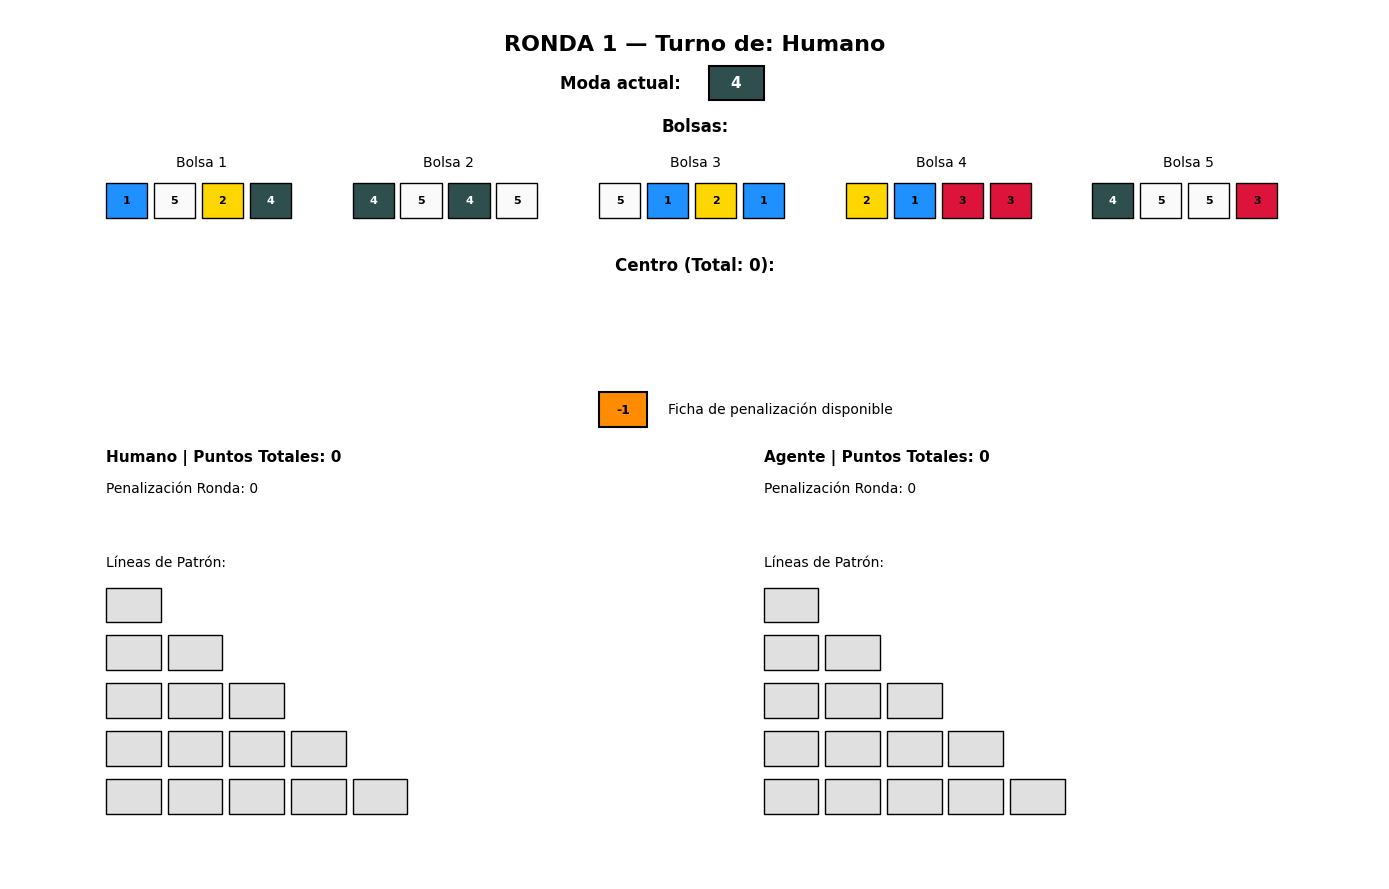


TURNO DEL HUMANO

JUGADAS DISPONIBLES:

  0 -> Bolsa 1    | Color 1 | Descarte
  1 -> Bolsa 1    | Color 1 | Fila 1
  2 -> Bolsa 1    | Color 1 | Fila 2
  3 -> Bolsa 1    | Color 1 | Fila 3
  4 -> Bolsa 1    | Color 1 | Fila 4
  5 -> Bolsa 1    | Color 1 | Fila 5
  6 -> Bolsa 1    | Color 2 | Descarte
  7 -> Bolsa 1    | Color 2 | Fila 1
  8 -> Bolsa 1    | Color 2 | Fila 2
  9 -> Bolsa 1    | Color 2 | Fila 3
 10 -> Bolsa 1    | Color 2 | Fila 4
 11 -> Bolsa 1    | Color 2 | Fila 5
 12 -> Bolsa 1    | Color 4 | Descarte
 13 -> Bolsa 1    | Color 4 | Fila 1
 14 -> Bolsa 1    | Color 4 | Fila 2
 15 -> Bolsa 1    | Color 4 | Fila 3
 16 -> Bolsa 1    | Color 4 | Fila 4
 17 -> Bolsa 1    | Color 4 | Fila 5
 18 -> Bolsa 1    | Color 5 | Descarte
 19 -> Bolsa 1    | Color 5 | Fila 1
 20 -> Bolsa 1    | Color 5 | Fila 2
 21 -> Bolsa 1    | Color 5 | Fila 3
 22 -> Bolsa 1    | Color 5 | Fila 4
 23 -> Bolsa 1    | Color 5 | Fila 5
 24 -> Bolsa 2    | Color 4 | Descarte
 25 -> Bolsa 2    | Colo

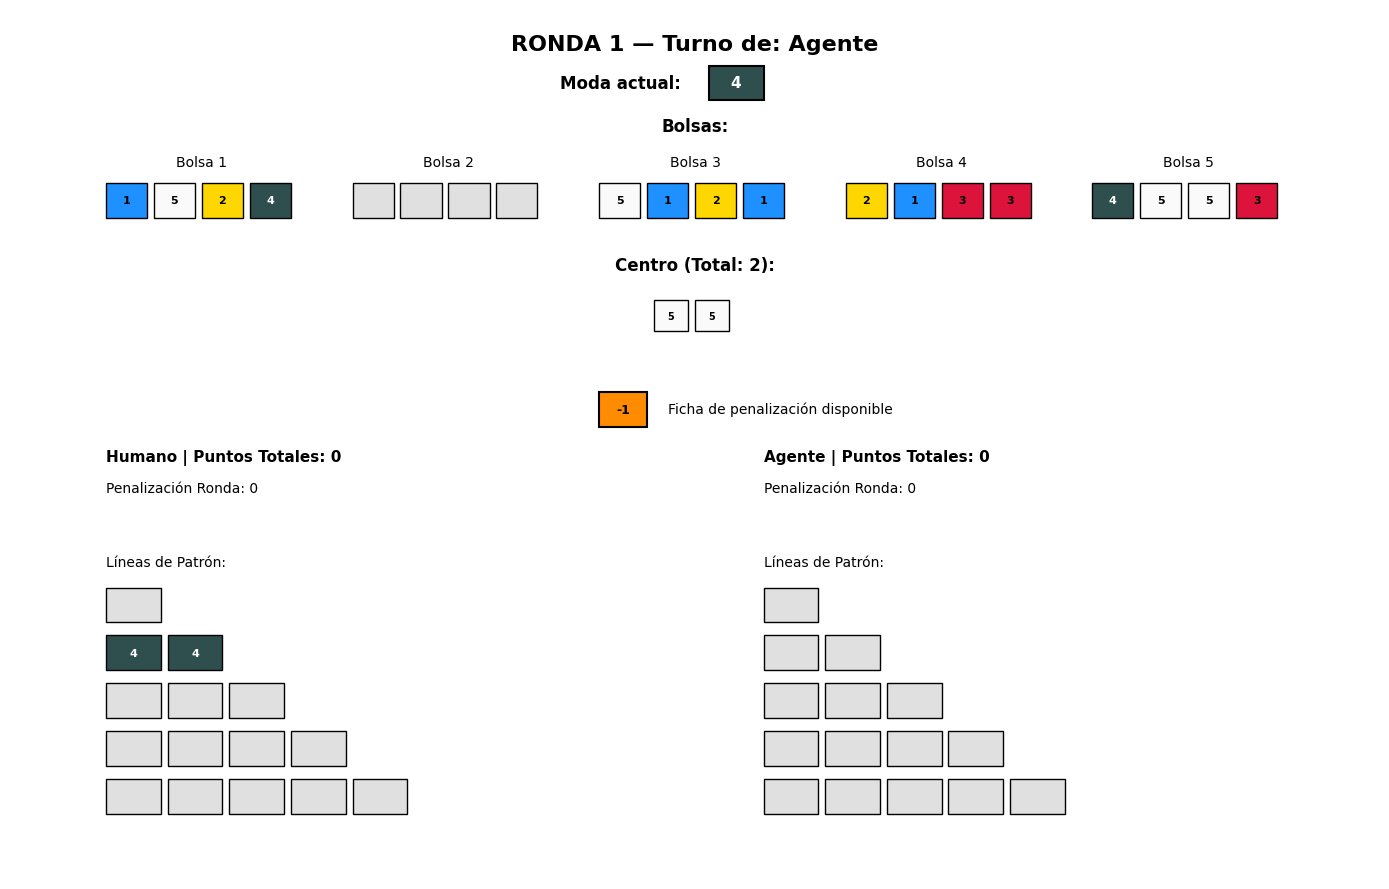


--------------------------------------
TURNO DEL AGENTE
--------------------------------------
Jugada elegida: (0, 5, 5)

Turno de Agente: (0, 5, 5)
Tomaste la ficha blanca: -1 punto.
Fichas tomadas: 2
Fichas sobrantes: 0


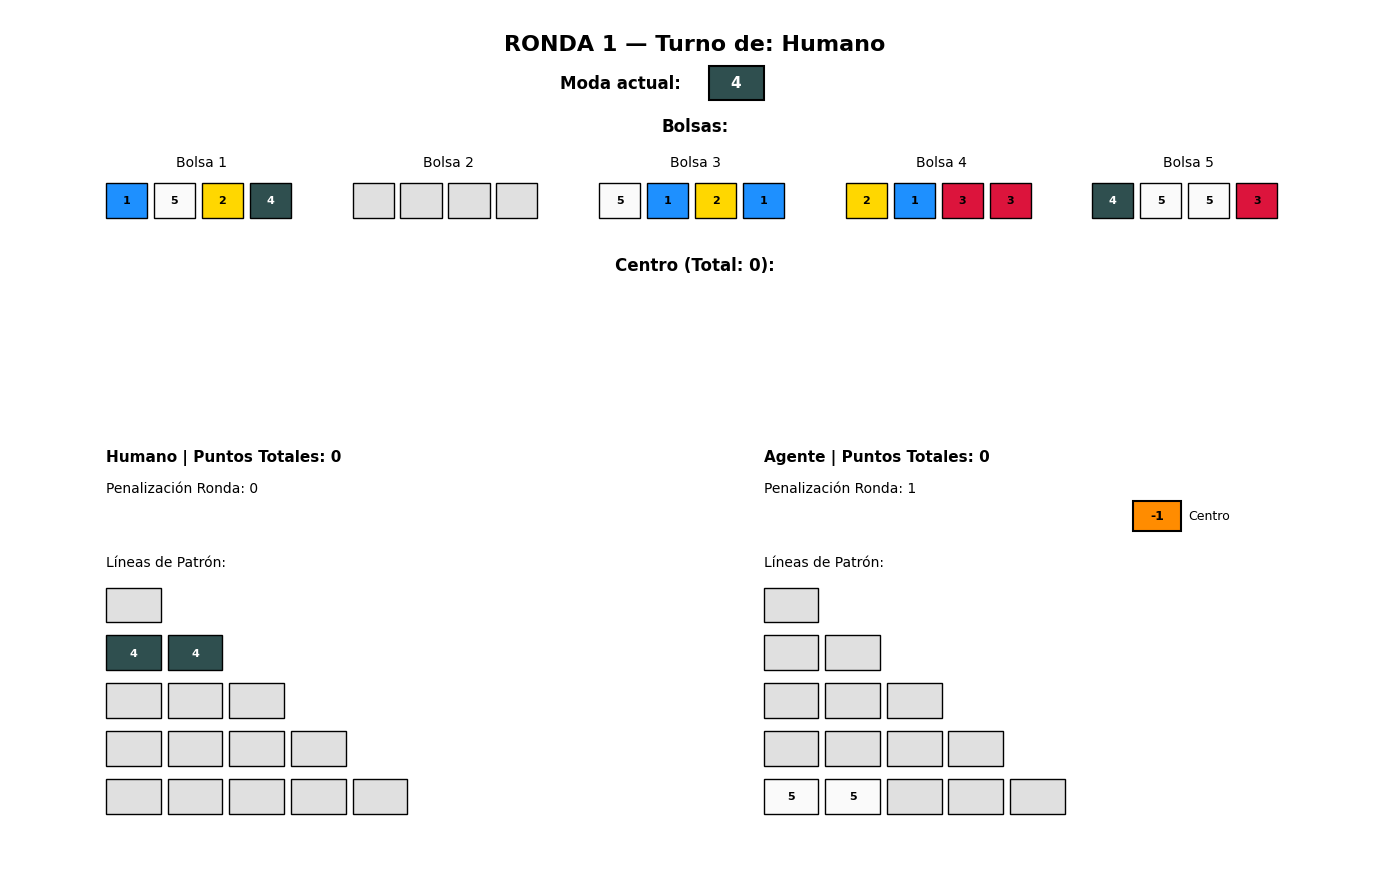


TURNO DEL HUMANO

JUGADAS DISPONIBLES:

  0 -> Bolsa 1    | Color 1 | Descarte
  1 -> Bolsa 1    | Color 1 | Fila 1
  2 -> Bolsa 1    | Color 1 | Fila 3
  3 -> Bolsa 1    | Color 1 | Fila 4
  4 -> Bolsa 1    | Color 1 | Fila 5
  5 -> Bolsa 1    | Color 2 | Descarte
  6 -> Bolsa 1    | Color 2 | Fila 1
  7 -> Bolsa 1    | Color 2 | Fila 3
  8 -> Bolsa 1    | Color 2 | Fila 4
  9 -> Bolsa 1    | Color 2 | Fila 5
 10 -> Bolsa 1    | Color 4 | Descarte
 11 -> Bolsa 1    | Color 4 | Fila 1
 12 -> Bolsa 1    | Color 4 | Fila 3
 13 -> Bolsa 1    | Color 4 | Fila 4
 14 -> Bolsa 1    | Color 4 | Fila 5
 15 -> Bolsa 1    | Color 5 | Descarte
 16 -> Bolsa 1    | Color 5 | Fila 1
 17 -> Bolsa 1    | Color 5 | Fila 3
 18 -> Bolsa 1    | Color 5 | Fila 4
 19 -> Bolsa 1    | Color 5 | Fila 5
 20 -> Bolsa 3    | Color 1 | Descarte
 21 -> Bolsa 3    | Color 1 | Fila 1
 22 -> Bolsa 3    | Color 1 | Fila 3
 23 -> Bolsa 3    | Color 1 | Fila 4
 24 -> Bolsa 3    | Color 1 | Fila 5
 25 -> Bolsa 3    | Colo

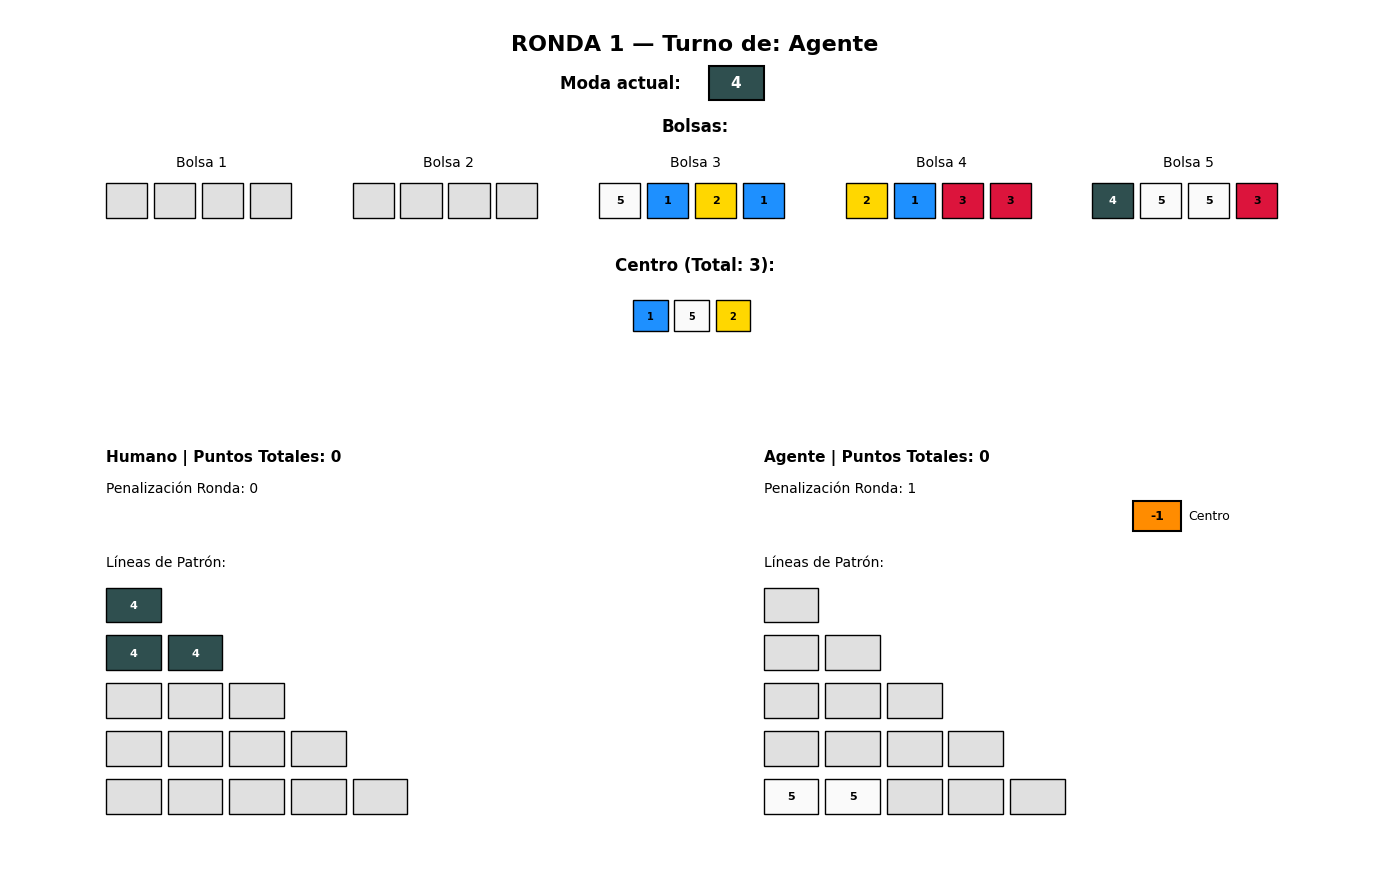


--------------------------------------
TURNO DEL AGENTE
--------------------------------------
Jugada elegida: (0, 5, 5)

Turno de Agente: (0, 5, 5)
Fichas tomadas: 1
Fichas sobrantes: 0


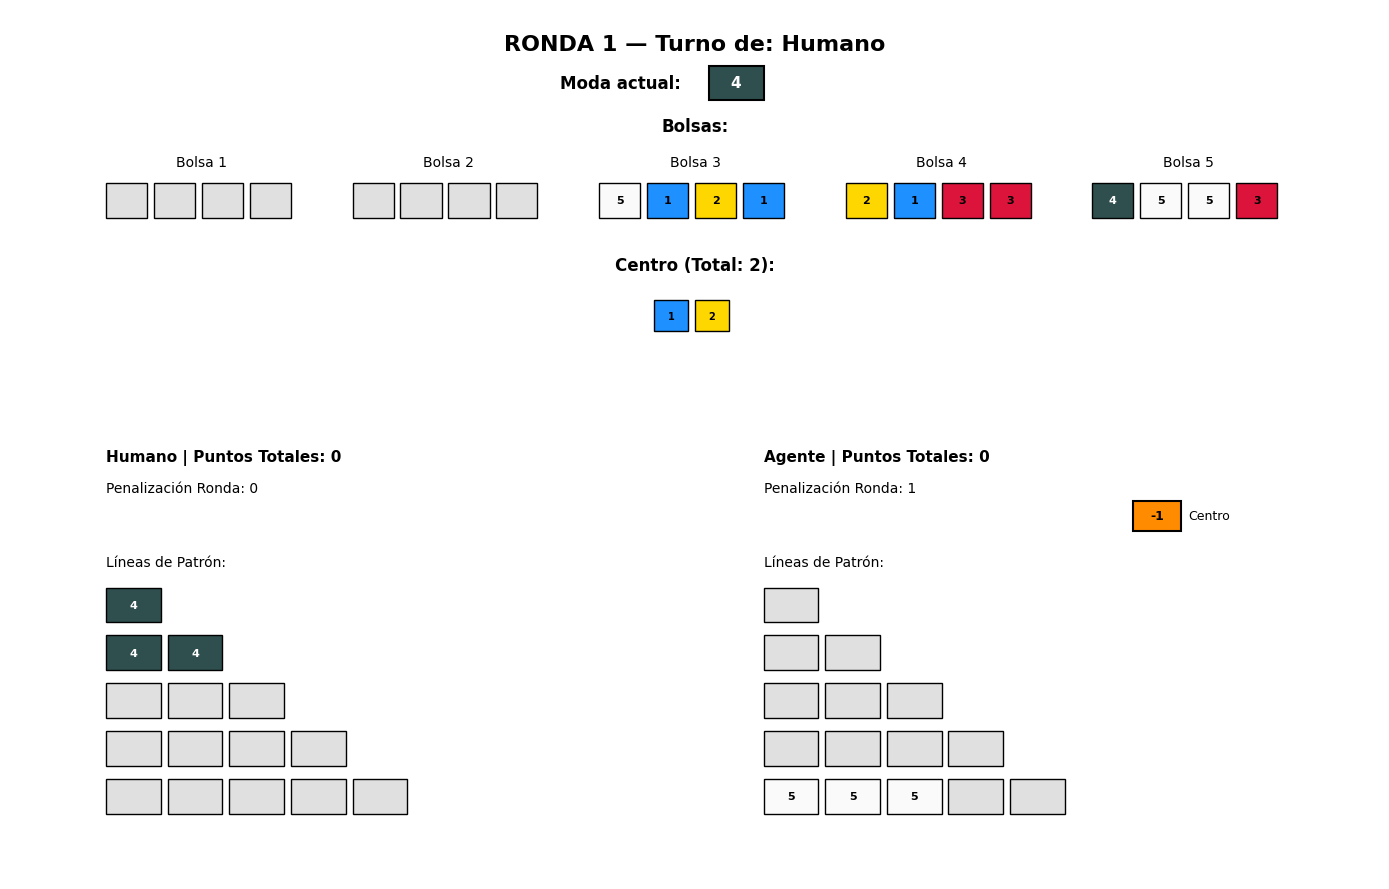


TURNO DEL HUMANO

JUGADAS DISPONIBLES:

  0 -> Centro     | Color 1 | Descarte
  1 -> Centro     | Color 1 | Fila 3
  2 -> Centro     | Color 1 | Fila 4
  3 -> Centro     | Color 1 | Fila 5
  4 -> Centro     | Color 2 | Descarte
  5 -> Centro     | Color 2 | Fila 3
  6 -> Centro     | Color 2 | Fila 4
  7 -> Centro     | Color 2 | Fila 5
  8 -> Bolsa 3    | Color 1 | Descarte
  9 -> Bolsa 3    | Color 1 | Fila 3
 10 -> Bolsa 3    | Color 1 | Fila 4
 11 -> Bolsa 3    | Color 1 | Fila 5
 12 -> Bolsa 3    | Color 2 | Descarte
 13 -> Bolsa 3    | Color 2 | Fila 3
 14 -> Bolsa 3    | Color 2 | Fila 4
 15 -> Bolsa 3    | Color 2 | Fila 5
 16 -> Bolsa 3    | Color 5 | Descarte
 17 -> Bolsa 3    | Color 5 | Fila 3
 18 -> Bolsa 3    | Color 5 | Fila 4
 19 -> Bolsa 3    | Color 5 | Fila 5
 20 -> Bolsa 4    | Color 1 | Descarte
 21 -> Bolsa 4    | Color 1 | Fila 3
 22 -> Bolsa 4    | Color 1 | Fila 4
 23 -> Bolsa 4    | Color 1 | Fila 5
 24 -> Bolsa 4    | Color 2 | Descarte
 25 -> Bolsa 4    | 

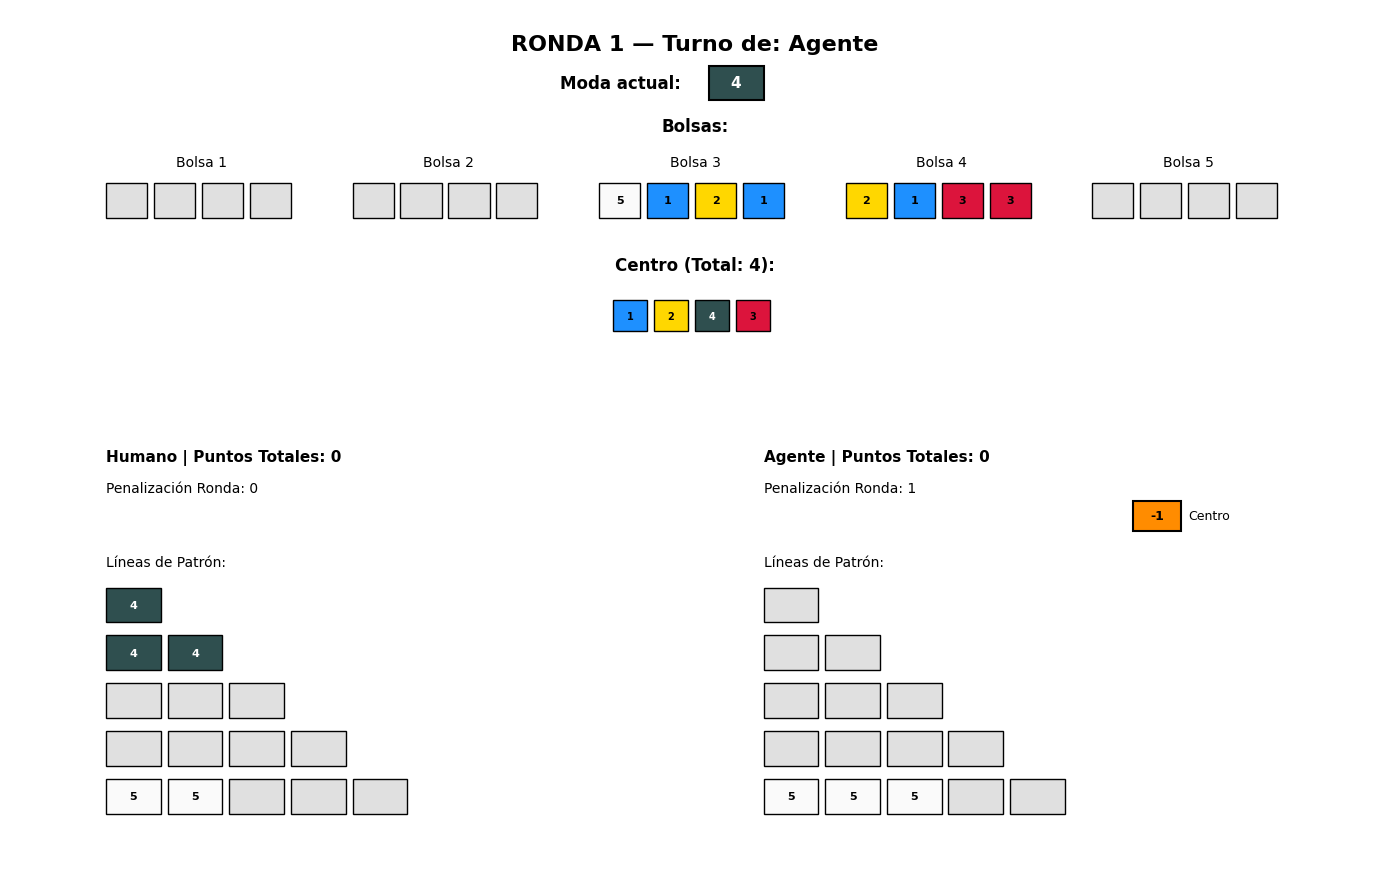


--------------------------------------
TURNO DEL AGENTE
--------------------------------------
Jugada elegida: (0, 3, 3)

Turno de Agente: (0, 3, 3)
Fichas tomadas: 1
Fichas sobrantes: 0


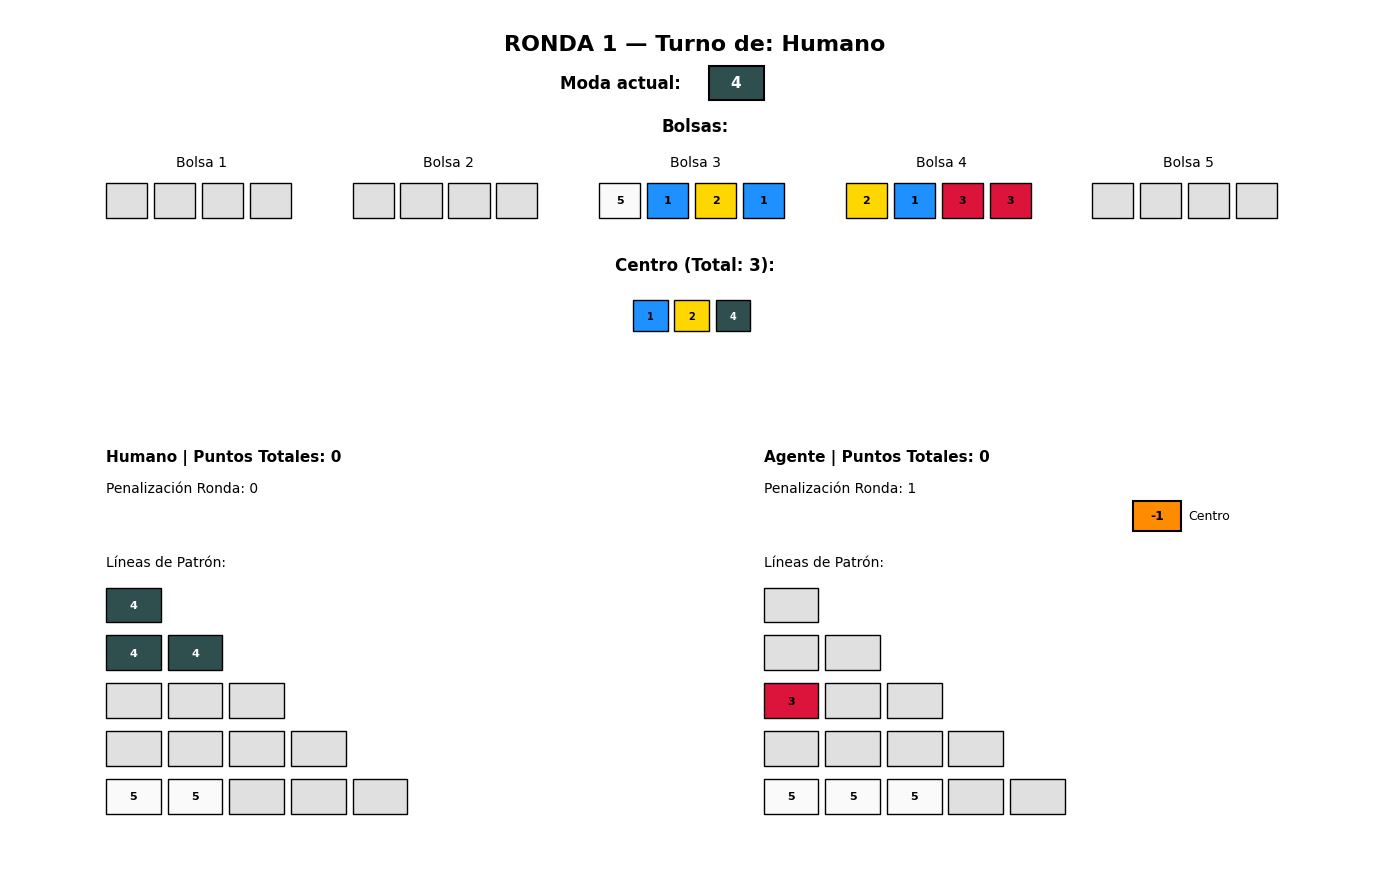


TURNO DEL HUMANO

JUGADAS DISPONIBLES:

  0 -> Centro     | Color 1 | Descarte
  1 -> Centro     | Color 1 | Fila 3
  2 -> Centro     | Color 1 | Fila 4
  3 -> Centro     | Color 2 | Descarte
  4 -> Centro     | Color 2 | Fila 3
  5 -> Centro     | Color 2 | Fila 4
  6 -> Centro     | Color 4 | Descarte
  7 -> Centro     | Color 4 | Fila 3
  8 -> Centro     | Color 4 | Fila 4
  9 -> Bolsa 3    | Color 1 | Descarte
 10 -> Bolsa 3    | Color 1 | Fila 3
 11 -> Bolsa 3    | Color 1 | Fila 4
 12 -> Bolsa 3    | Color 2 | Descarte
 13 -> Bolsa 3    | Color 2 | Fila 3
 14 -> Bolsa 3    | Color 2 | Fila 4
 15 -> Bolsa 3    | Color 5 | Descarte
 16 -> Bolsa 3    | Color 5 | Fila 3
 17 -> Bolsa 3    | Color 5 | Fila 4
 18 -> Bolsa 3    | Color 5 | Fila 5
 19 -> Bolsa 4    | Color 1 | Descarte
 20 -> Bolsa 4    | Color 1 | Fila 3
 21 -> Bolsa 4    | Color 1 | Fila 4
 22 -> Bolsa 4    | Color 2 | Descarte
 23 -> Bolsa 4    | Color 2 | Fila 3
 24 -> Bolsa 4    | Color 2 | Fila 4
 25 -> Bolsa 4    

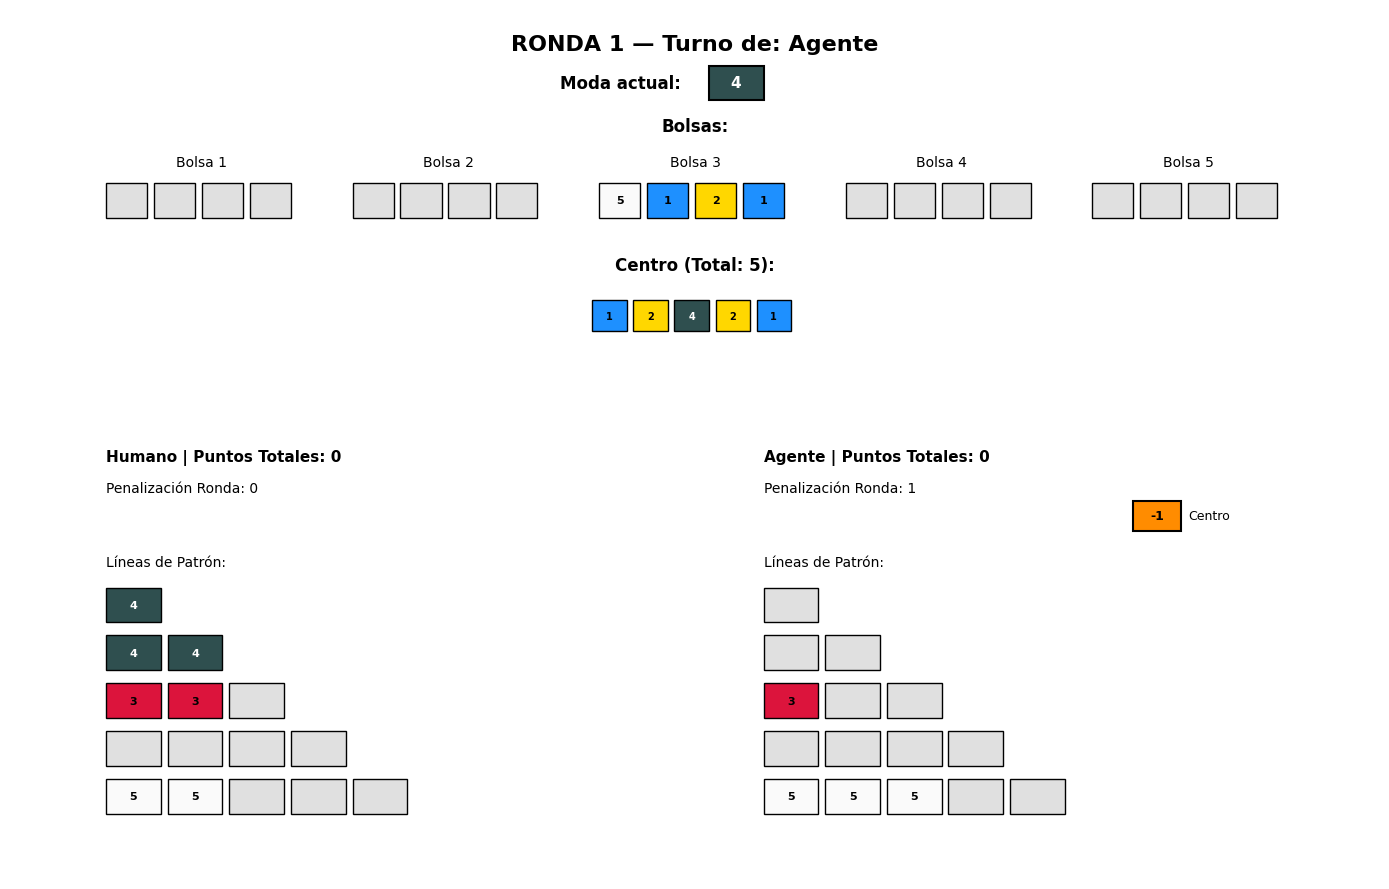


--------------------------------------
TURNO DEL AGENTE
--------------------------------------
Jugada elegida: (0, 1, 4)

Turno de Agente: (0, 1, 4)
Fichas tomadas: 2
Fichas sobrantes: 0


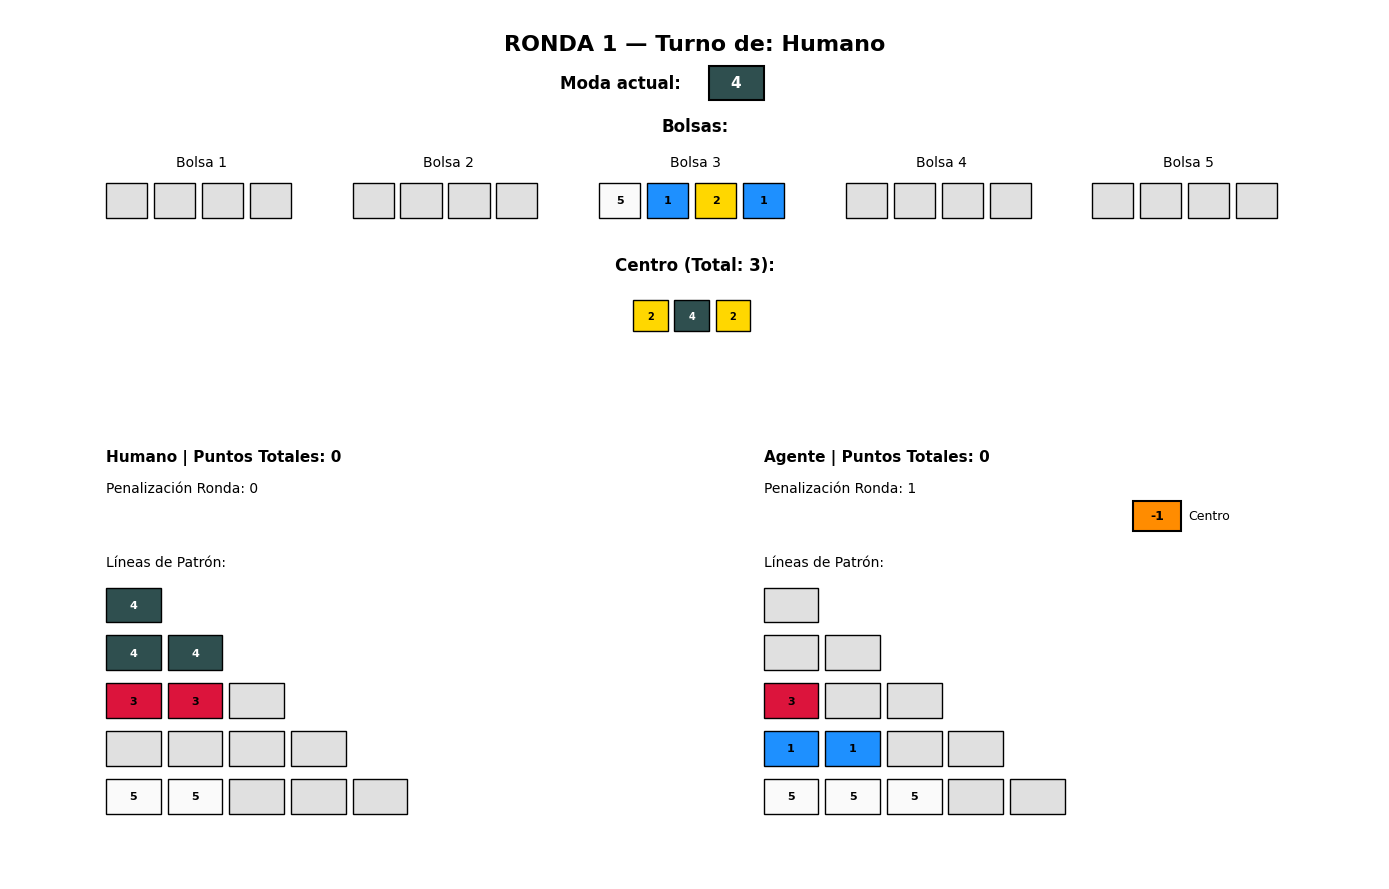


TURNO DEL HUMANO

JUGADAS DISPONIBLES:

  0 -> Centro     | Color 2 | Descarte
  1 -> Centro     | Color 2 | Fila 4
  2 -> Centro     | Color 4 | Descarte
  3 -> Centro     | Color 4 | Fila 4
  4 -> Bolsa 3    | Color 1 | Descarte
  5 -> Bolsa 3    | Color 1 | Fila 4
  6 -> Bolsa 3    | Color 2 | Descarte
  7 -> Bolsa 3    | Color 2 | Fila 4
  8 -> Bolsa 3    | Color 5 | Descarte
  9 -> Bolsa 3    | Color 5 | Fila 4
 10 -> Bolsa 3    | Color 5 | Fila 5

Elige el número de la jugada: 10

Jugada elegida: (3, 5, 5)

Turno de Humano: (3, 5, 5)
Fichas tomadas: 1
Fichas sobrantes: 0


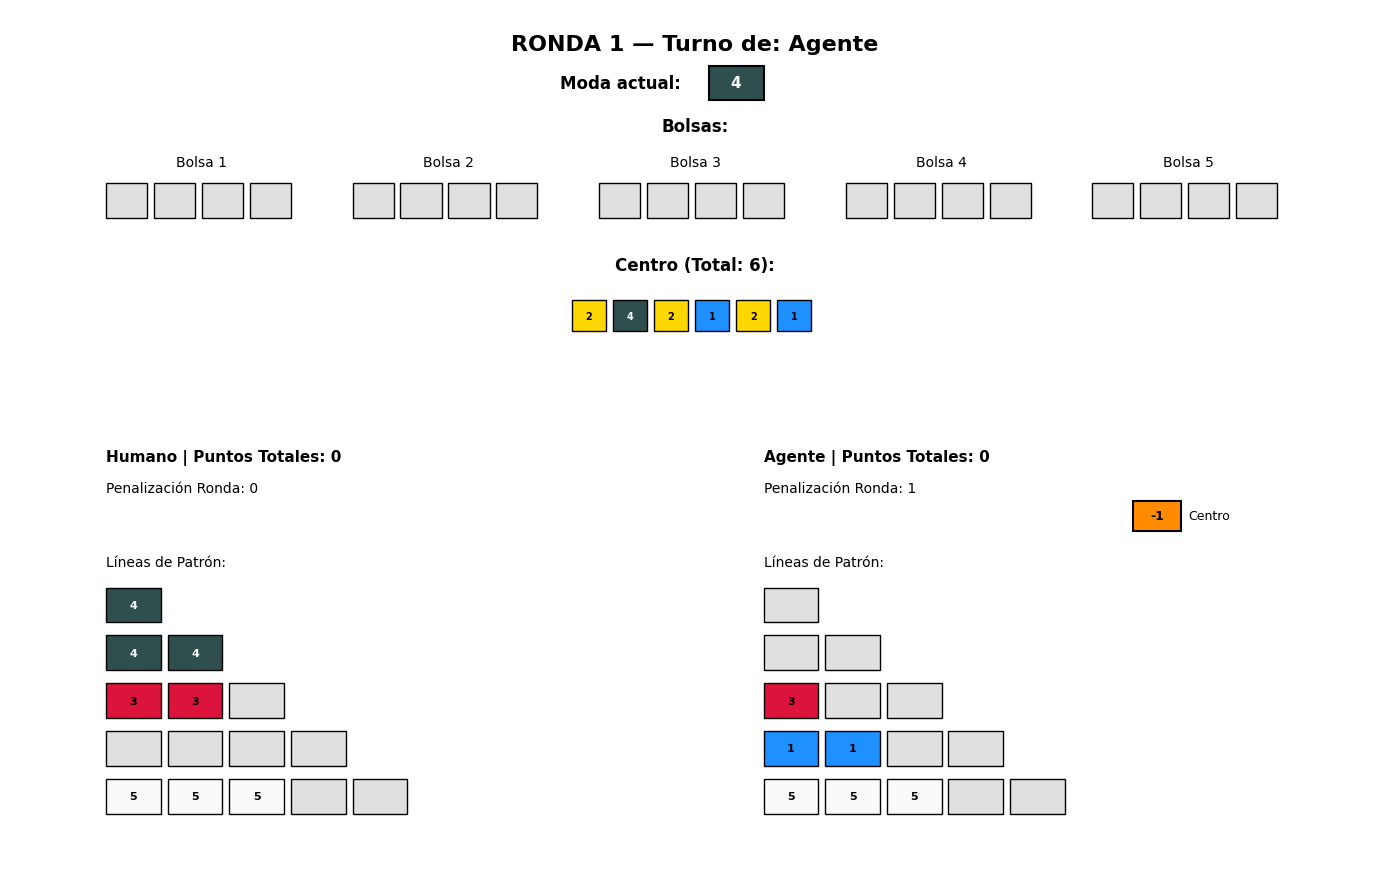


--------------------------------------
TURNO DEL AGENTE
--------------------------------------
Jugada elegida: (0, 1, 4)

Turno de Agente: (0, 1, 4)
Fichas tomadas: 2
Fichas sobrantes: 0


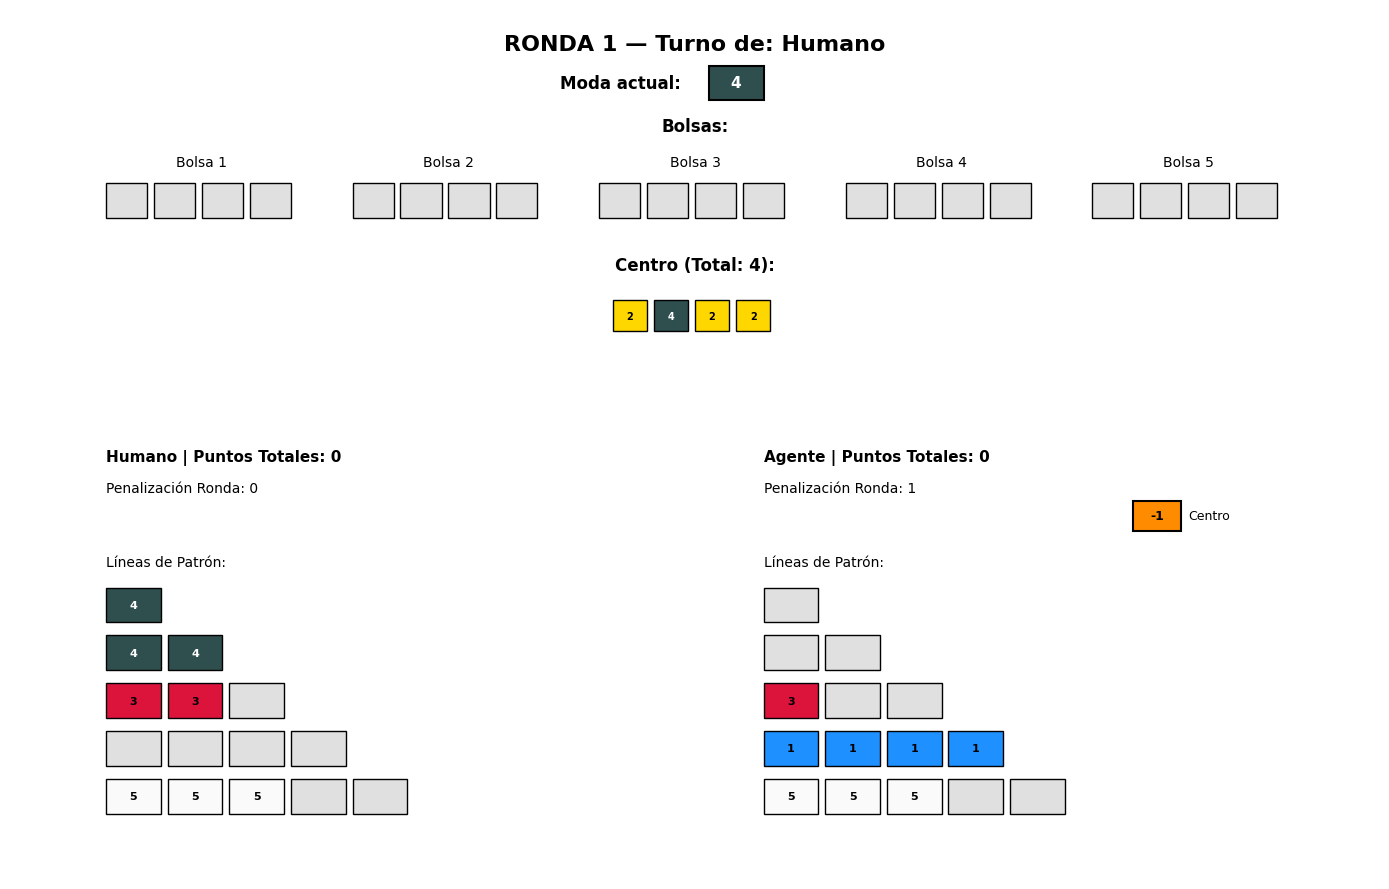


TURNO DEL HUMANO

JUGADAS DISPONIBLES:

  0 -> Centro     | Color 2 | Descarte
  1 -> Centro     | Color 2 | Fila 4
  2 -> Centro     | Color 4 | Descarte
  3 -> Centro     | Color 4 | Fila 4

Elige el número de la jugada: 1

Jugada elegida: (0, 2, 4)

Turno de Humano: (0, 2, 4)
Fichas tomadas: 3
Fichas sobrantes: 0


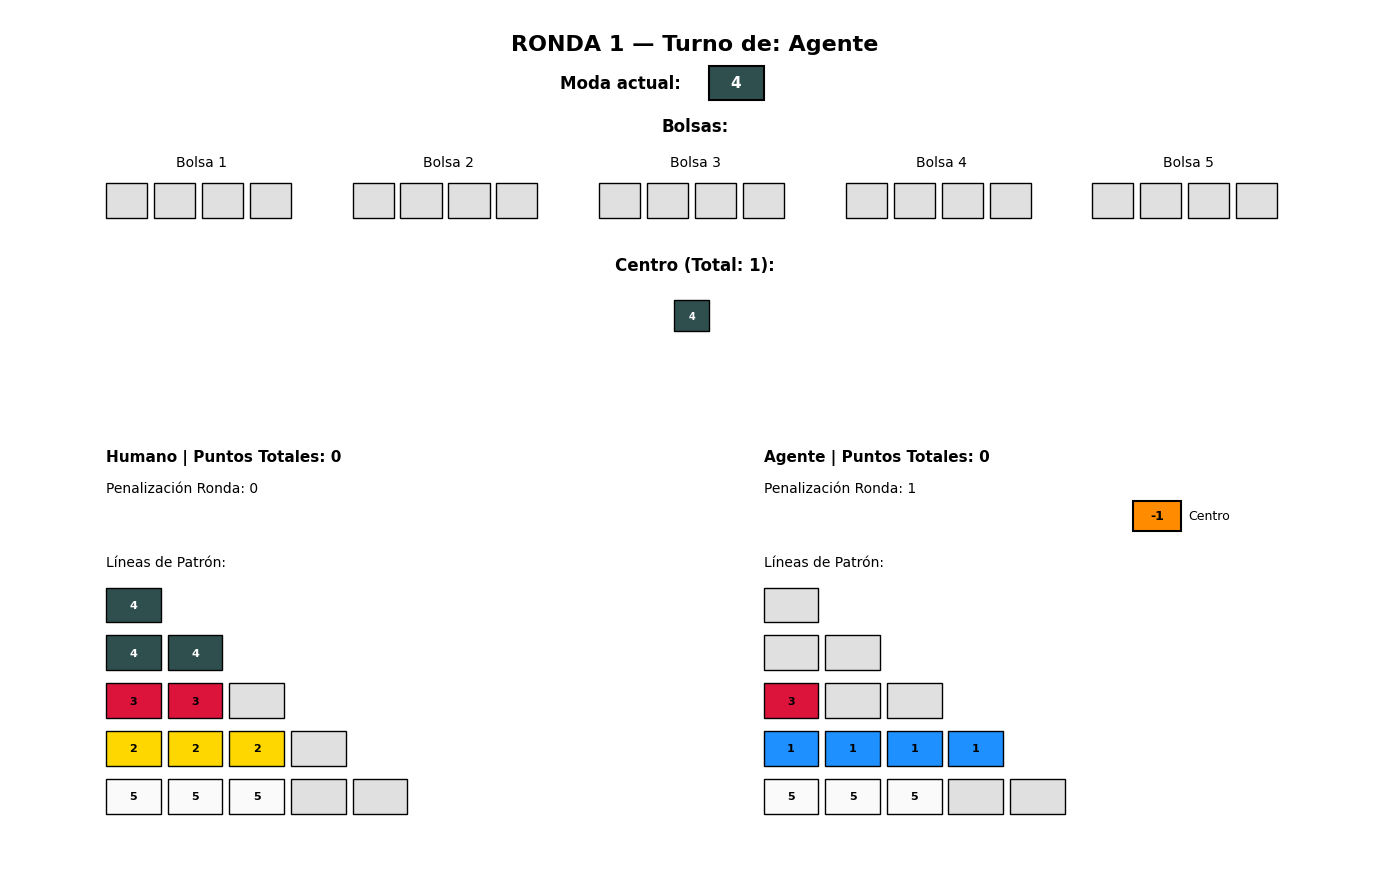


--------------------------------------
TURNO DEL AGENTE
--------------------------------------
Jugada elegida: (0, 4, 2)

Turno de Agente: (0, 4, 2)
Fichas tomadas: 1
Fichas sobrantes: 0

Resultados de la ronda 1
Moda: 4

Humano
Puntos por filas: 3
Puntos por moda: 3
Descuentos: 0
Puntos de la ronda: 6
Total acumulado: 6

Agente
Puntos por filas: 4
Puntos por moda: 1
Descuentos: 1
Puntos de la ronda: 4
Total acumulado: 4

========== RONDA 2 ==========
Moda de la ronda: 1


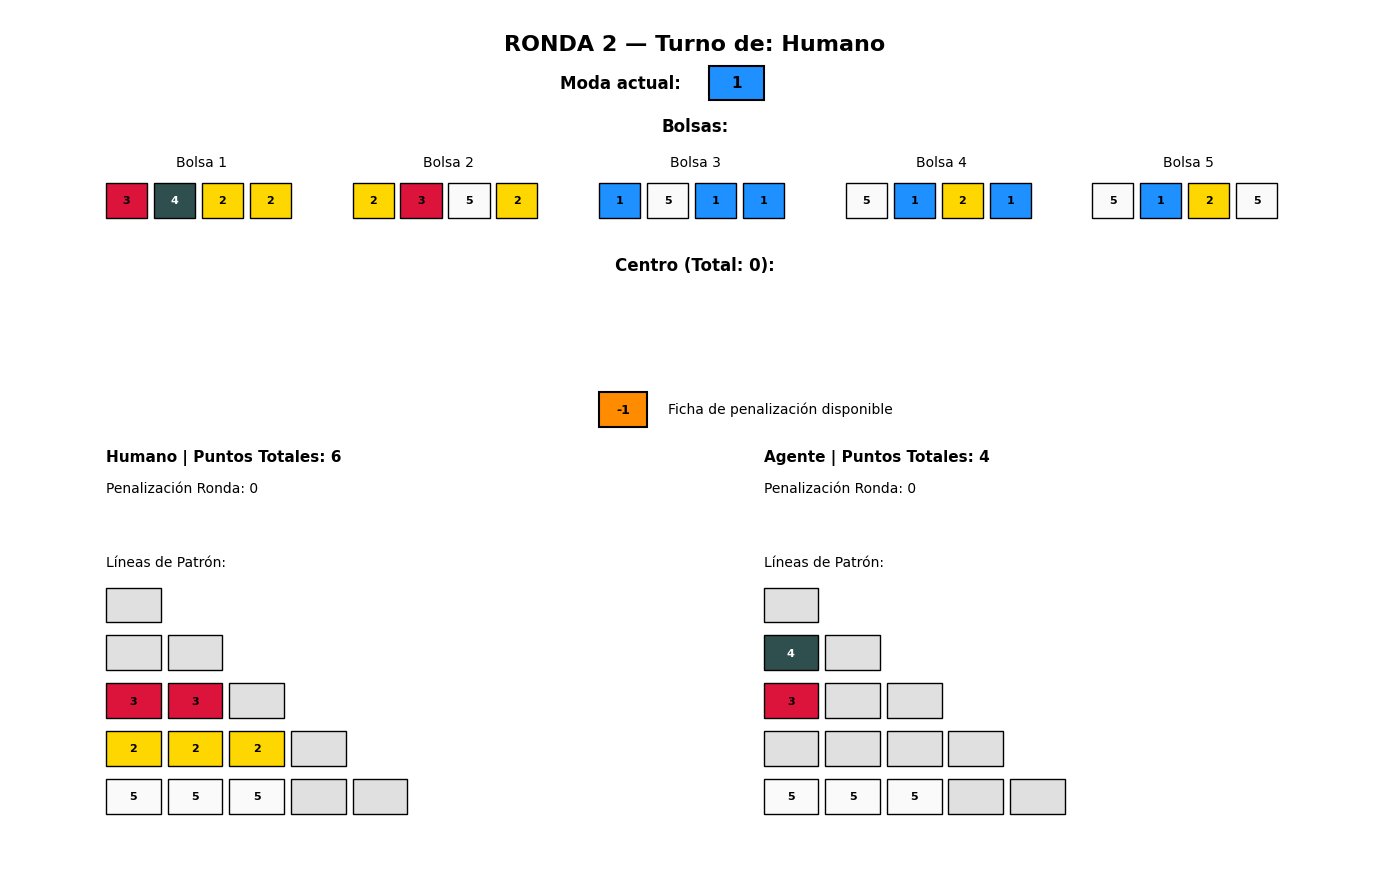


TURNO DEL HUMANO

JUGADAS DISPONIBLES:

  0 -> Bolsa 1    | Color 2 | Descarte
  1 -> Bolsa 1    | Color 2 | Fila 1
  2 -> Bolsa 1    | Color 2 | Fila 2
  3 -> Bolsa 1    | Color 2 | Fila 4
  4 -> Bolsa 1    | Color 3 | Descarte
  5 -> Bolsa 1    | Color 3 | Fila 1
  6 -> Bolsa 1    | Color 3 | Fila 2
  7 -> Bolsa 1    | Color 3 | Fila 3
  8 -> Bolsa 1    | Color 4 | Descarte
  9 -> Bolsa 1    | Color 4 | Fila 1
 10 -> Bolsa 1    | Color 4 | Fila 2
 11 -> Bolsa 2    | Color 2 | Descarte
 12 -> Bolsa 2    | Color 2 | Fila 1
 13 -> Bolsa 2    | Color 2 | Fila 2
 14 -> Bolsa 2    | Color 2 | Fila 4
 15 -> Bolsa 2    | Color 3 | Descarte
 16 -> Bolsa 2    | Color 3 | Fila 1
 17 -> Bolsa 2    | Color 3 | Fila 2
 18 -> Bolsa 2    | Color 3 | Fila 3
 19 -> Bolsa 2    | Color 5 | Descarte
 20 -> Bolsa 2    | Color 5 | Fila 1
 21 -> Bolsa 2    | Color 5 | Fila 2
 22 -> Bolsa 2    | Color 5 | Fila 5
 23 -> Bolsa 3    | Color 1 | Descarte
 24 -> Bolsa 3    | Color 1 | Fila 1
 25 -> Bolsa 3    | 

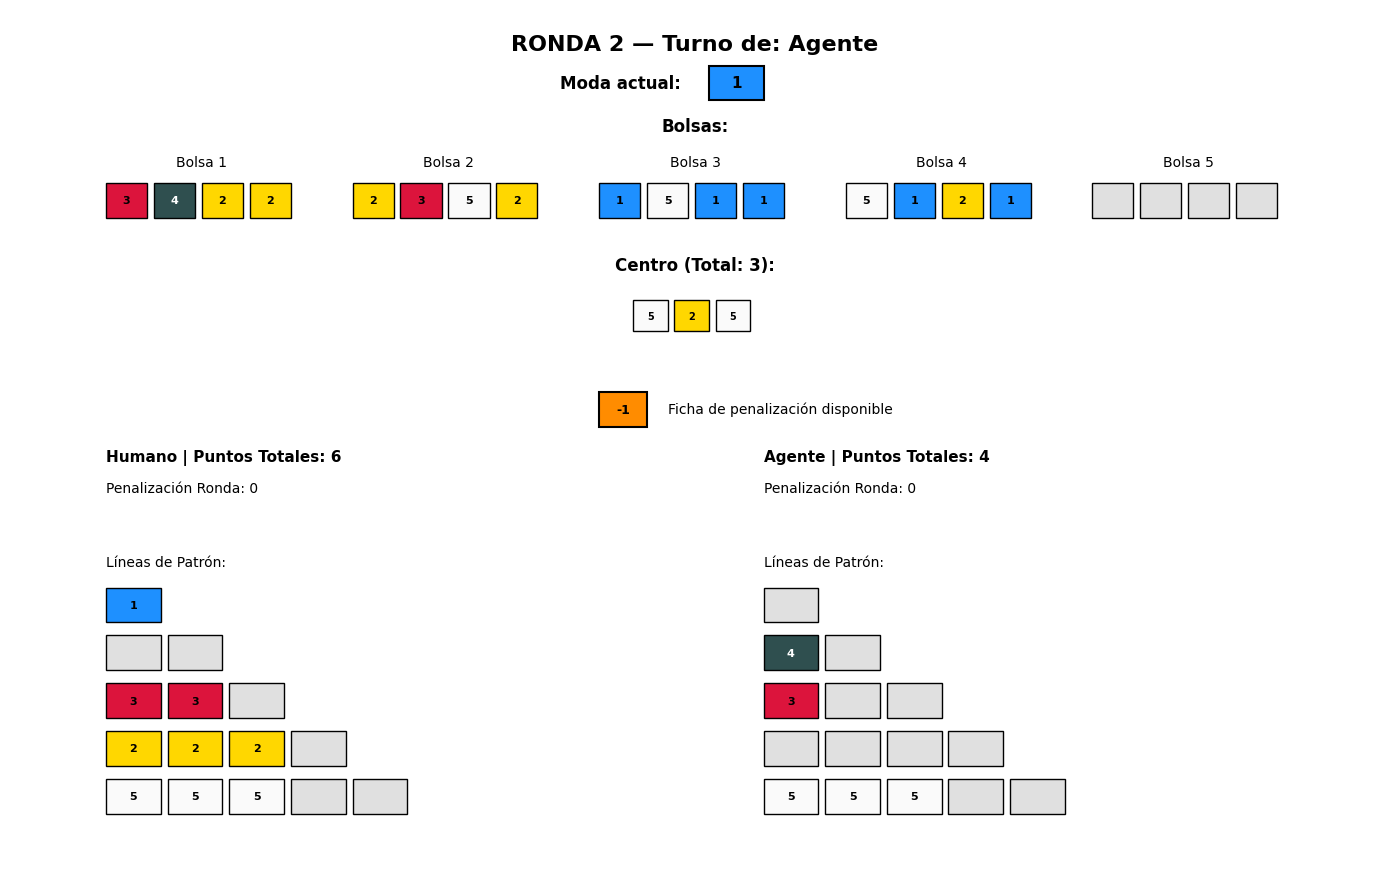


--------------------------------------
TURNO DEL AGENTE
--------------------------------------
Jugada elegida: (1, 3, 3)

Turno de Agente: (1, 3, 3)
Fichas tomadas: 1
Fichas sobrantes: 0


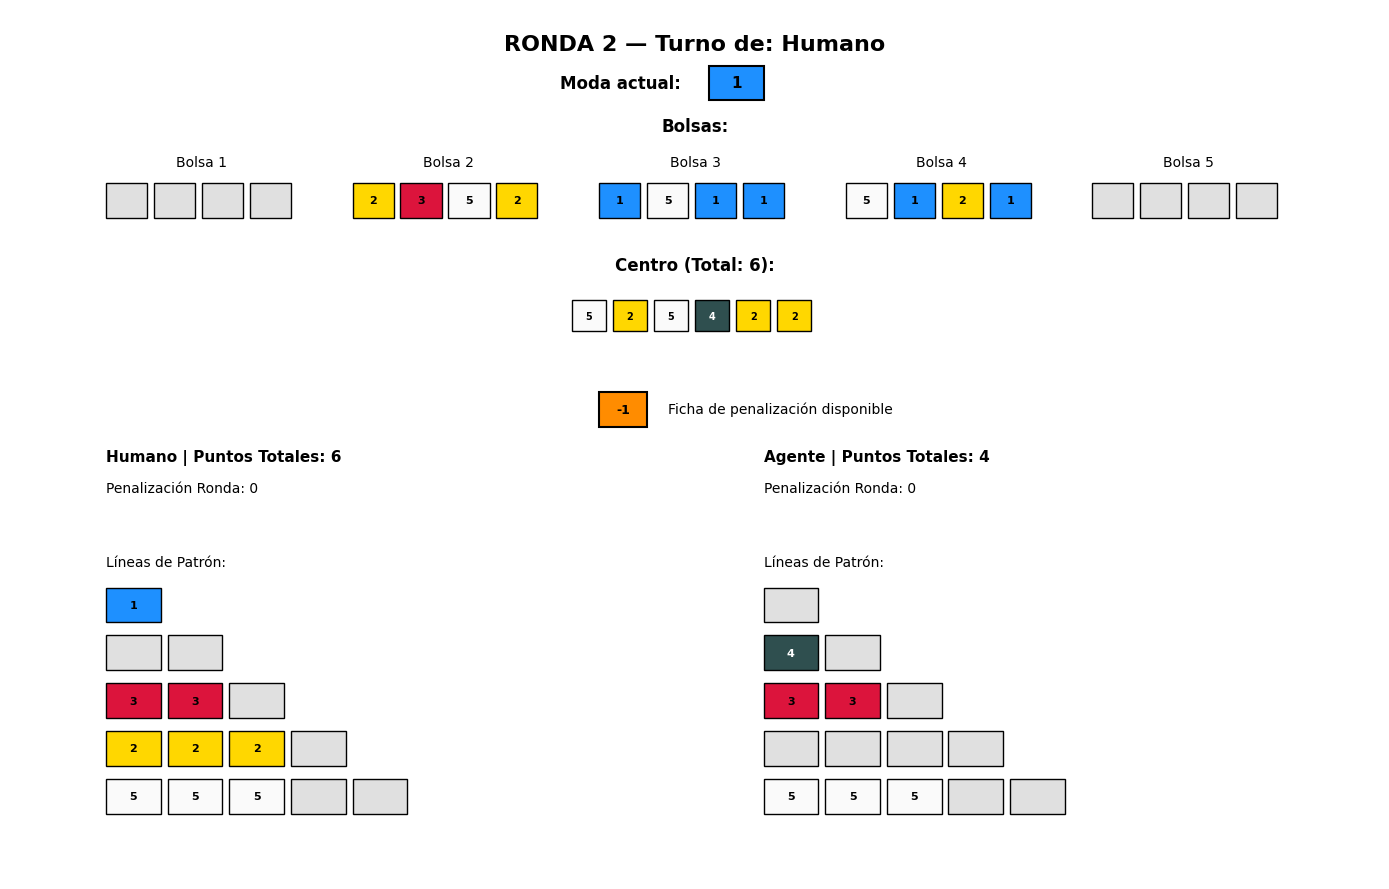


TURNO DEL HUMANO

JUGADAS DISPONIBLES:

  0 -> Centro     | Color 2 | Descarte
  1 -> Centro     | Color 2 | Fila 2
  2 -> Centro     | Color 2 | Fila 4
  3 -> Centro     | Color 4 | Descarte
  4 -> Centro     | Color 4 | Fila 2
  5 -> Centro     | Color 5 | Descarte
  6 -> Centro     | Color 5 | Fila 2
  7 -> Centro     | Color 5 | Fila 5
  8 -> Bolsa 2    | Color 2 | Descarte
  9 -> Bolsa 2    | Color 2 | Fila 2
 10 -> Bolsa 2    | Color 2 | Fila 4
 11 -> Bolsa 2    | Color 3 | Descarte
 12 -> Bolsa 2    | Color 3 | Fila 2
 13 -> Bolsa 2    | Color 3 | Fila 3
 14 -> Bolsa 2    | Color 5 | Descarte
 15 -> Bolsa 2    | Color 5 | Fila 2
 16 -> Bolsa 2    | Color 5 | Fila 5
 17 -> Bolsa 3    | Color 1 | Descarte
 18 -> Bolsa 3    | Color 1 | Fila 2
 19 -> Bolsa 3    | Color 5 | Descarte
 20 -> Bolsa 3    | Color 5 | Fila 2
 21 -> Bolsa 3    | Color 5 | Fila 5
 22 -> Bolsa 4    | Color 1 | Descarte
 23 -> Bolsa 4    | Color 1 | Fila 2
 24 -> Bolsa 4    | Color 2 | Descarte
 25 -> Bolsa 4

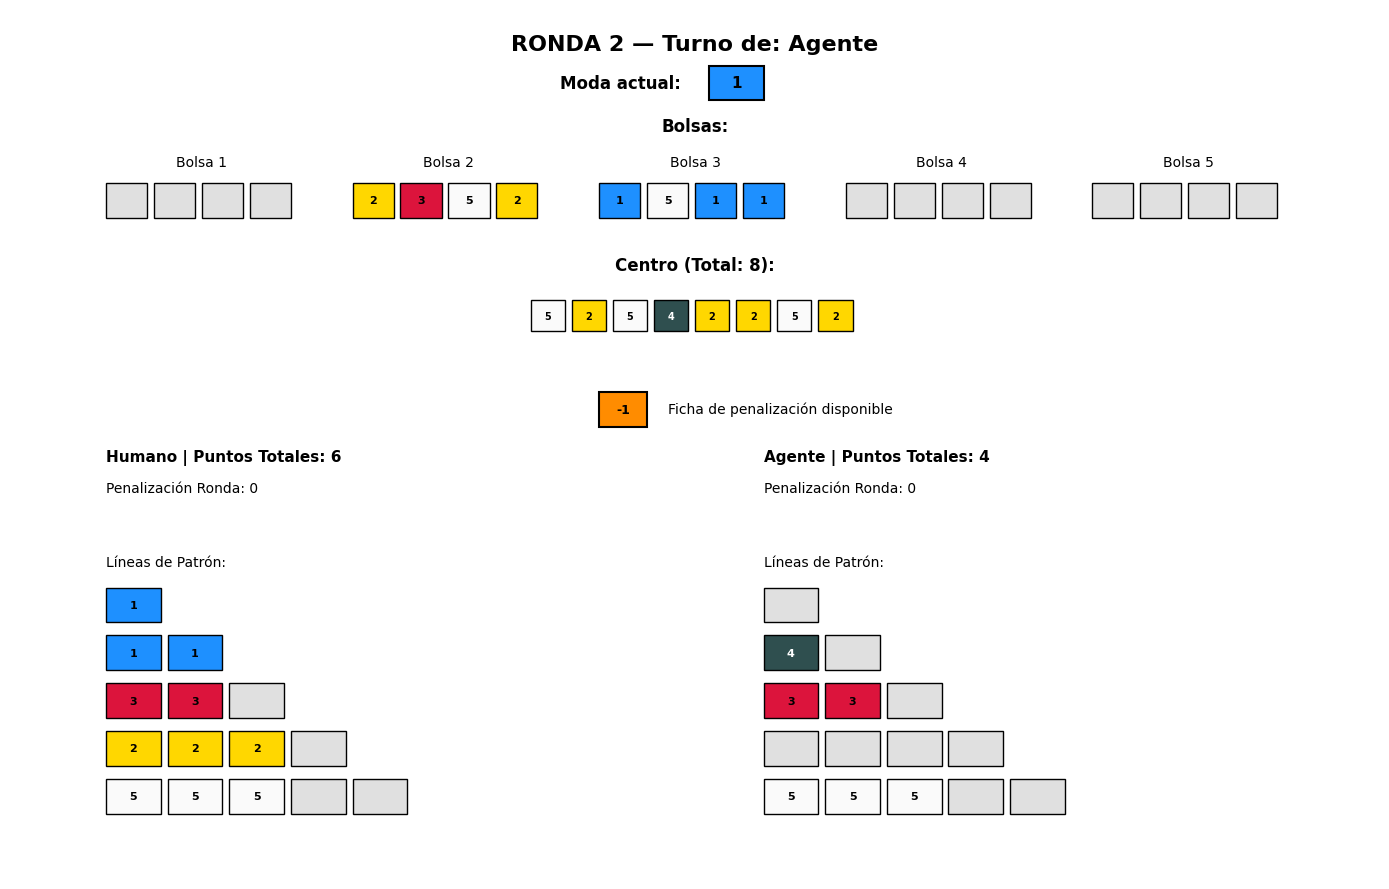


--------------------------------------
TURNO DEL AGENTE
--------------------------------------
Jugada elegida: (0, 5, 5)

Turno de Agente: (0, 5, 5)
Tomaste la ficha blanca: -1 punto.
Fichas tomadas: 3
Fichas sobrantes: 1


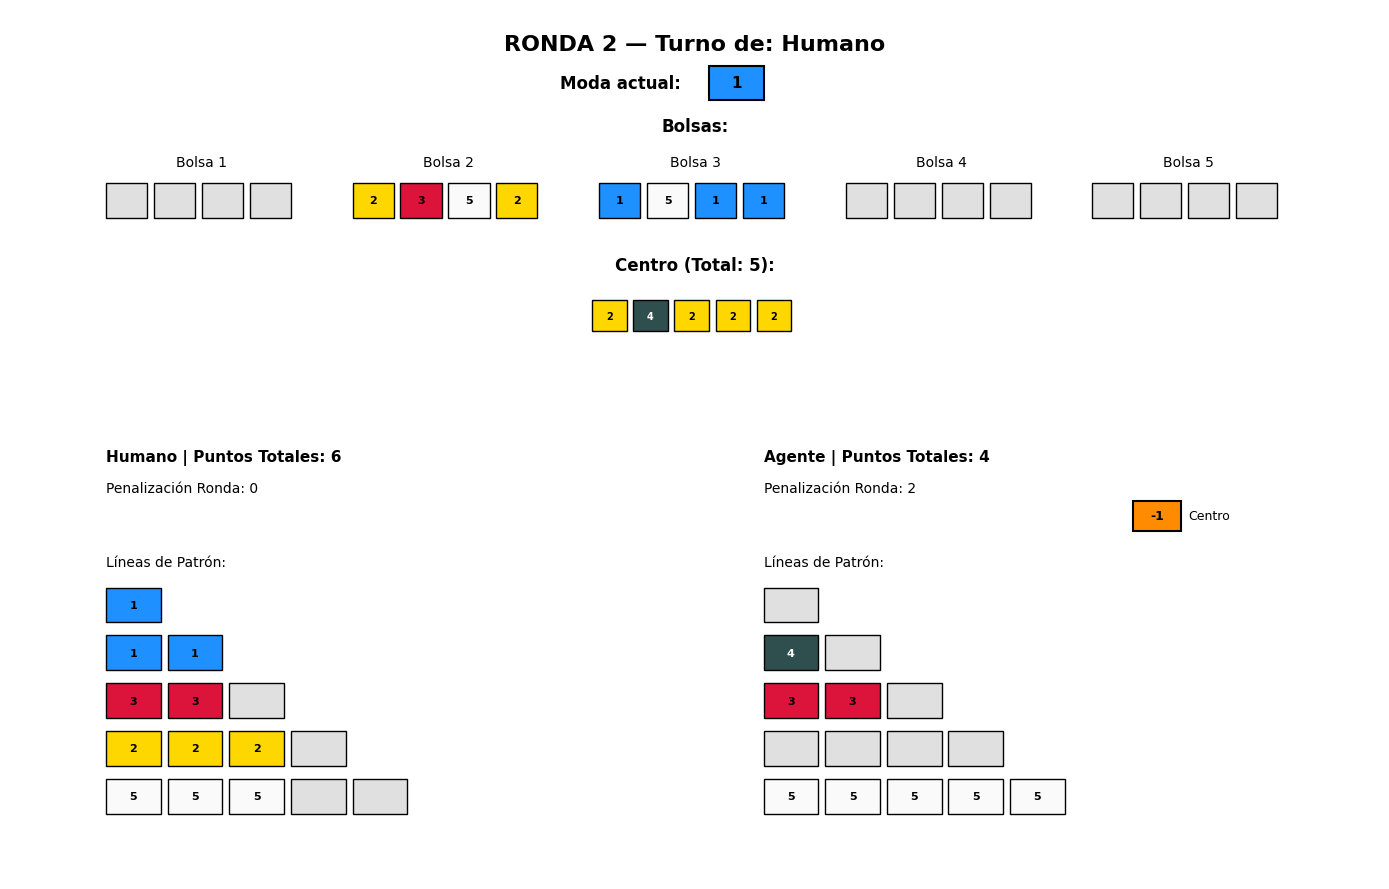


TURNO DEL HUMANO

JUGADAS DISPONIBLES:

  0 -> Centro     | Color 2 | Descarte
  1 -> Centro     | Color 2 | Fila 4
  2 -> Centro     | Color 4 | Descarte
  3 -> Bolsa 2    | Color 2 | Descarte
  4 -> Bolsa 2    | Color 2 | Fila 4
  5 -> Bolsa 2    | Color 3 | Descarte
  6 -> Bolsa 2    | Color 3 | Fila 3
  7 -> Bolsa 2    | Color 5 | Descarte
  8 -> Bolsa 2    | Color 5 | Fila 5
  9 -> Bolsa 3    | Color 1 | Descarte
 10 -> Bolsa 3    | Color 5 | Descarte
 11 -> Bolsa 3    | Color 5 | Fila 5

Elige el número de la jugada: 6

Jugada elegida: (2, 3, 3)

Turno de Humano: (2, 3, 3)
Fichas tomadas: 1
Fichas sobrantes: 0


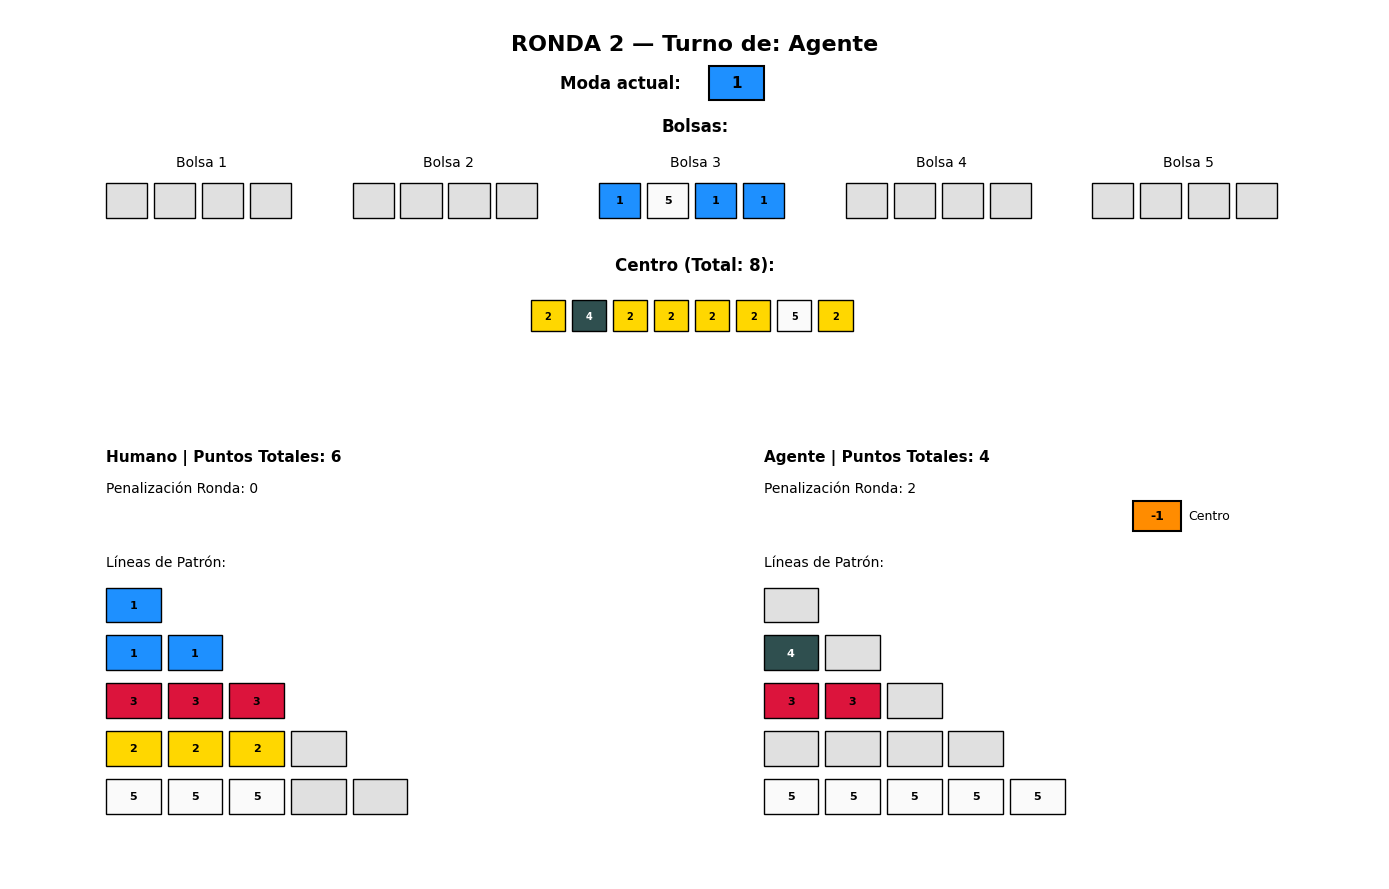


--------------------------------------
TURNO DEL AGENTE
--------------------------------------
Jugada elegida: (0, 4, 4)

Turno de Agente: (0, 4, 4)
Fichas tomadas: 1
Fichas sobrantes: 0


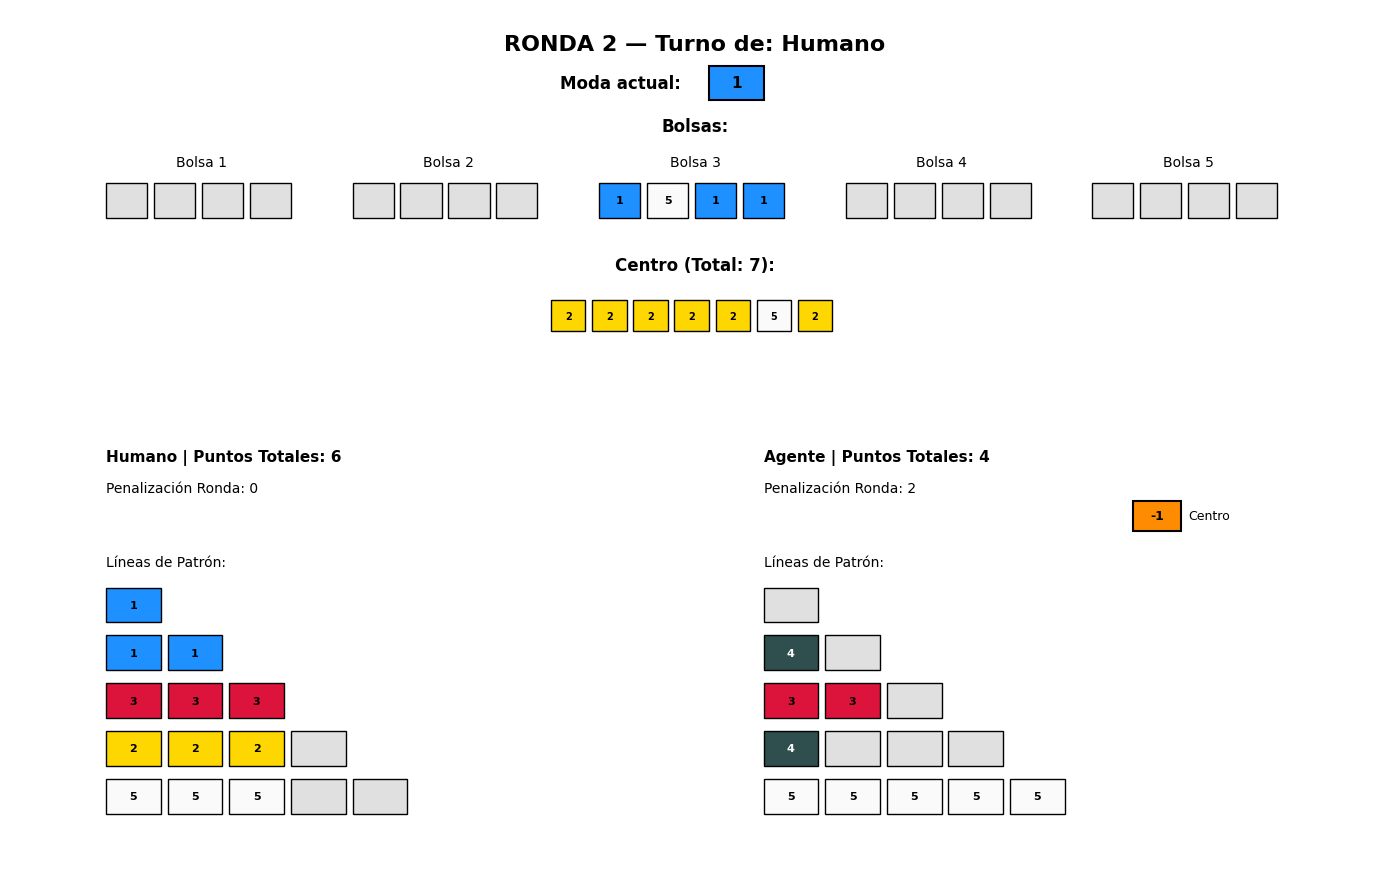


TURNO DEL HUMANO

JUGADAS DISPONIBLES:

  0 -> Centro     | Color 2 | Descarte
  1 -> Centro     | Color 2 | Fila 4
  2 -> Centro     | Color 5 | Descarte
  3 -> Centro     | Color 5 | Fila 5
  4 -> Bolsa 3    | Color 1 | Descarte
  5 -> Bolsa 3    | Color 5 | Descarte
  6 -> Bolsa 3    | Color 5 | Fila 5

Elige el número de la jugada: 3

Jugada elegida: (0, 5, 5)

Turno de Humano: (0, 5, 5)
Fichas tomadas: 1
Fichas sobrantes: 0


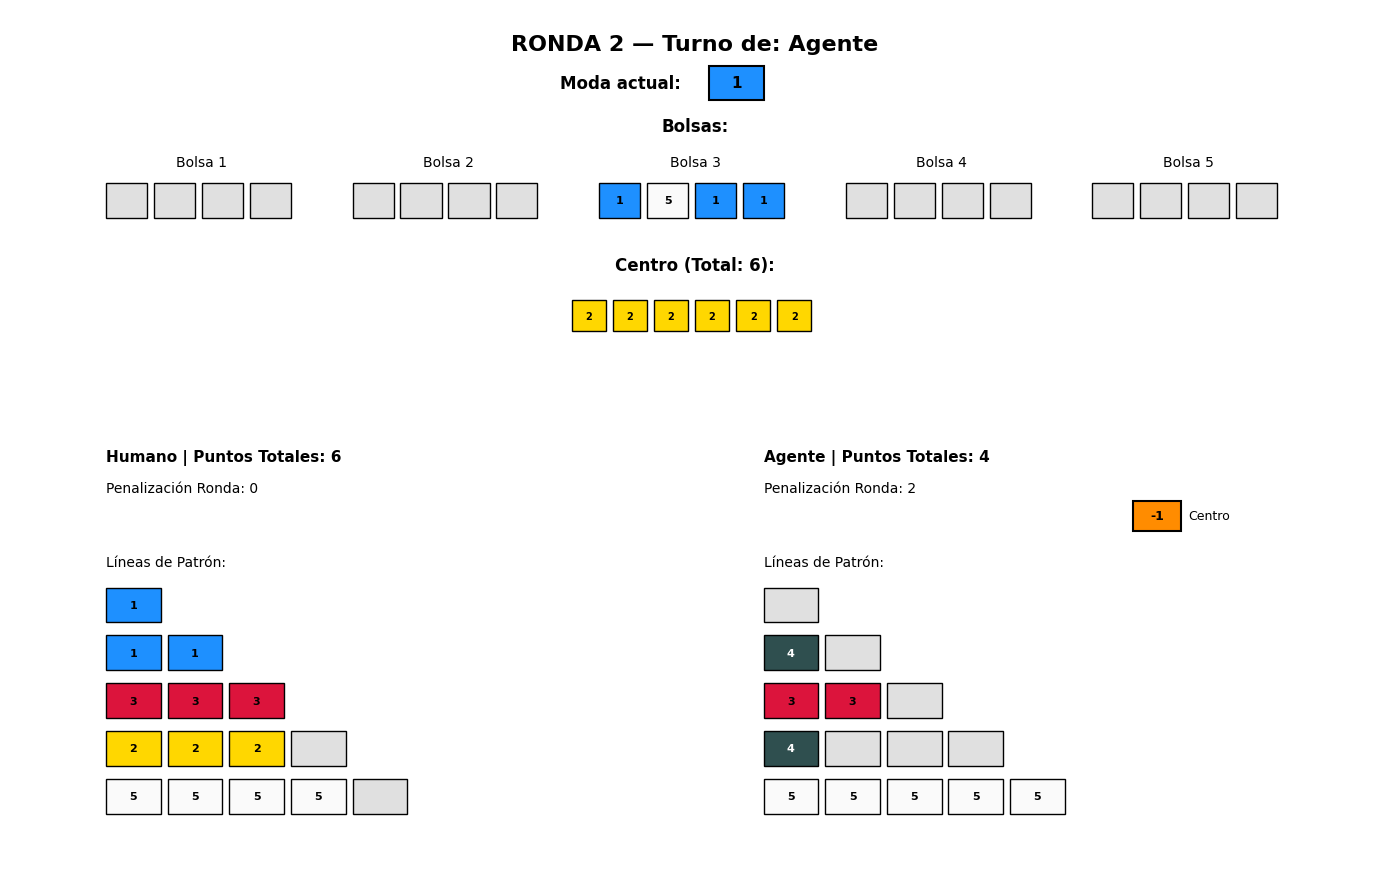


--------------------------------------
TURNO DEL AGENTE
--------------------------------------
Jugada elegida: (3, 1, 1)

Turno de Agente: (3, 1, 1)
Fichas tomadas: 3
Fichas sobrantes: 2


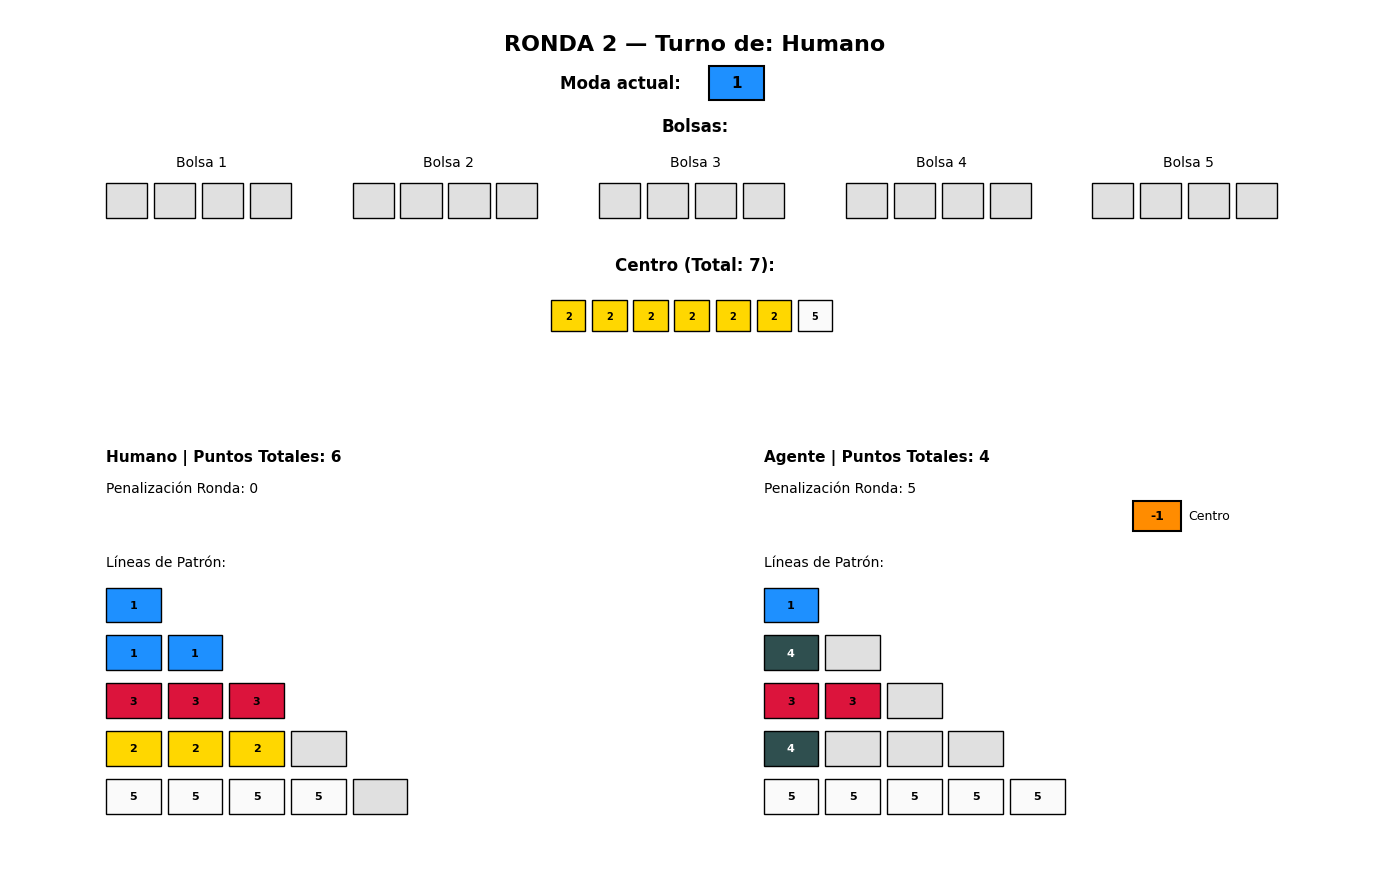


TURNO DEL HUMANO

JUGADAS DISPONIBLES:

  0 -> Centro     | Color 2 | Descarte
  1 -> Centro     | Color 2 | Fila 4
  2 -> Centro     | Color 5 | Descarte
  3 -> Centro     | Color 5 | Fila 5

Elige el número de la jugada: 3

Jugada elegida: (0, 5, 5)

Turno de Humano: (0, 5, 5)
Fichas tomadas: 1
Fichas sobrantes: 0


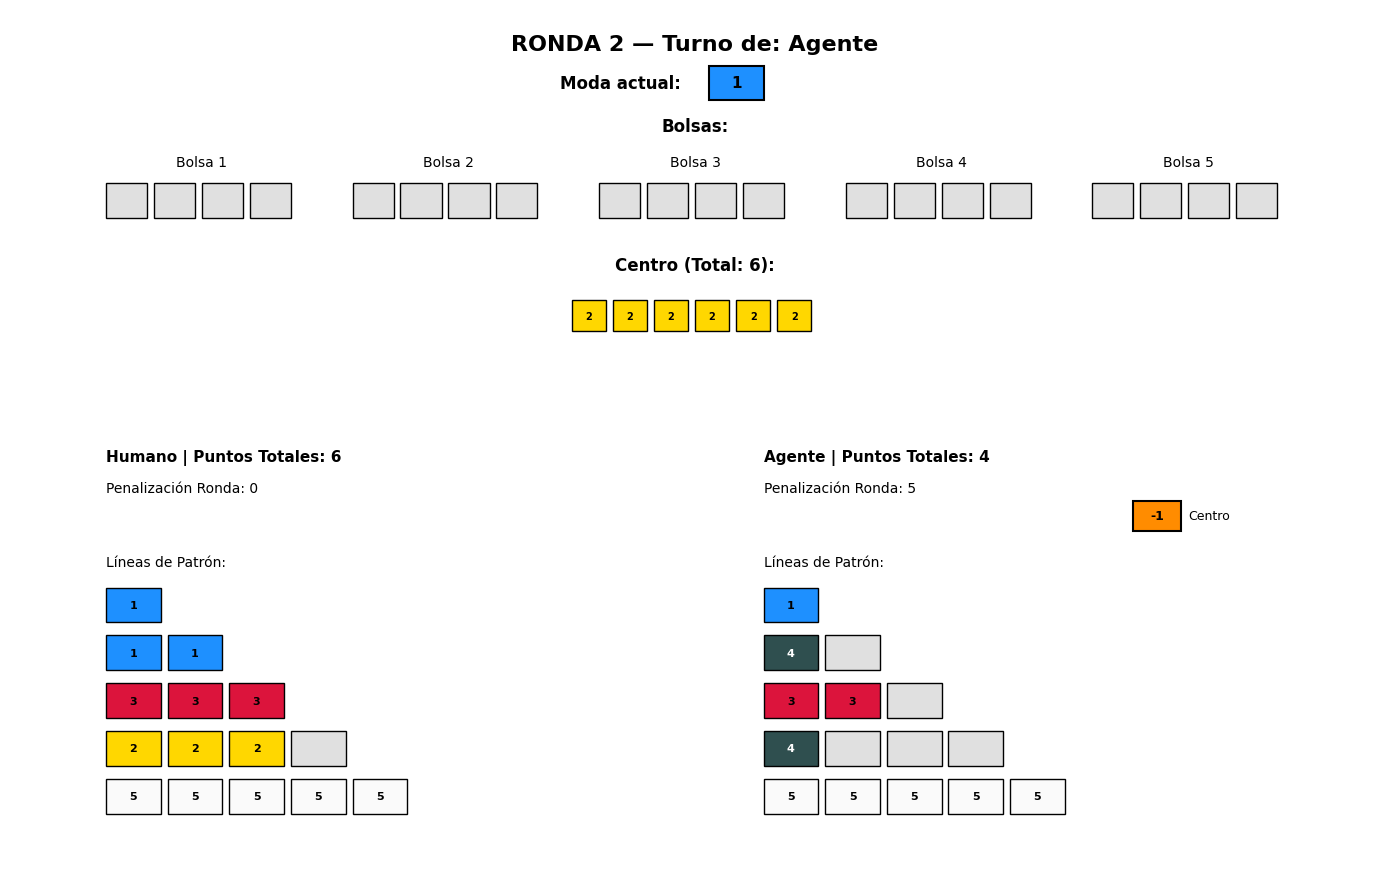


--------------------------------------
TURNO DEL AGENTE
--------------------------------------
Jugada elegida: (0, 2, 0)

Turno de Agente: (0, 2, 0)
Fichas tomadas: 6
Fichas sobrantes: 6

Resultados de la ronda 2
Moda: 1

Humano
Puntos por filas: 11
Puntos por moda: 3
Descuentos: 0
Puntos de la ronda: 14
Total acumulado: 20

Agente
Puntos por filas: 6
Puntos por moda: 1
Descuentos: 13
Puntos de la ronda: -6
Total acumulado: -2

========== RONDA 3 ==========
Moda de la ronda: 5


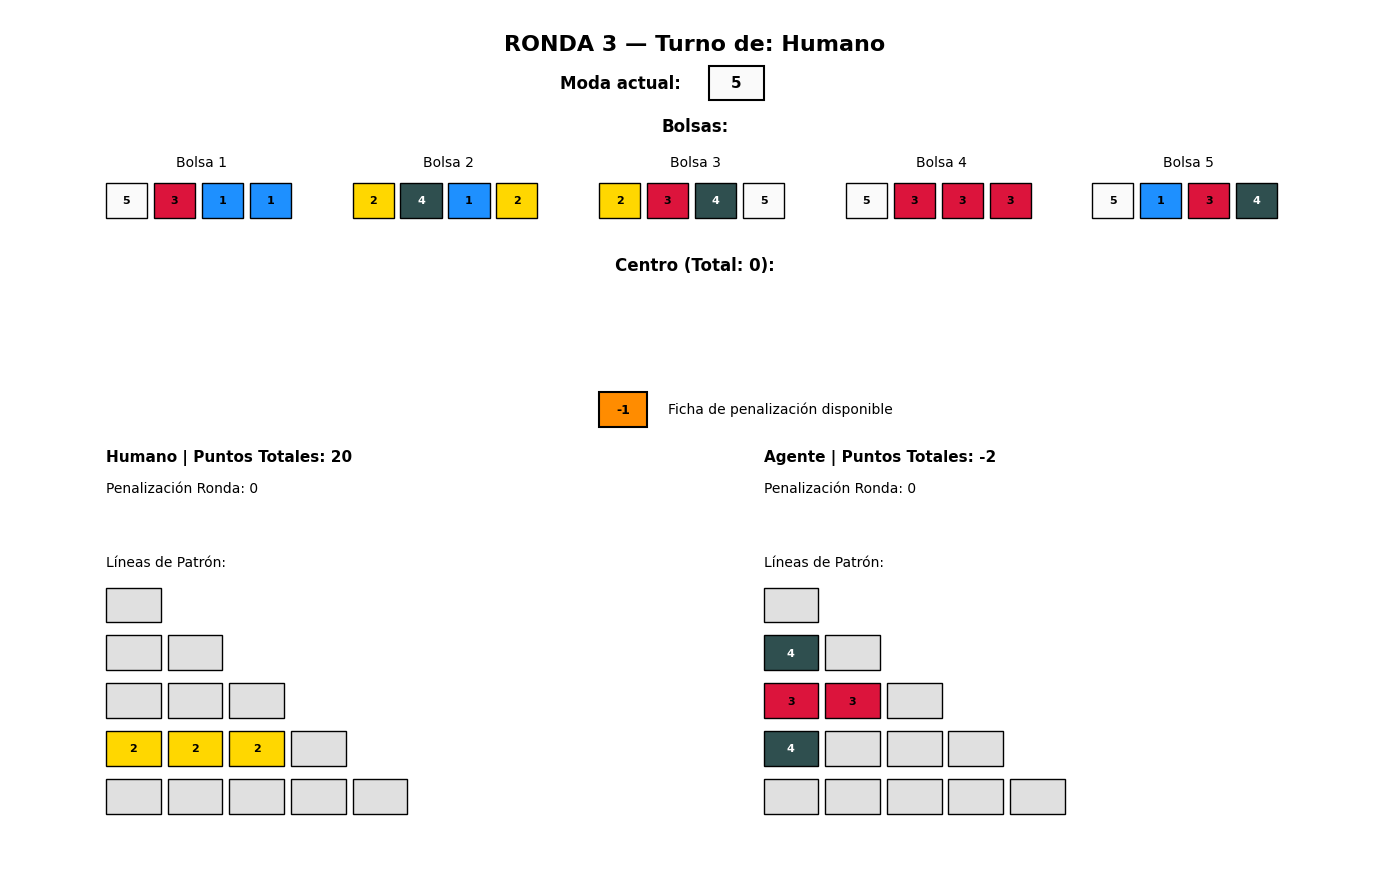


TURNO DEL HUMANO

JUGADAS DISPONIBLES:

  0 -> Bolsa 1    | Color 1 | Descarte
  1 -> Bolsa 1    | Color 1 | Fila 1
  2 -> Bolsa 1    | Color 1 | Fila 2
  3 -> Bolsa 1    | Color 1 | Fila 3
  4 -> Bolsa 1    | Color 1 | Fila 5
  5 -> Bolsa 1    | Color 3 | Descarte
  6 -> Bolsa 1    | Color 3 | Fila 1
  7 -> Bolsa 1    | Color 3 | Fila 2
  8 -> Bolsa 1    | Color 3 | Fila 3
  9 -> Bolsa 1    | Color 3 | Fila 5
 10 -> Bolsa 1    | Color 5 | Descarte
 11 -> Bolsa 1    | Color 5 | Fila 1
 12 -> Bolsa 1    | Color 5 | Fila 2
 13 -> Bolsa 1    | Color 5 | Fila 3
 14 -> Bolsa 1    | Color 5 | Fila 5
 15 -> Bolsa 2    | Color 1 | Descarte
 16 -> Bolsa 2    | Color 1 | Fila 1
 17 -> Bolsa 2    | Color 1 | Fila 2
 18 -> Bolsa 2    | Color 1 | Fila 3
 19 -> Bolsa 2    | Color 1 | Fila 5
 20 -> Bolsa 2    | Color 2 | Descarte
 21 -> Bolsa 2    | Color 2 | Fila 1
 22 -> Bolsa 2    | Color 2 | Fila 2
 23 -> Bolsa 2    | Color 2 | Fila 3
 24 -> Bolsa 2    | Color 2 | Fila 4
 25 -> Bolsa 2    | Colo

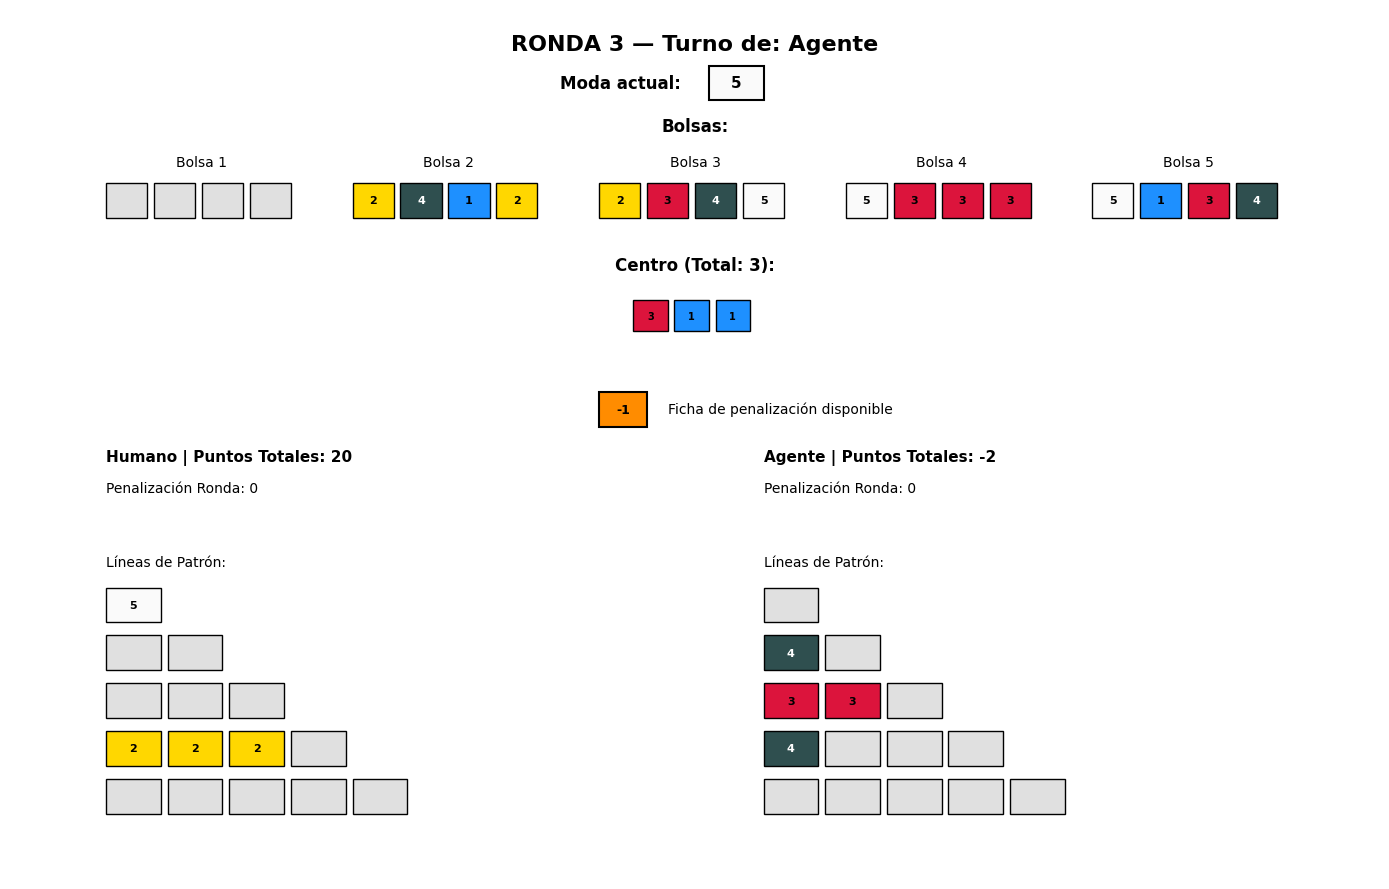


--------------------------------------
TURNO DEL AGENTE
--------------------------------------
Jugada elegida: (0, 3, 3)

Turno de Agente: (0, 3, 3)
Tomaste la ficha blanca: -1 punto.
Fichas tomadas: 1
Fichas sobrantes: 0


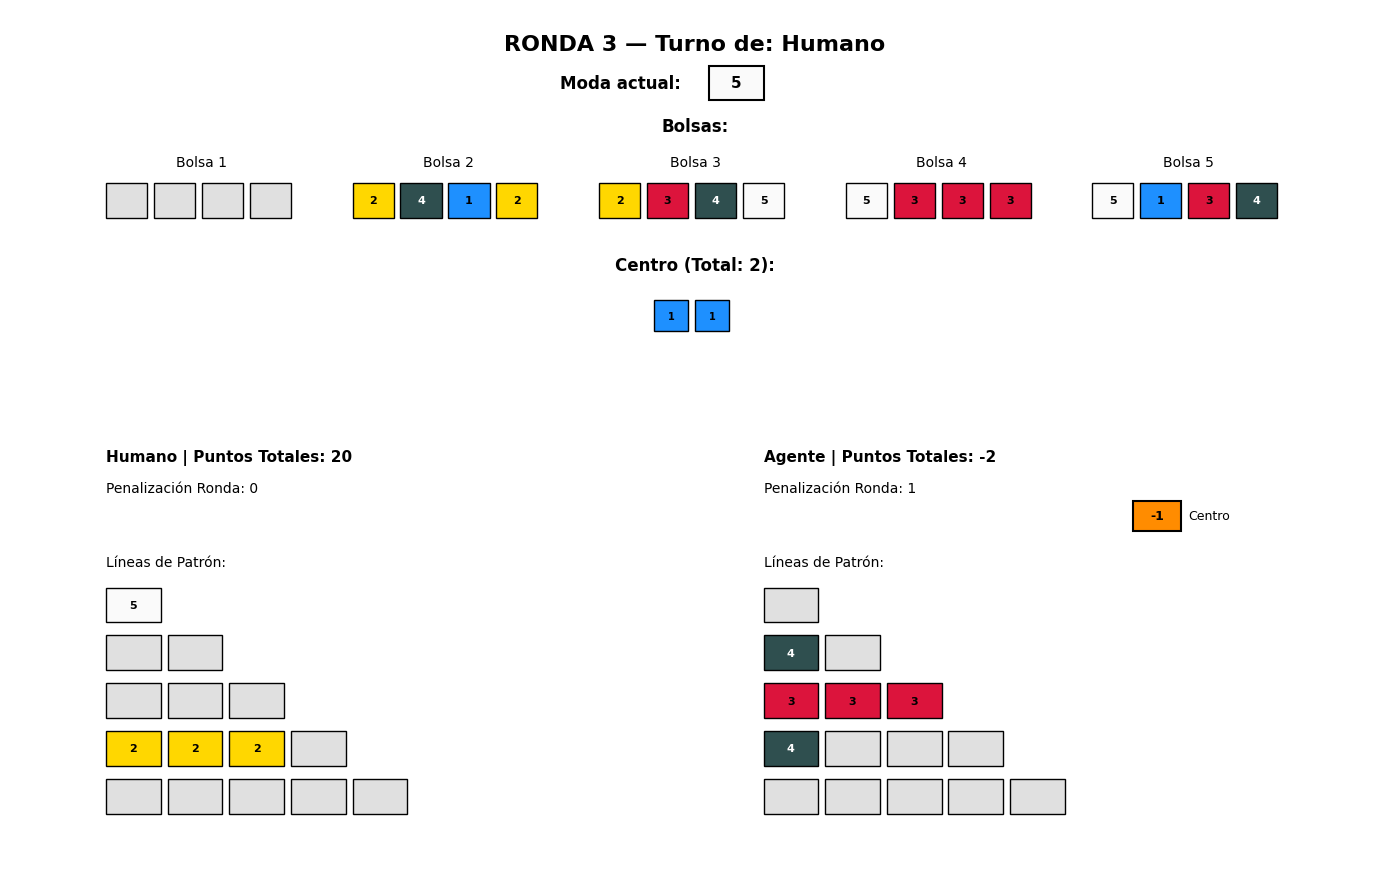


TURNO DEL HUMANO

JUGADAS DISPONIBLES:

  0 -> Centro     | Color 1 | Descarte
  1 -> Centro     | Color 1 | Fila 2
  2 -> Centro     | Color 1 | Fila 3
  3 -> Centro     | Color 1 | Fila 5
  4 -> Bolsa 2    | Color 1 | Descarte
  5 -> Bolsa 2    | Color 1 | Fila 2
  6 -> Bolsa 2    | Color 1 | Fila 3
  7 -> Bolsa 2    | Color 1 | Fila 5
  8 -> Bolsa 2    | Color 2 | Descarte
  9 -> Bolsa 2    | Color 2 | Fila 2
 10 -> Bolsa 2    | Color 2 | Fila 3
 11 -> Bolsa 2    | Color 2 | Fila 4
 12 -> Bolsa 2    | Color 2 | Fila 5
 13 -> Bolsa 2    | Color 4 | Descarte
 14 -> Bolsa 2    | Color 4 | Fila 2
 15 -> Bolsa 2    | Color 4 | Fila 3
 16 -> Bolsa 2    | Color 4 | Fila 5
 17 -> Bolsa 3    | Color 2 | Descarte
 18 -> Bolsa 3    | Color 2 | Fila 2
 19 -> Bolsa 3    | Color 2 | Fila 3
 20 -> Bolsa 3    | Color 2 | Fila 4
 21 -> Bolsa 3    | Color 2 | Fila 5
 22 -> Bolsa 3    | Color 3 | Descarte
 23 -> Bolsa 3    | Color 3 | Fila 2
 24 -> Bolsa 3    | Color 3 | Fila 3
 25 -> Bolsa 3    | Co

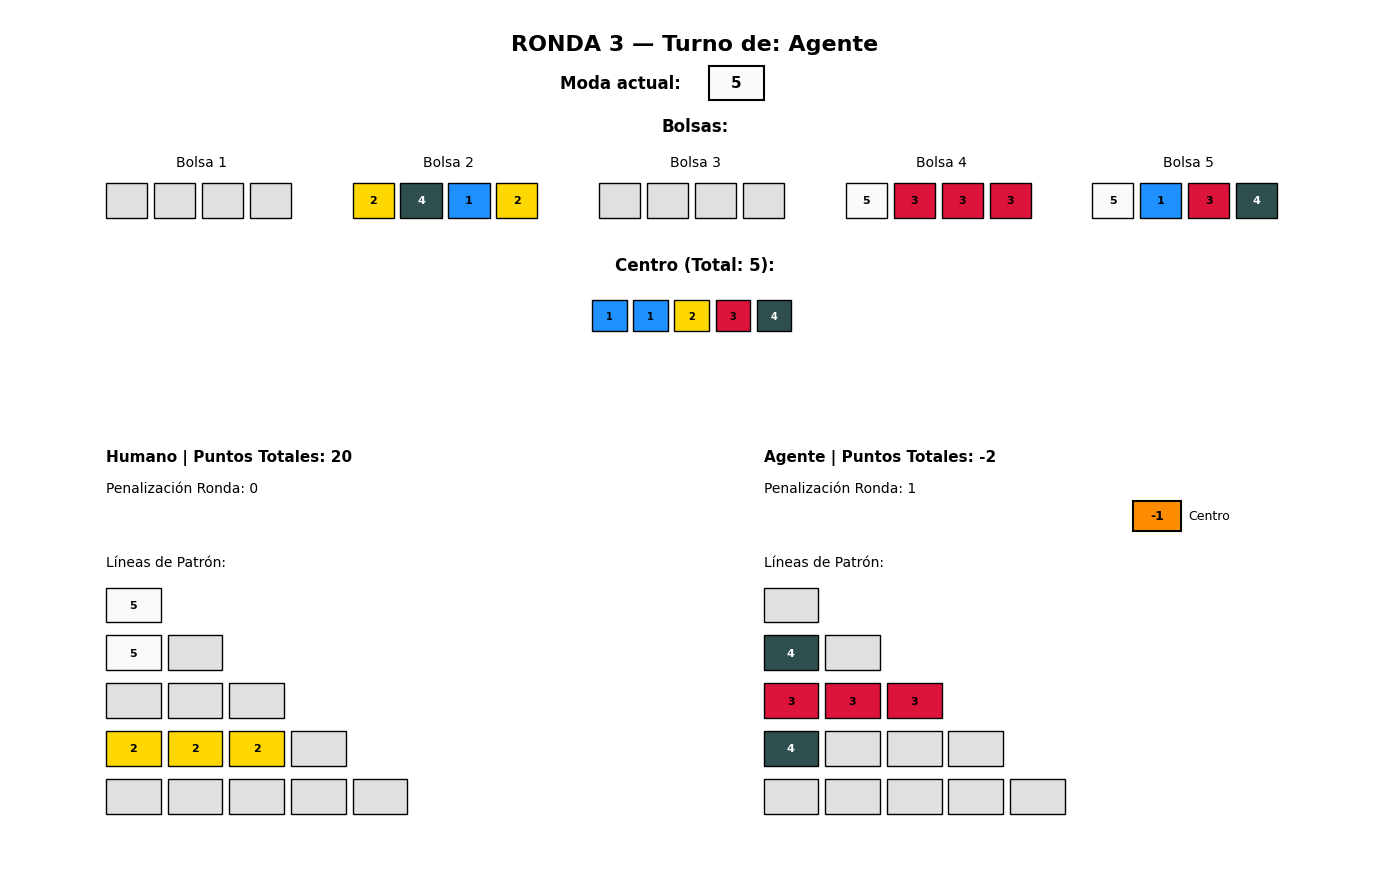


--------------------------------------
TURNO DEL AGENTE
--------------------------------------
Jugada elegida: (0, 1, 5)

Turno de Agente: (0, 1, 5)
Fichas tomadas: 2
Fichas sobrantes: 0


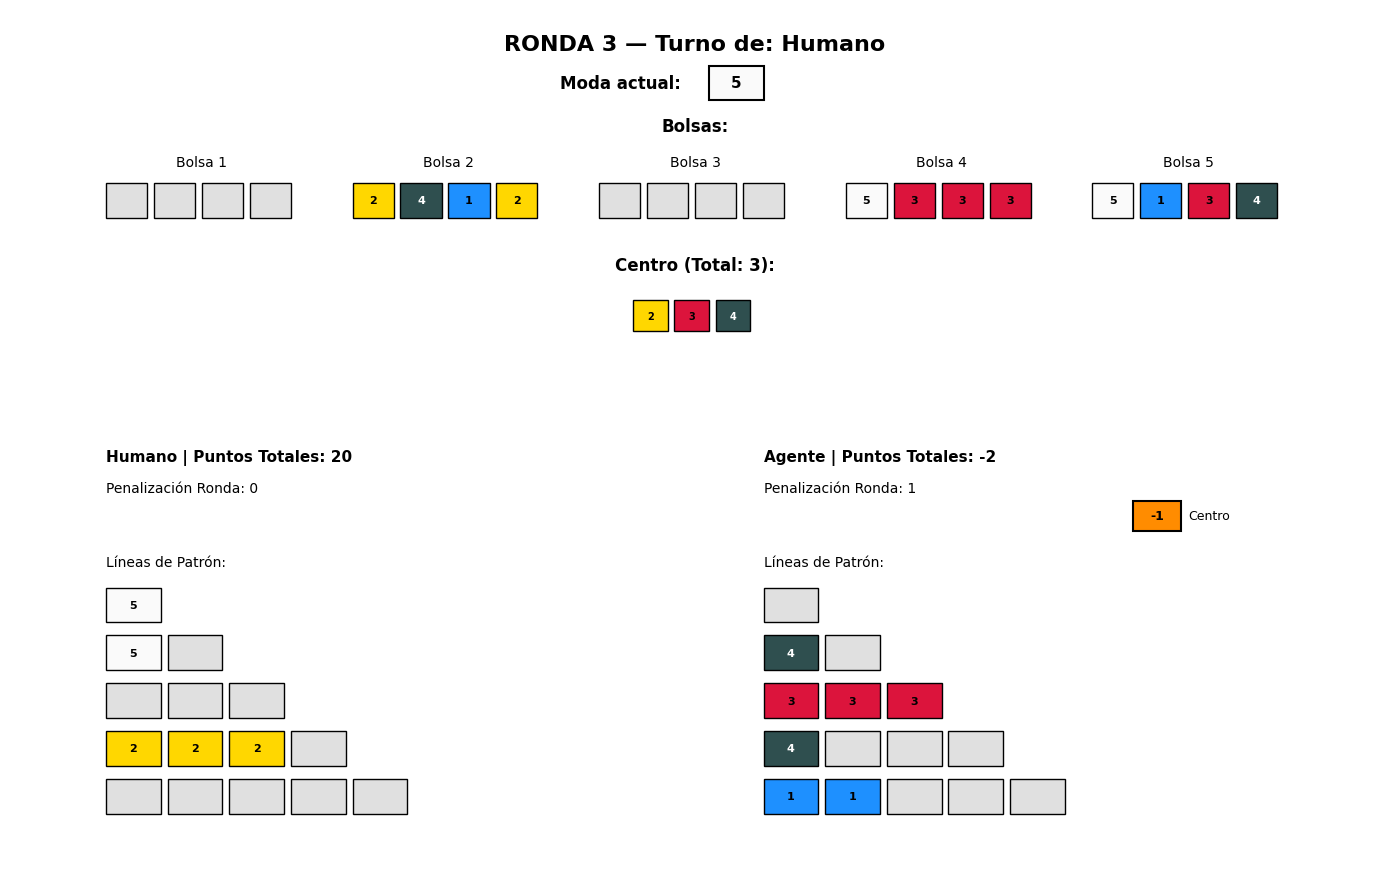


TURNO DEL HUMANO

JUGADAS DISPONIBLES:

  0 -> Centro     | Color 2 | Descarte
  1 -> Centro     | Color 2 | Fila 3
  2 -> Centro     | Color 2 | Fila 4
  3 -> Centro     | Color 2 | Fila 5
  4 -> Centro     | Color 3 | Descarte
  5 -> Centro     | Color 3 | Fila 3
  6 -> Centro     | Color 3 | Fila 5
  7 -> Centro     | Color 4 | Descarte
  8 -> Centro     | Color 4 | Fila 3
  9 -> Centro     | Color 4 | Fila 5
 10 -> Bolsa 2    | Color 1 | Descarte
 11 -> Bolsa 2    | Color 1 | Fila 3
 12 -> Bolsa 2    | Color 1 | Fila 5
 13 -> Bolsa 2    | Color 2 | Descarte
 14 -> Bolsa 2    | Color 2 | Fila 3
 15 -> Bolsa 2    | Color 2 | Fila 4
 16 -> Bolsa 2    | Color 2 | Fila 5
 17 -> Bolsa 2    | Color 4 | Descarte
 18 -> Bolsa 2    | Color 4 | Fila 3
 19 -> Bolsa 2    | Color 4 | Fila 5
 20 -> Bolsa 4    | Color 3 | Descarte
 21 -> Bolsa 4    | Color 3 | Fila 3
 22 -> Bolsa 4    | Color 3 | Fila 5
 23 -> Bolsa 4    | Color 5 | Descarte
 24 -> Bolsa 4    | Color 5 | Fila 2
 25 -> Bolsa 4    

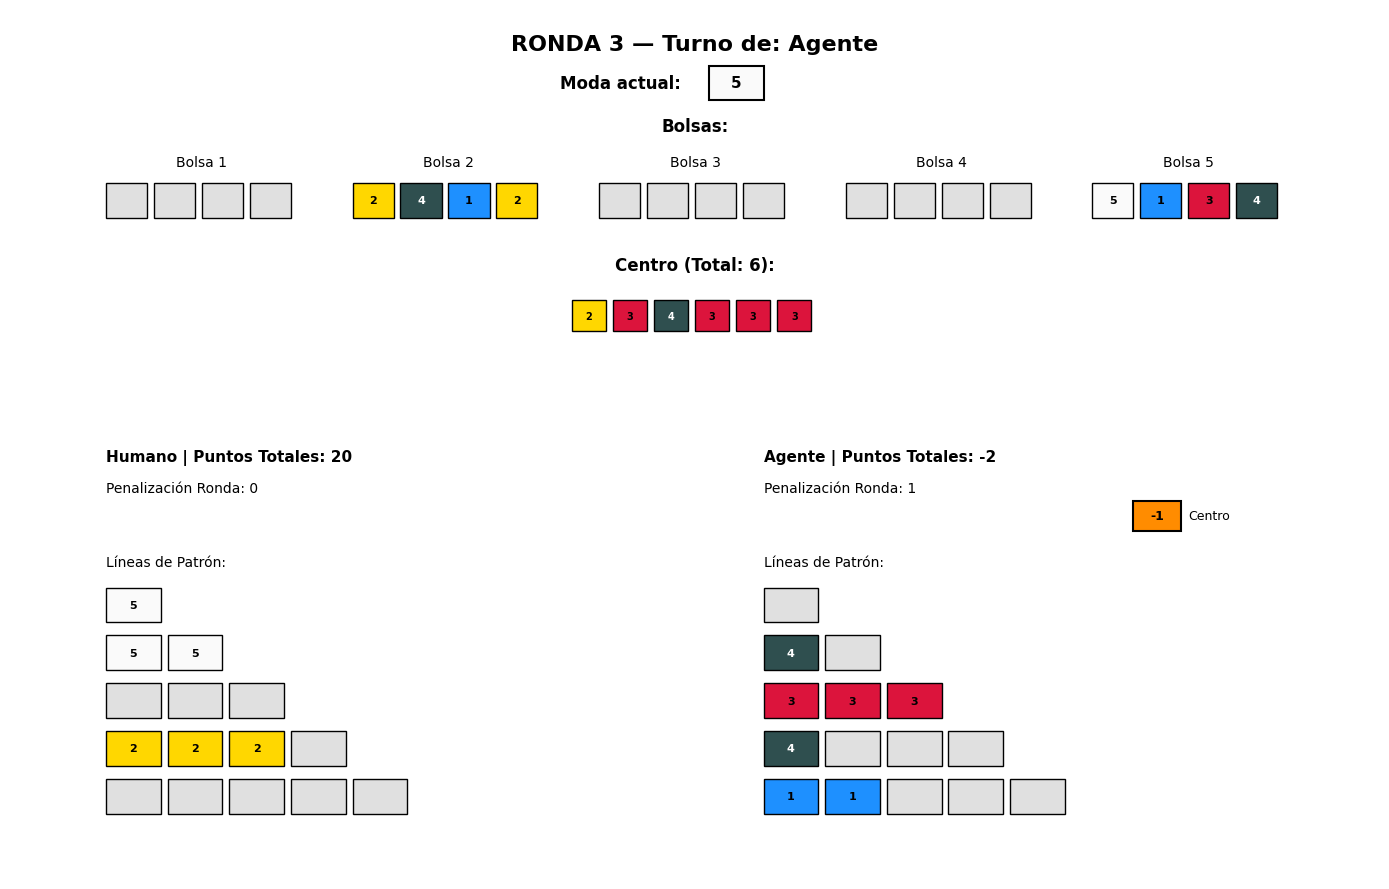


--------------------------------------
TURNO DEL AGENTE
--------------------------------------
Jugada elegida: (5, 1, 1)

Turno de Agente: (5, 1, 1)
Fichas tomadas: 1
Fichas sobrantes: 0


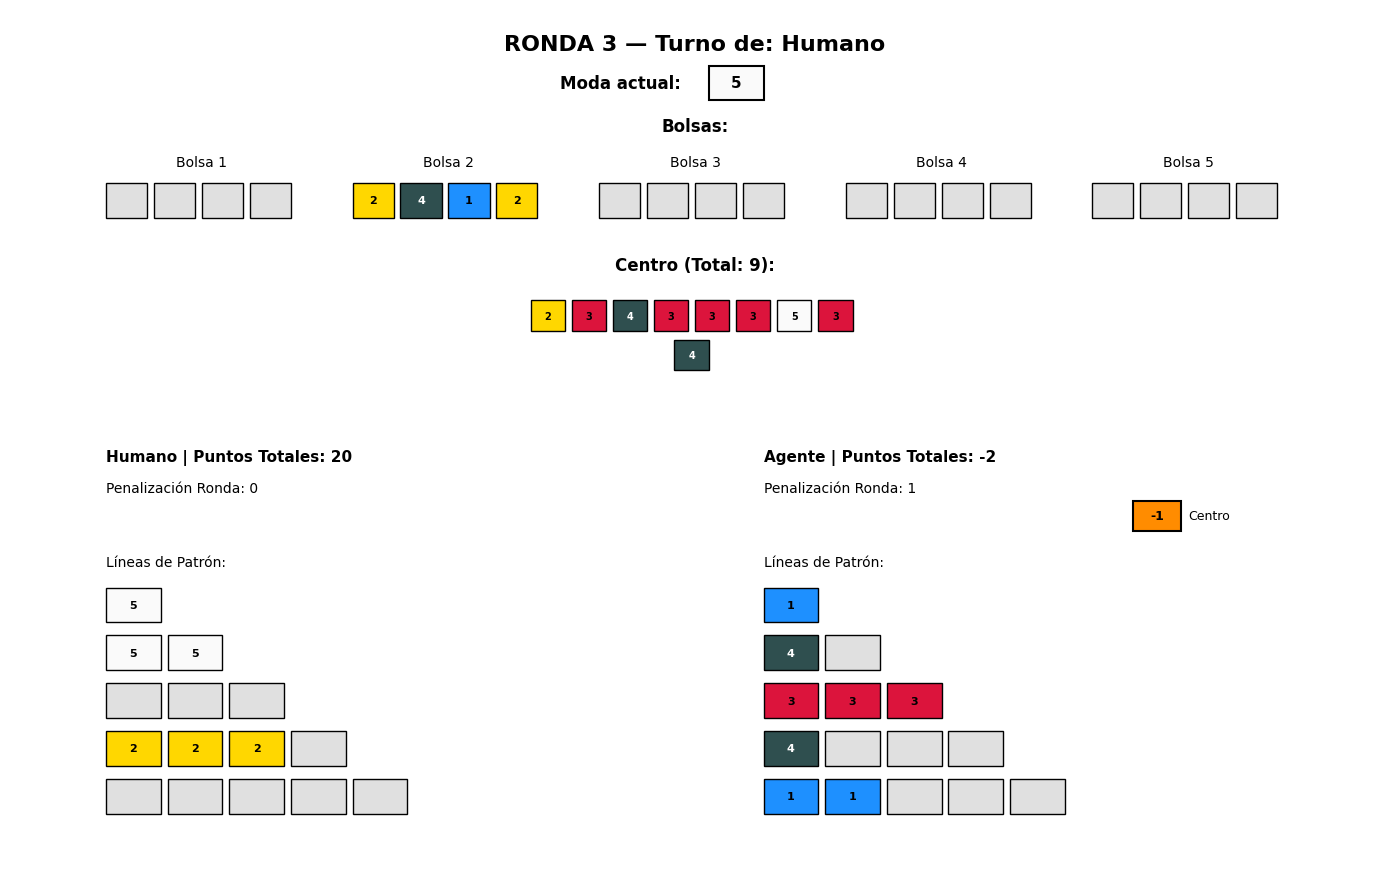


TURNO DEL HUMANO

JUGADAS DISPONIBLES:

  0 -> Centro     | Color 2 | Descarte
  1 -> Centro     | Color 2 | Fila 3
  2 -> Centro     | Color 2 | Fila 4
  3 -> Centro     | Color 2 | Fila 5
  4 -> Centro     | Color 3 | Descarte
  5 -> Centro     | Color 3 | Fila 3
  6 -> Centro     | Color 3 | Fila 5
  7 -> Centro     | Color 4 | Descarte
  8 -> Centro     | Color 4 | Fila 3
  9 -> Centro     | Color 4 | Fila 5
 10 -> Centro     | Color 5 | Descarte
 11 -> Centro     | Color 5 | Fila 3
 12 -> Centro     | Color 5 | Fila 5
 13 -> Bolsa 2    | Color 1 | Descarte
 14 -> Bolsa 2    | Color 1 | Fila 3
 15 -> Bolsa 2    | Color 1 | Fila 5
 16 -> Bolsa 2    | Color 2 | Descarte
 17 -> Bolsa 2    | Color 2 | Fila 3
 18 -> Bolsa 2    | Color 2 | Fila 4
 19 -> Bolsa 2    | Color 2 | Fila 5
 20 -> Bolsa 2    | Color 4 | Descarte
 21 -> Bolsa 2    | Color 4 | Fila 3
 22 -> Bolsa 2    | Color 4 | Fila 5

Elige el número de la jugada: 6

Jugada elegida: (0, 3, 5)

Turno de Humano: (0, 3, 5)
Fichas

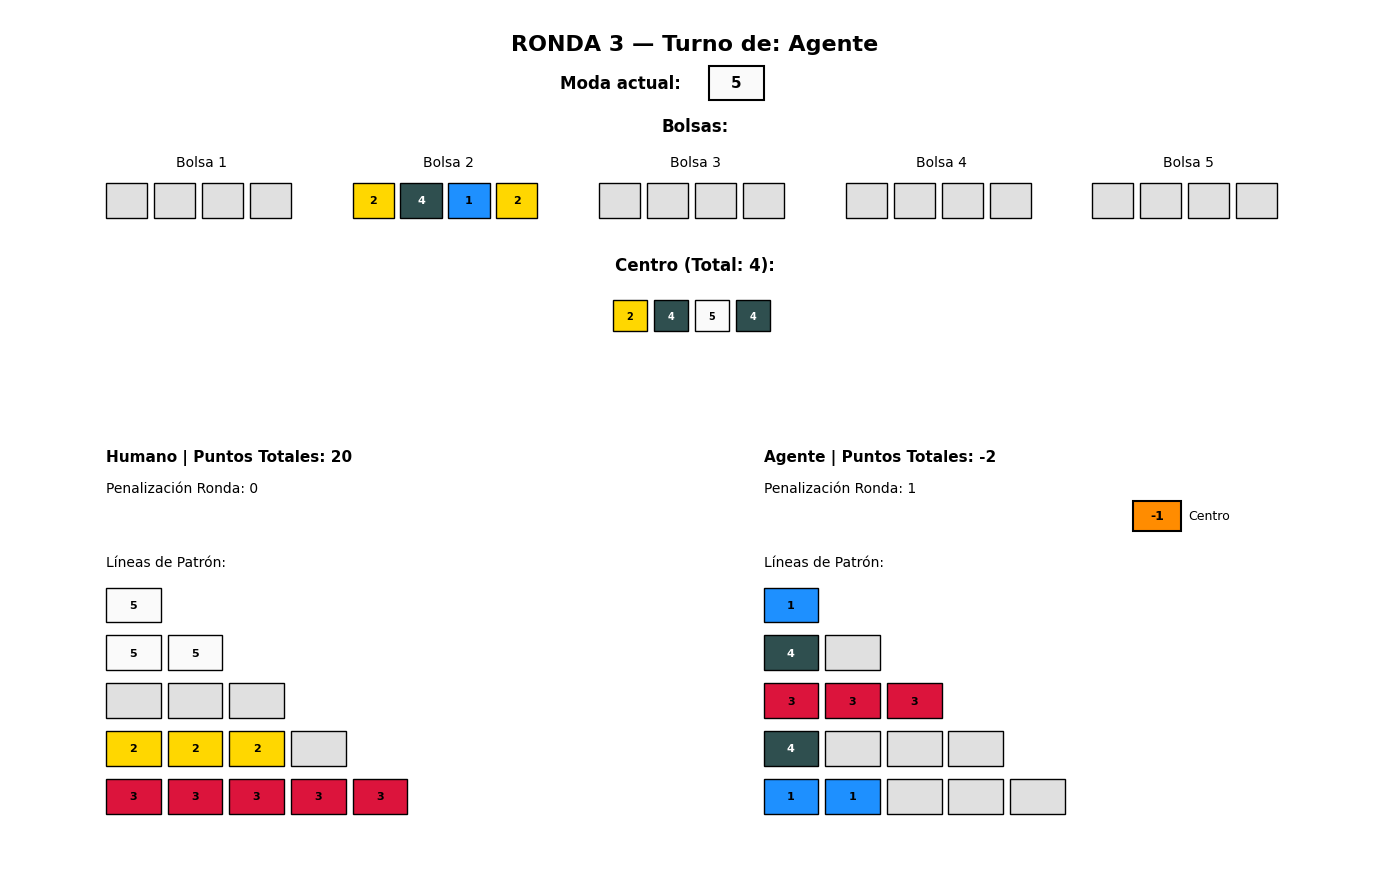


--------------------------------------
TURNO DEL AGENTE
--------------------------------------
Jugada elegida: (2, 4, 4)

Turno de Agente: (2, 4, 4)
Fichas tomadas: 1
Fichas sobrantes: 0


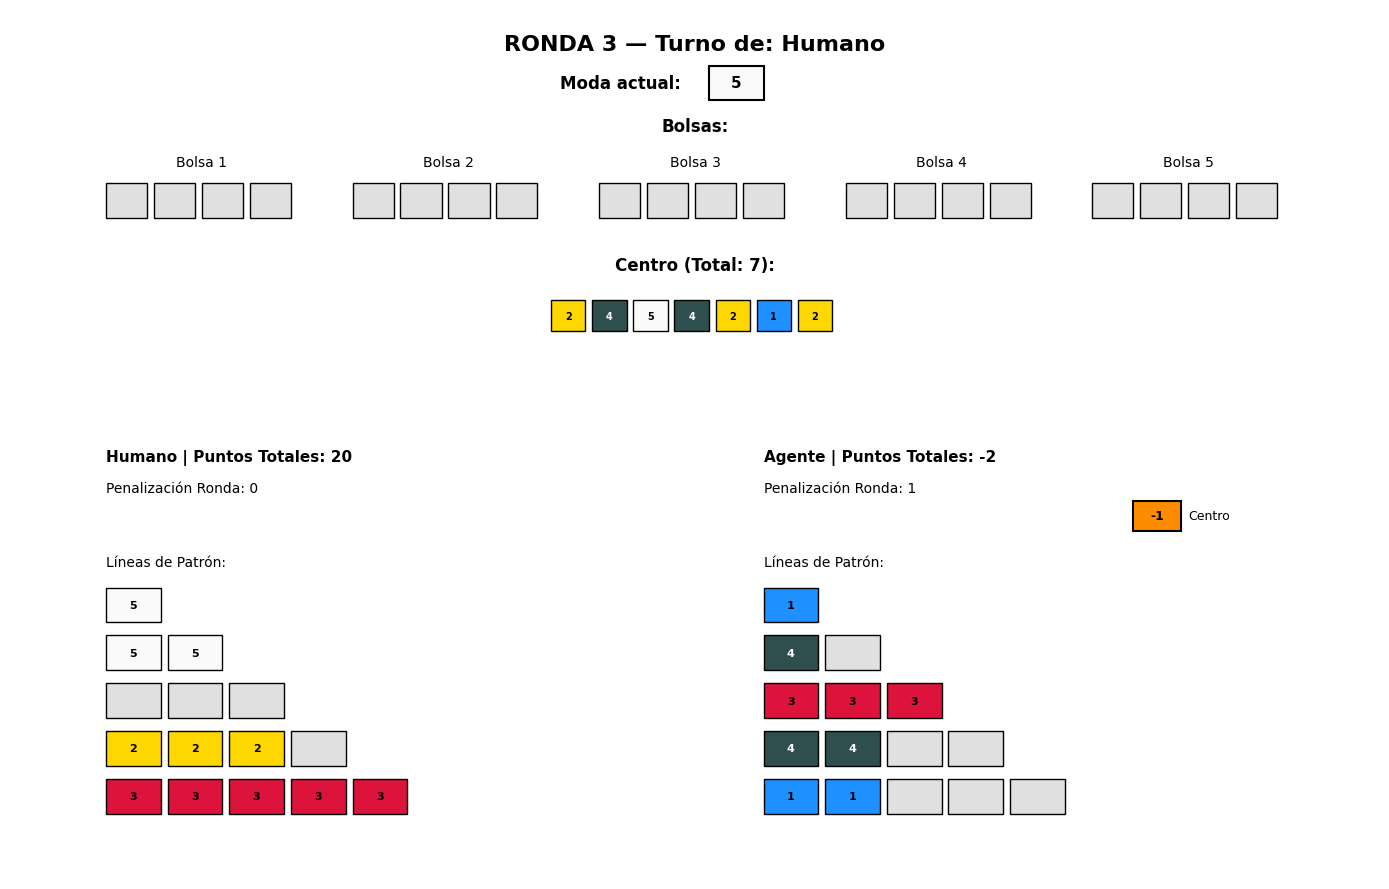


TURNO DEL HUMANO

JUGADAS DISPONIBLES:

  0 -> Centro     | Color 1 | Descarte
  1 -> Centro     | Color 1 | Fila 3
  2 -> Centro     | Color 2 | Descarte
  3 -> Centro     | Color 2 | Fila 3
  4 -> Centro     | Color 2 | Fila 4
  5 -> Centro     | Color 4 | Descarte
  6 -> Centro     | Color 4 | Fila 3
  7 -> Centro     | Color 5 | Descarte
  8 -> Centro     | Color 5 | Fila 3

Elige el número de la jugada: 3

Jugada elegida: (0, 2, 3)

Turno de Humano: (0, 2, 3)
Fichas tomadas: 3
Fichas sobrantes: 0


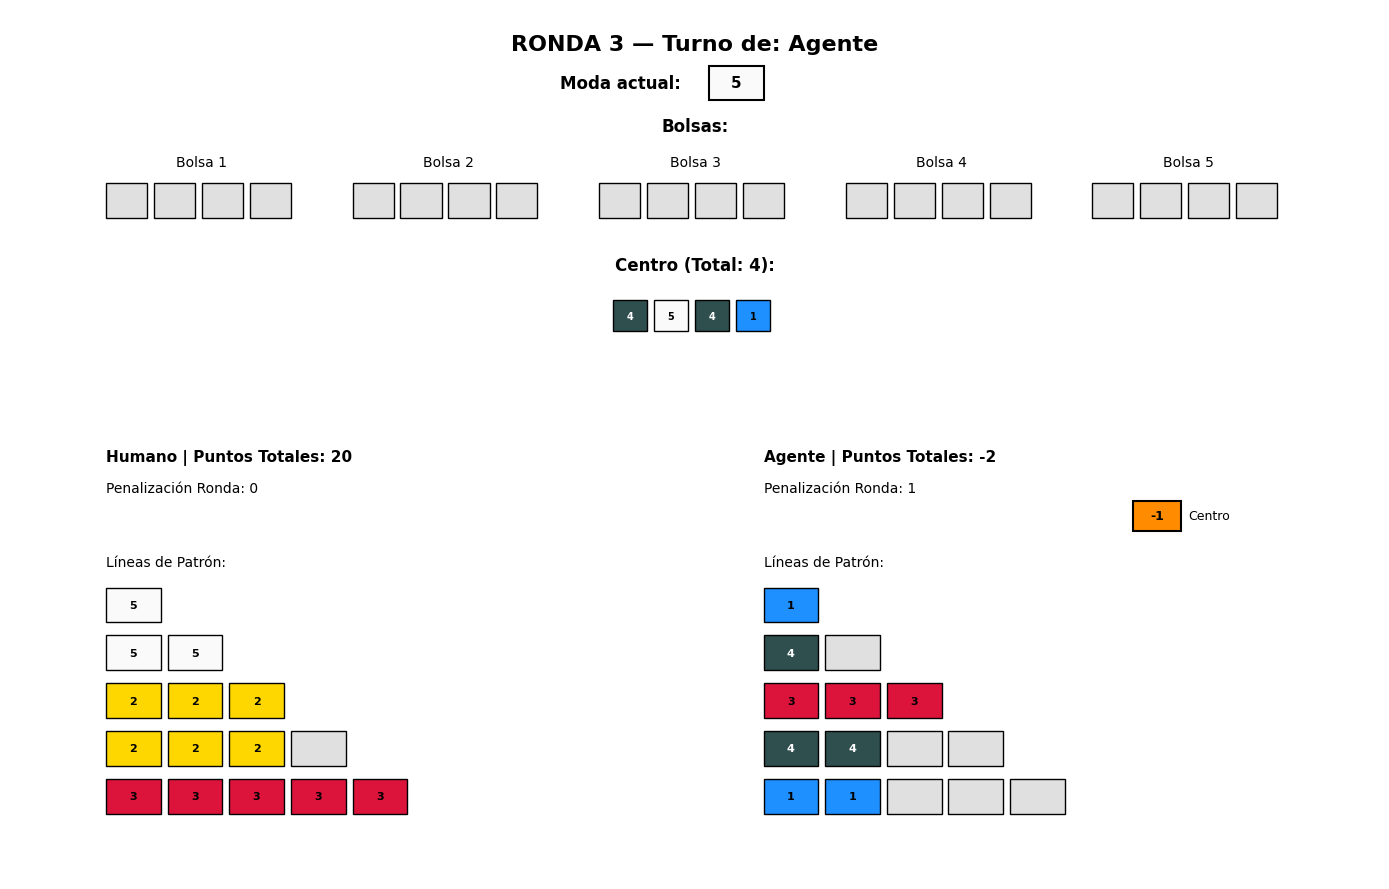


--------------------------------------
TURNO DEL AGENTE
--------------------------------------
Jugada elegida: (0, 1, 5)

Turno de Agente: (0, 1, 5)
Fichas tomadas: 1
Fichas sobrantes: 0


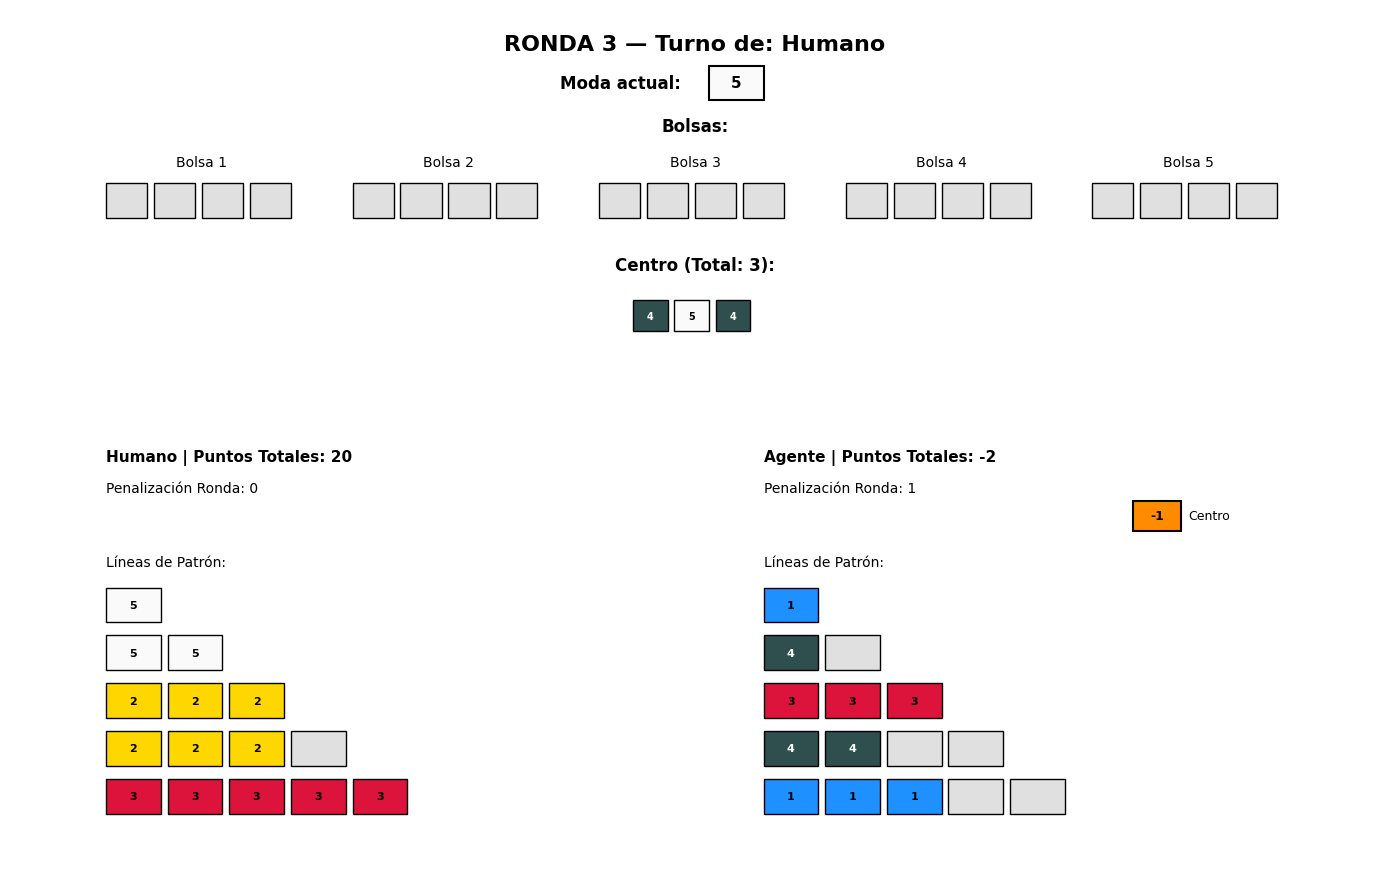


TURNO DEL HUMANO

JUGADAS DISPONIBLES:

  0 -> Centro     | Color 4 | Descarte
  1 -> Centro     | Color 5 | Descarte

Elige el número de la jugada: 1

Jugada elegida: (0, 5, 0)

Turno de Humano: (0, 5, 0)
Fichas tomadas: 1
Fichas sobrantes: 1


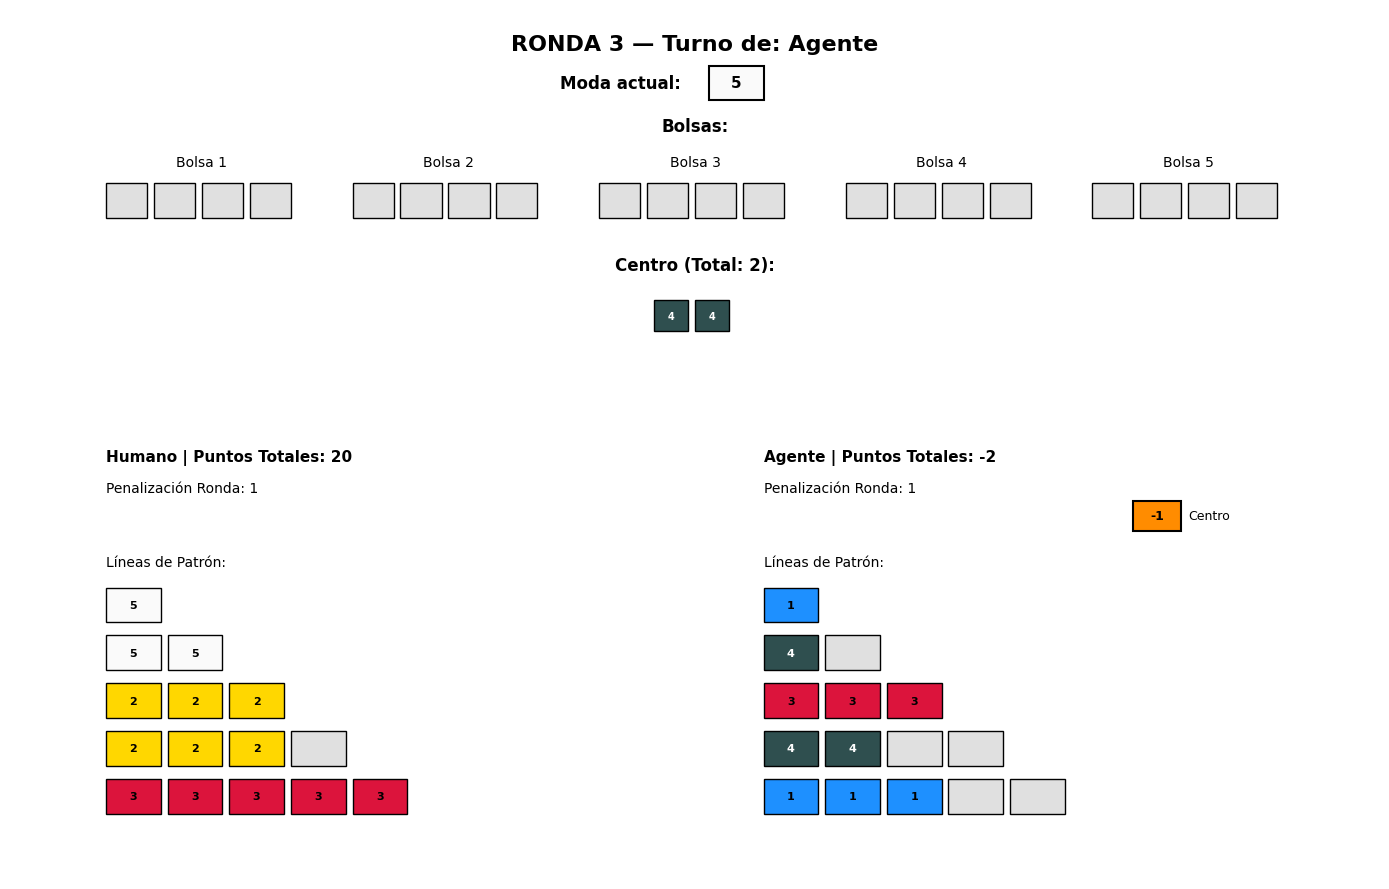


--------------------------------------
TURNO DEL AGENTE
--------------------------------------
Jugada elegida: (0, 4, 4)

Turno de Agente: (0, 4, 4)
Fichas tomadas: 2
Fichas sobrantes: 0

Resultados de la ronda 3
Moda: 5

Humano
Puntos por filas: 11
Puntos por moda: 3
Descuentos: 1
Puntos de la ronda: 13
Total acumulado: 33

Agente
Puntos por filas: 8
Puntos por moda: 0
Descuentos: 1
Puntos de la ronda: 7
Total acumulado: 5

========== RONDA 4 ==========
Moda de la ronda: 3


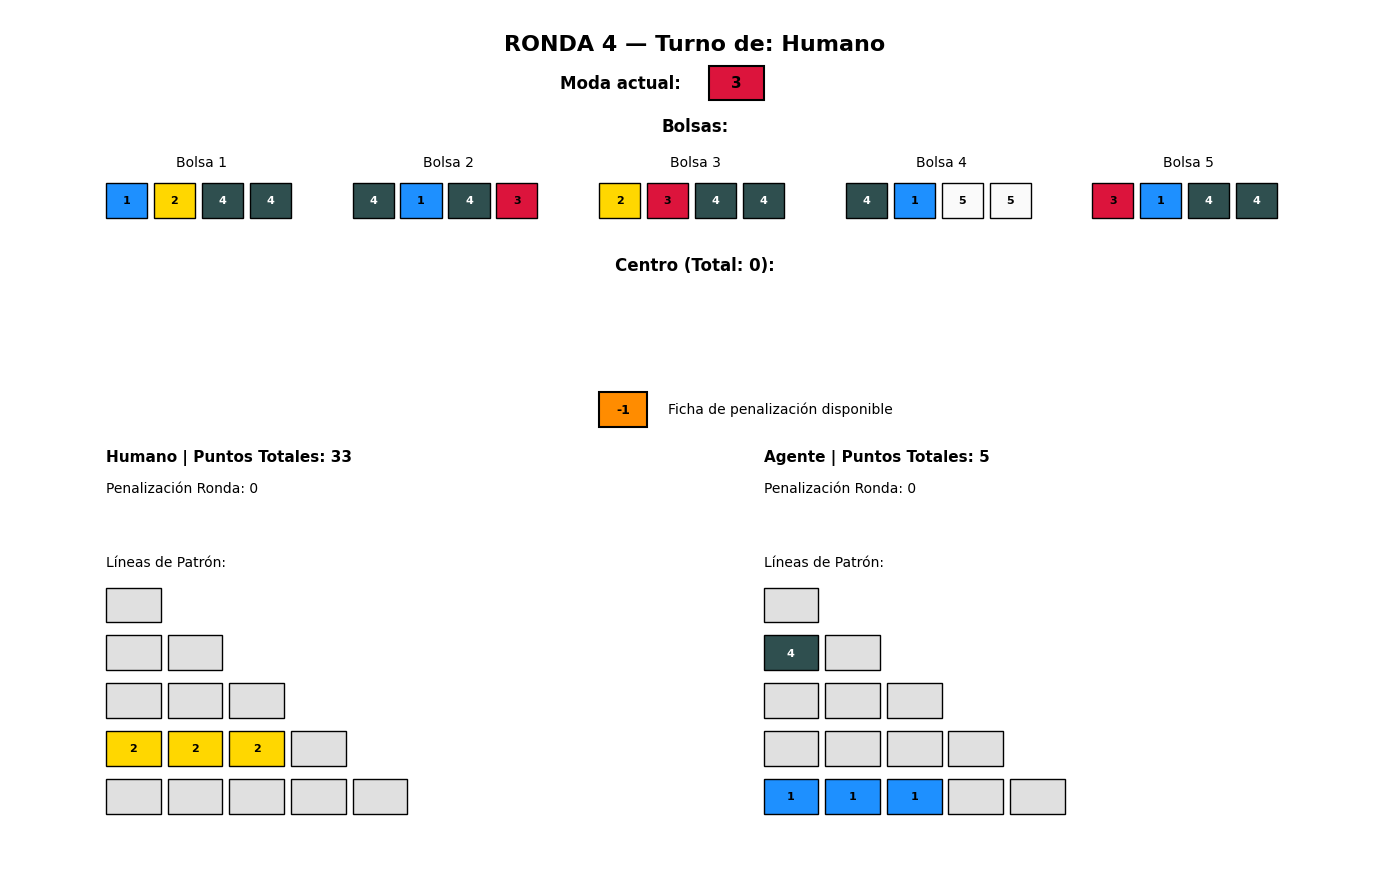


TURNO DEL HUMANO

JUGADAS DISPONIBLES:

  0 -> Bolsa 1    | Color 1 | Descarte
  1 -> Bolsa 1    | Color 1 | Fila 1
  2 -> Bolsa 1    | Color 1 | Fila 2
  3 -> Bolsa 1    | Color 1 | Fila 3
  4 -> Bolsa 1    | Color 1 | Fila 5
  5 -> Bolsa 1    | Color 2 | Descarte
  6 -> Bolsa 1    | Color 2 | Fila 1
  7 -> Bolsa 1    | Color 2 | Fila 2
  8 -> Bolsa 1    | Color 2 | Fila 3
  9 -> Bolsa 1    | Color 2 | Fila 4
 10 -> Bolsa 1    | Color 2 | Fila 5
 11 -> Bolsa 1    | Color 4 | Descarte
 12 -> Bolsa 1    | Color 4 | Fila 1
 13 -> Bolsa 1    | Color 4 | Fila 2
 14 -> Bolsa 1    | Color 4 | Fila 3
 15 -> Bolsa 1    | Color 4 | Fila 5
 16 -> Bolsa 2    | Color 1 | Descarte
 17 -> Bolsa 2    | Color 1 | Fila 1
 18 -> Bolsa 2    | Color 1 | Fila 2
 19 -> Bolsa 2    | Color 1 | Fila 3
 20 -> Bolsa 2    | Color 1 | Fila 5
 21 -> Bolsa 2    | Color 3 | Descarte
 22 -> Bolsa 2    | Color 3 | Fila 1
 23 -> Bolsa 2    | Color 3 | Fila 2
 24 -> Bolsa 2    | Color 3 | Fila 3
 25 -> Bolsa 2    | Colo

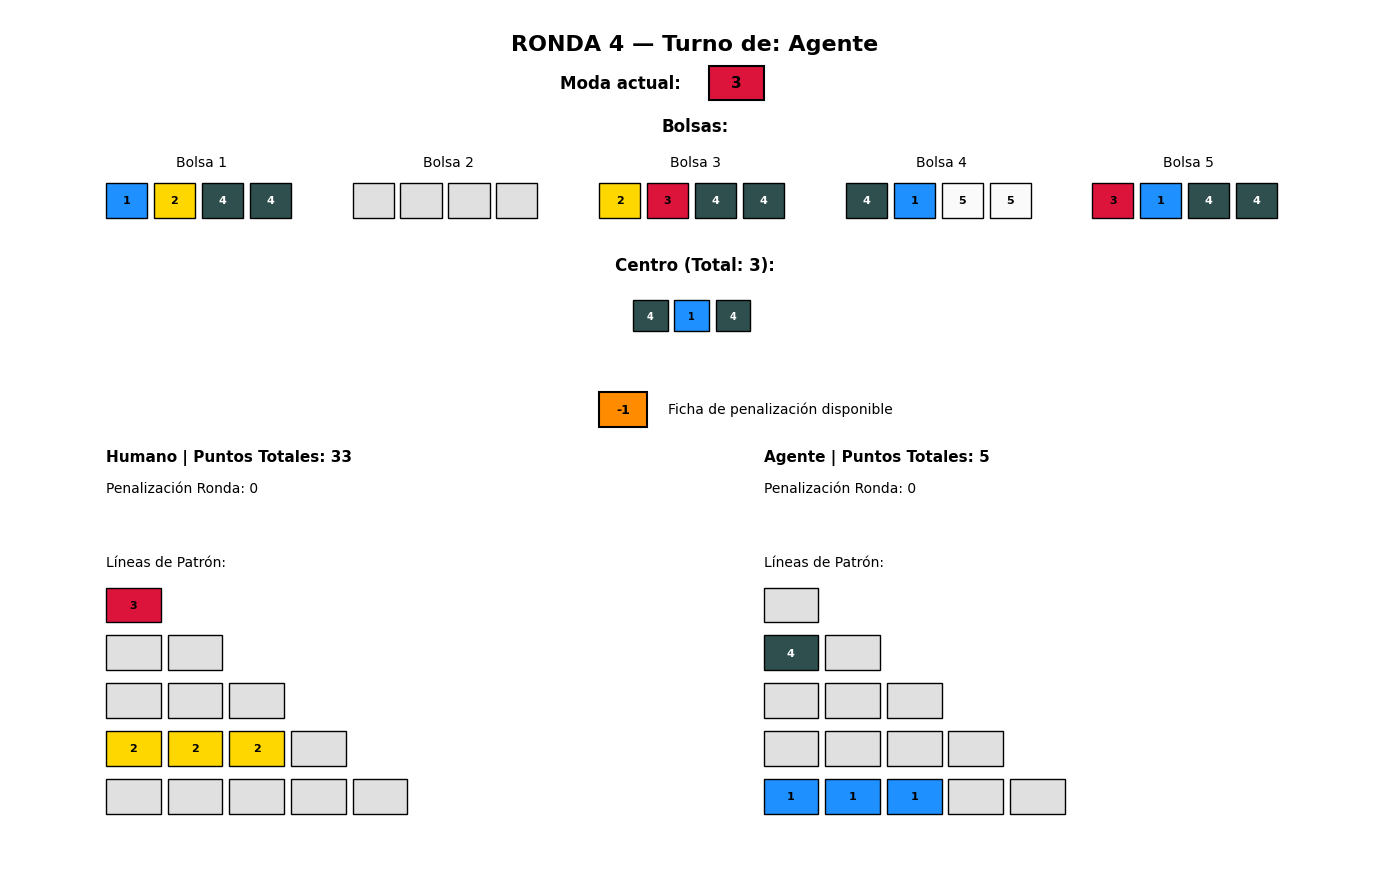


--------------------------------------
TURNO DEL AGENTE
--------------------------------------
Jugada elegida: (1, 2, 1)

Turno de Agente: (1, 2, 1)
Fichas tomadas: 1
Fichas sobrantes: 0


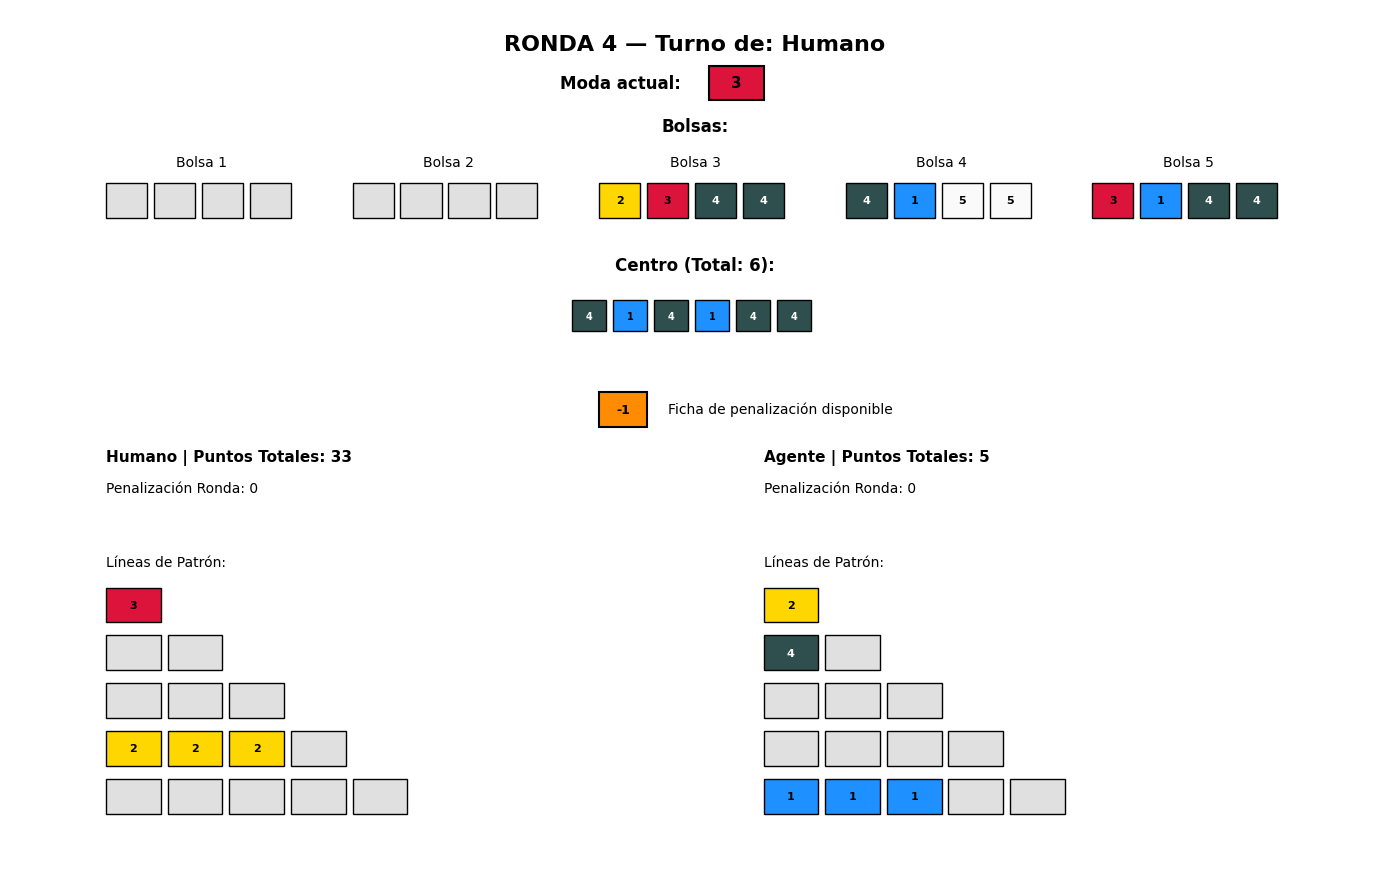


TURNO DEL HUMANO

JUGADAS DISPONIBLES:

  0 -> Centro     | Color 1 | Descarte
  1 -> Centro     | Color 1 | Fila 2
  2 -> Centro     | Color 1 | Fila 3
  3 -> Centro     | Color 1 | Fila 5
  4 -> Centro     | Color 4 | Descarte
  5 -> Centro     | Color 4 | Fila 2
  6 -> Centro     | Color 4 | Fila 3
  7 -> Centro     | Color 4 | Fila 5
  8 -> Bolsa 3    | Color 2 | Descarte
  9 -> Bolsa 3    | Color 2 | Fila 2
 10 -> Bolsa 3    | Color 2 | Fila 3
 11 -> Bolsa 3    | Color 2 | Fila 4
 12 -> Bolsa 3    | Color 2 | Fila 5
 13 -> Bolsa 3    | Color 3 | Descarte
 14 -> Bolsa 3    | Color 3 | Fila 2
 15 -> Bolsa 3    | Color 3 | Fila 3
 16 -> Bolsa 3    | Color 3 | Fila 5
 17 -> Bolsa 3    | Color 4 | Descarte
 18 -> Bolsa 3    | Color 4 | Fila 2
 19 -> Bolsa 3    | Color 4 | Fila 3
 20 -> Bolsa 3    | Color 4 | Fila 5
 21 -> Bolsa 4    | Color 1 | Descarte
 22 -> Bolsa 4    | Color 1 | Fila 2
 23 -> Bolsa 4    | Color 1 | Fila 3
 24 -> Bolsa 4    | Color 1 | Fila 5
 25 -> Bolsa 4    | Co

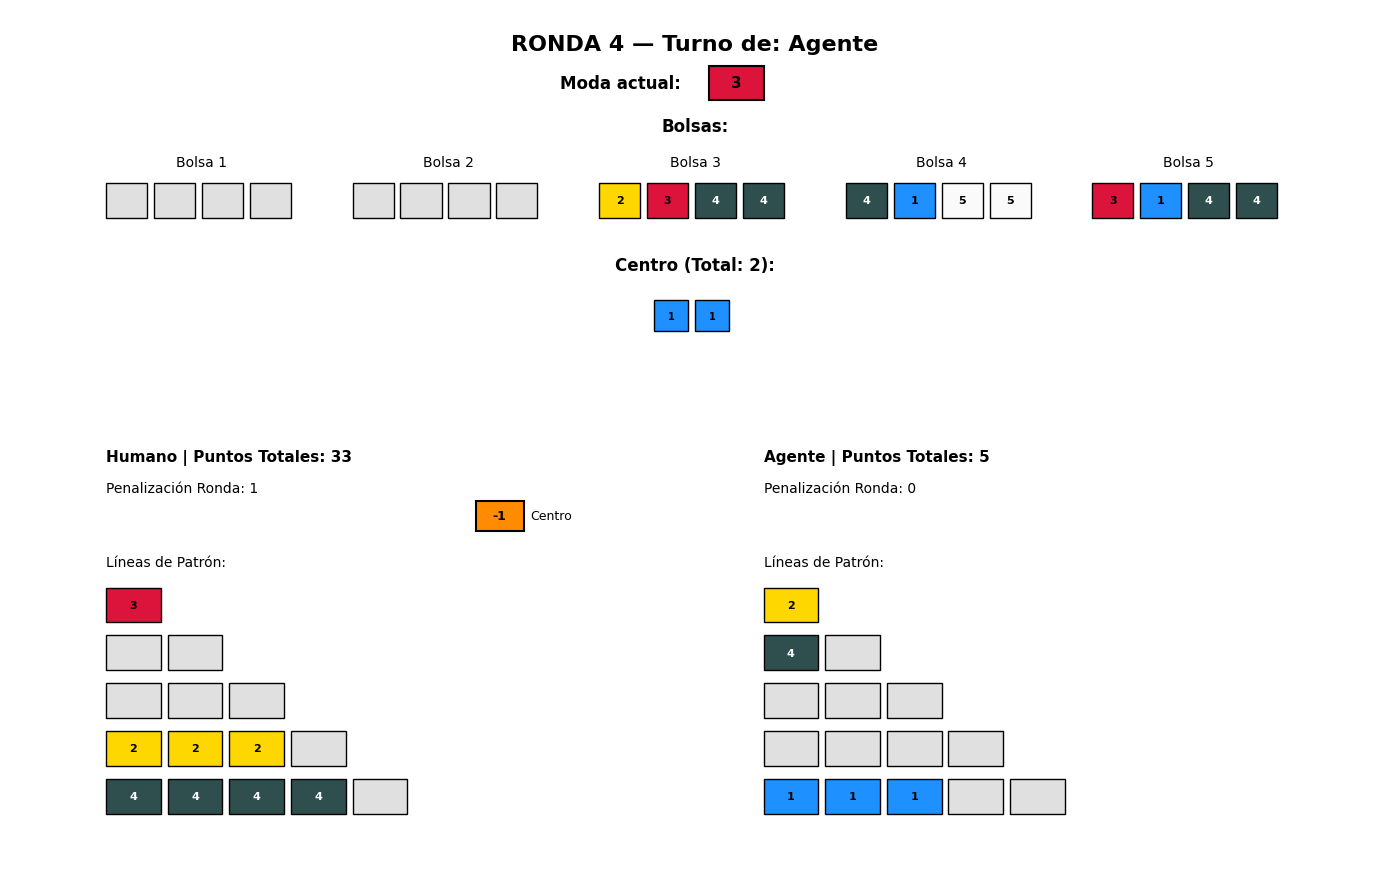


--------------------------------------
TURNO DEL AGENTE
--------------------------------------
Jugada elegida: (0, 1, 4)

Turno de Agente: (0, 1, 4)
Fichas tomadas: 2
Fichas sobrantes: 0


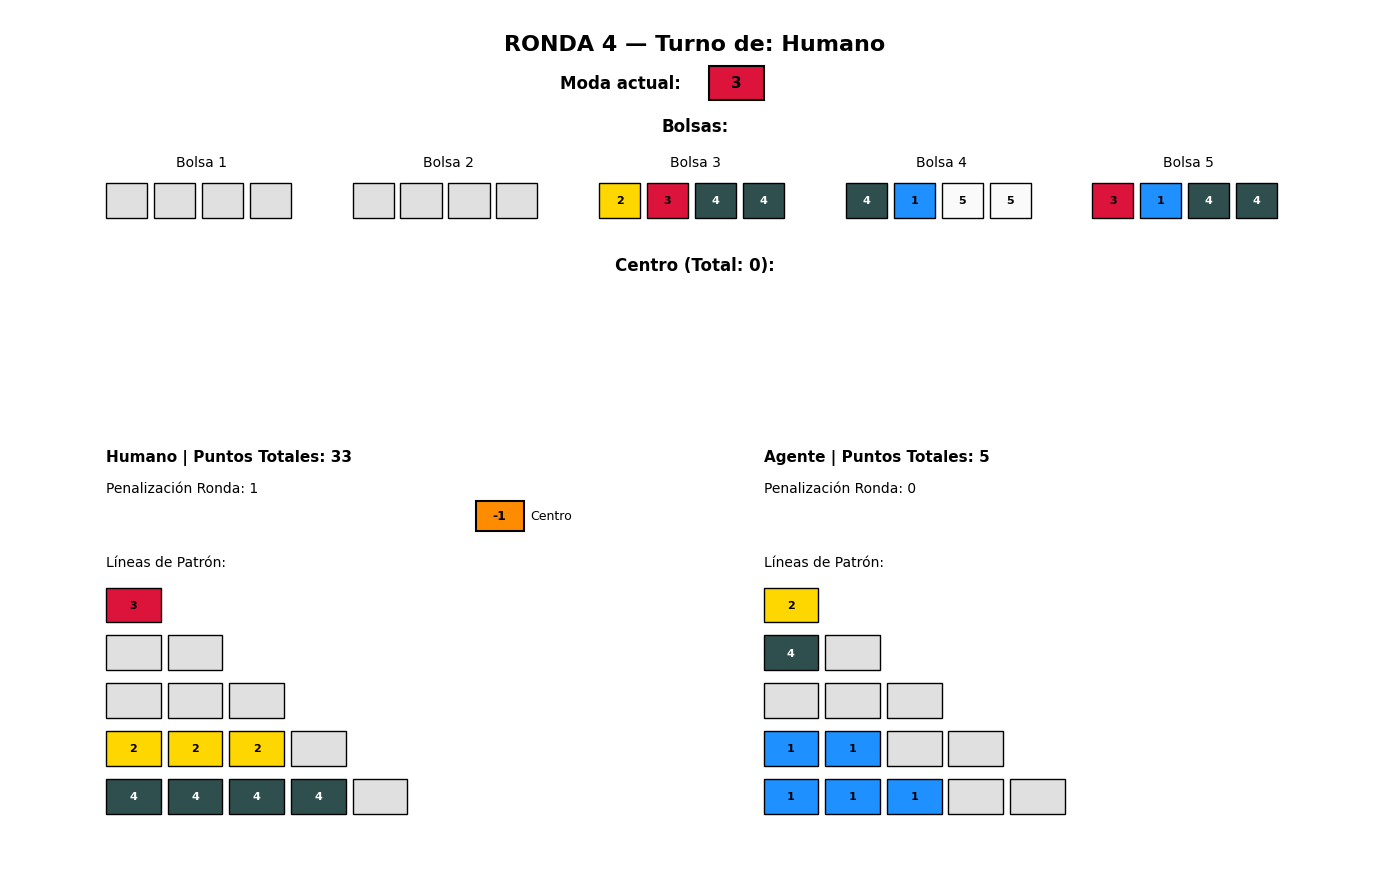


TURNO DEL HUMANO

JUGADAS DISPONIBLES:

  0 -> Bolsa 3    | Color 2 | Descarte
  1 -> Bolsa 3    | Color 2 | Fila 2
  2 -> Bolsa 3    | Color 2 | Fila 3
  3 -> Bolsa 3    | Color 2 | Fila 4
  4 -> Bolsa 3    | Color 3 | Descarte
  5 -> Bolsa 3    | Color 3 | Fila 2
  6 -> Bolsa 3    | Color 3 | Fila 3
  7 -> Bolsa 3    | Color 4 | Descarte
  8 -> Bolsa 3    | Color 4 | Fila 2
  9 -> Bolsa 3    | Color 4 | Fila 3
 10 -> Bolsa 3    | Color 4 | Fila 5
 11 -> Bolsa 4    | Color 1 | Descarte
 12 -> Bolsa 4    | Color 1 | Fila 2
 13 -> Bolsa 4    | Color 1 | Fila 3
 14 -> Bolsa 4    | Color 4 | Descarte
 15 -> Bolsa 4    | Color 4 | Fila 2
 16 -> Bolsa 4    | Color 4 | Fila 3
 17 -> Bolsa 4    | Color 4 | Fila 5
 18 -> Bolsa 4    | Color 5 | Descarte
 19 -> Bolsa 4    | Color 5 | Fila 2
 20 -> Bolsa 4    | Color 5 | Fila 3
 21 -> Bolsa 5    | Color 1 | Descarte
 22 -> Bolsa 5    | Color 1 | Fila 2
 23 -> Bolsa 5    | Color 1 | Fila 3
 24 -> Bolsa 5    | Color 3 | Descarte
 25 -> Bolsa 5    

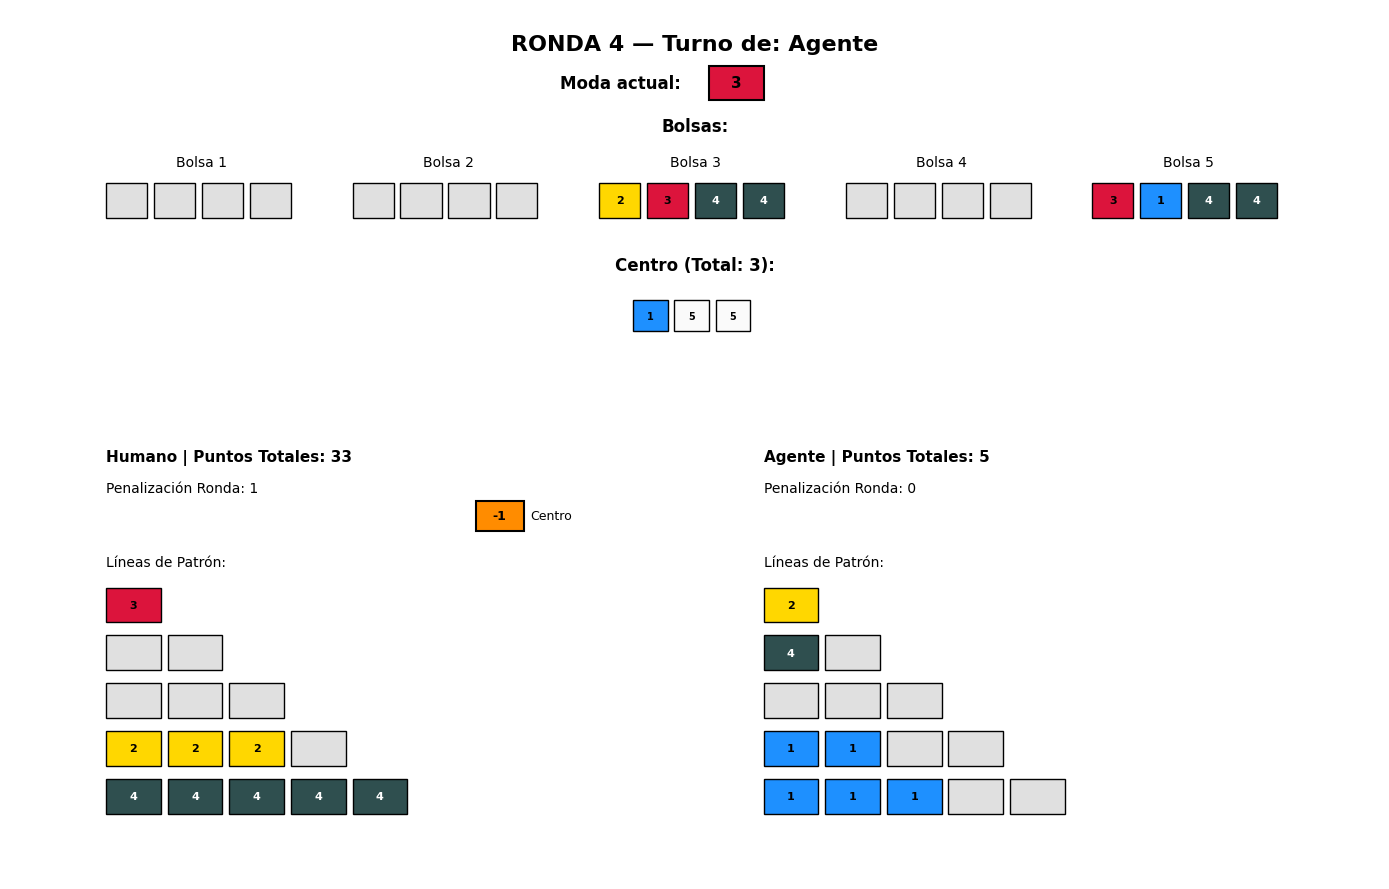


--------------------------------------
TURNO DEL AGENTE
--------------------------------------
Jugada elegida: (0, 1, 4)

Turno de Agente: (0, 1, 4)
Fichas tomadas: 1
Fichas sobrantes: 0


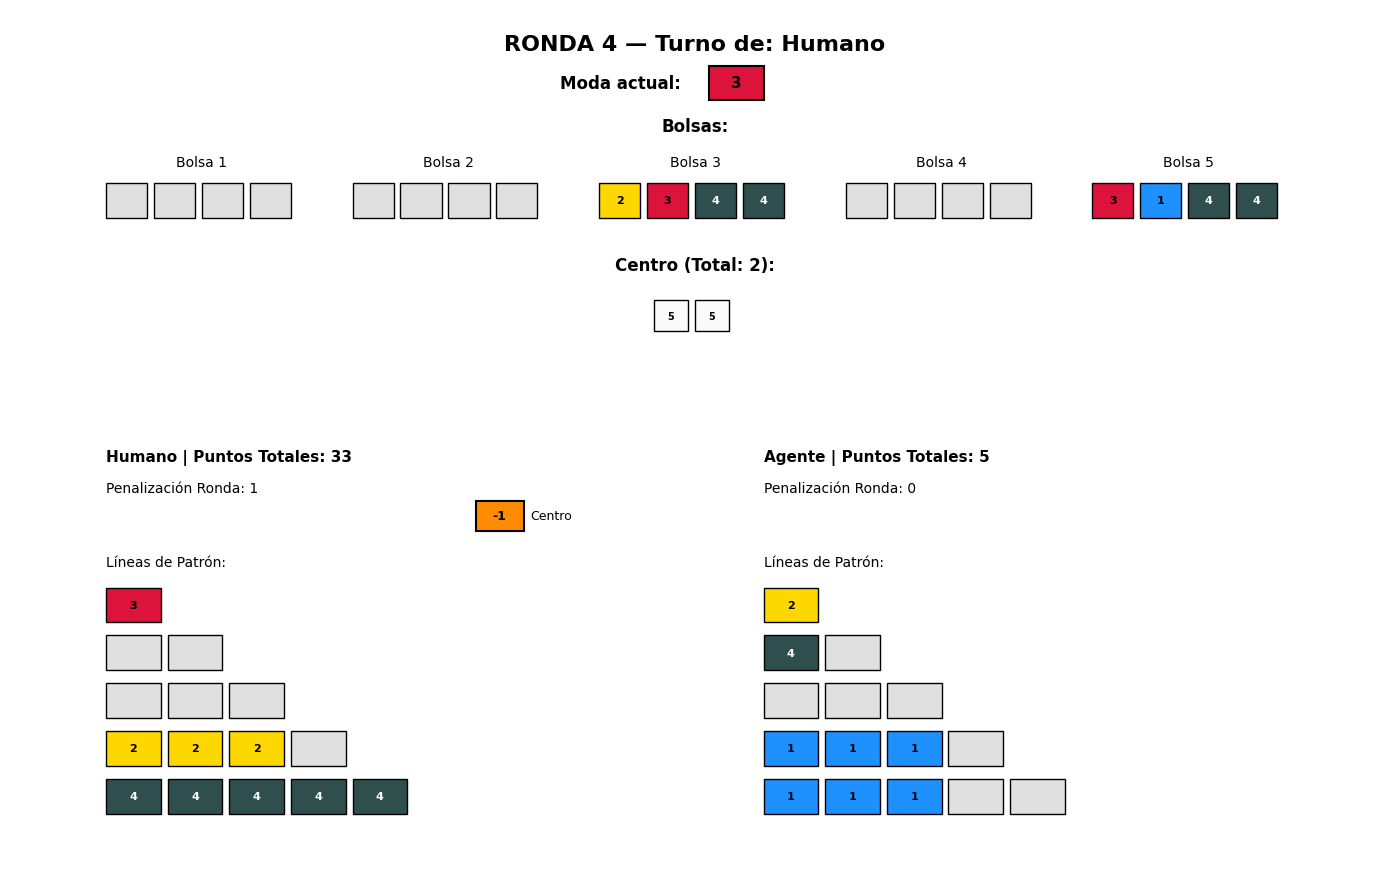


TURNO DEL HUMANO

JUGADAS DISPONIBLES:

  0 -> Centro     | Color 5 | Descarte
  1 -> Centro     | Color 5 | Fila 2
  2 -> Centro     | Color 5 | Fila 3
  3 -> Bolsa 3    | Color 2 | Descarte
  4 -> Bolsa 3    | Color 2 | Fila 2
  5 -> Bolsa 3    | Color 2 | Fila 3
  6 -> Bolsa 3    | Color 2 | Fila 4
  7 -> Bolsa 3    | Color 3 | Descarte
  8 -> Bolsa 3    | Color 3 | Fila 2
  9 -> Bolsa 3    | Color 3 | Fila 3
 10 -> Bolsa 3    | Color 4 | Descarte
 11 -> Bolsa 3    | Color 4 | Fila 2
 12 -> Bolsa 3    | Color 4 | Fila 3
 13 -> Bolsa 5    | Color 1 | Descarte
 14 -> Bolsa 5    | Color 1 | Fila 2
 15 -> Bolsa 5    | Color 1 | Fila 3
 16 -> Bolsa 5    | Color 3 | Descarte
 17 -> Bolsa 5    | Color 3 | Fila 2
 18 -> Bolsa 5    | Color 3 | Fila 3
 19 -> Bolsa 5    | Color 4 | Descarte
 20 -> Bolsa 5    | Color 4 | Fila 2
 21 -> Bolsa 5    | Color 4 | Fila 3

Elige el número de la jugada: 8

Jugada elegida: (3, 3, 2)

Turno de Humano: (3, 3, 2)
Fichas tomadas: 1
Fichas sobrantes: 0


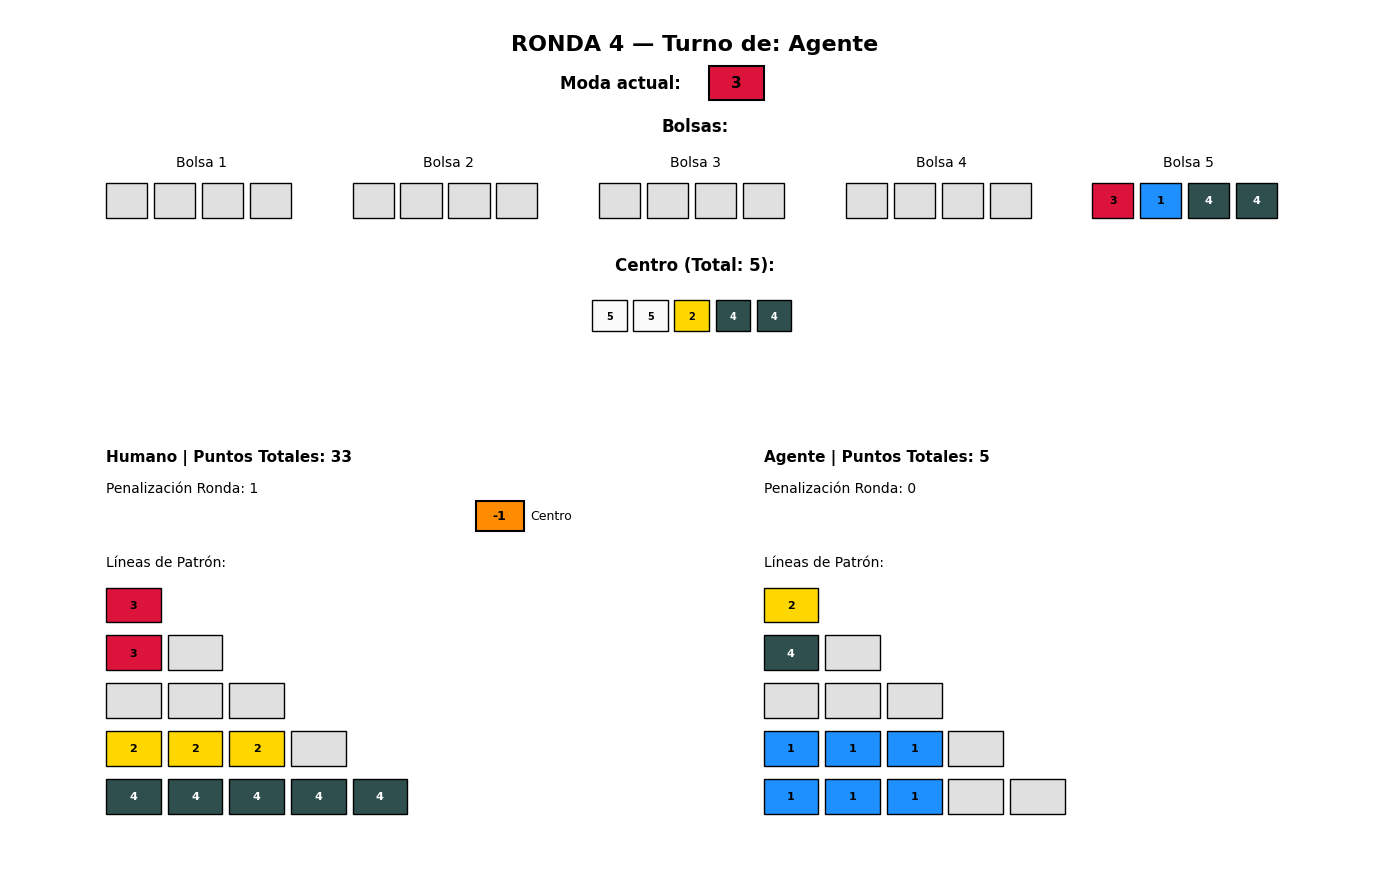


--------------------------------------
TURNO DEL AGENTE
--------------------------------------
Jugada elegida: (5, 4, 3)

Turno de Agente: (5, 4, 3)
Fichas tomadas: 2
Fichas sobrantes: 0


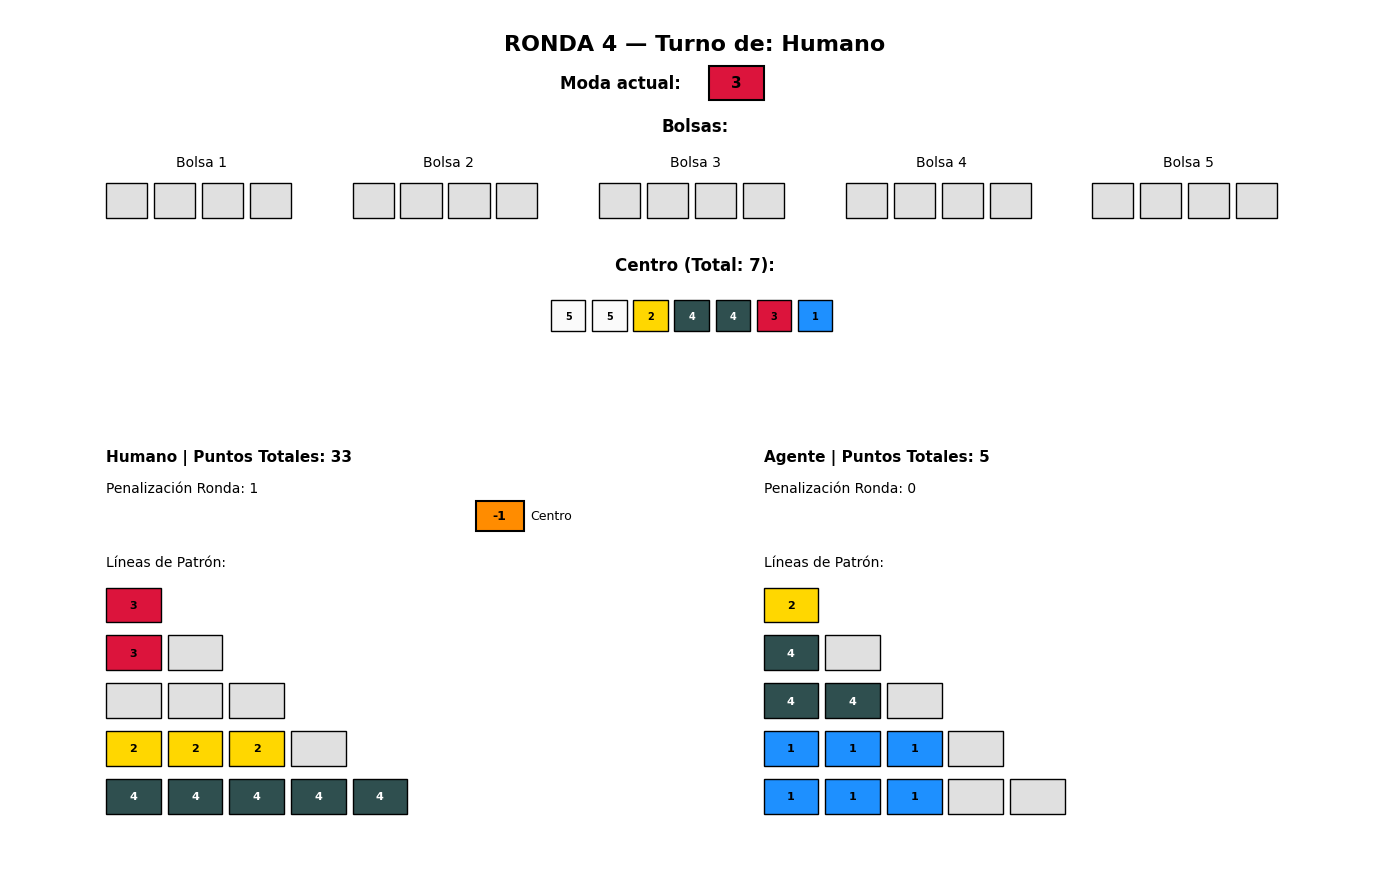


TURNO DEL HUMANO

JUGADAS DISPONIBLES:

  0 -> Centro     | Color 1 | Descarte
  1 -> Centro     | Color 1 | Fila 3
  2 -> Centro     | Color 2 | Descarte
  3 -> Centro     | Color 2 | Fila 3
  4 -> Centro     | Color 2 | Fila 4
  5 -> Centro     | Color 3 | Descarte
  6 -> Centro     | Color 3 | Fila 2
  7 -> Centro     | Color 3 | Fila 3
  8 -> Centro     | Color 4 | Descarte
  9 -> Centro     | Color 4 | Fila 3
 10 -> Centro     | Color 5 | Descarte
 11 -> Centro     | Color 5 | Fila 3

Elige el número de la jugada: 6

Jugada elegida: (0, 3, 2)

Turno de Humano: (0, 3, 2)
Fichas tomadas: 1
Fichas sobrantes: 0


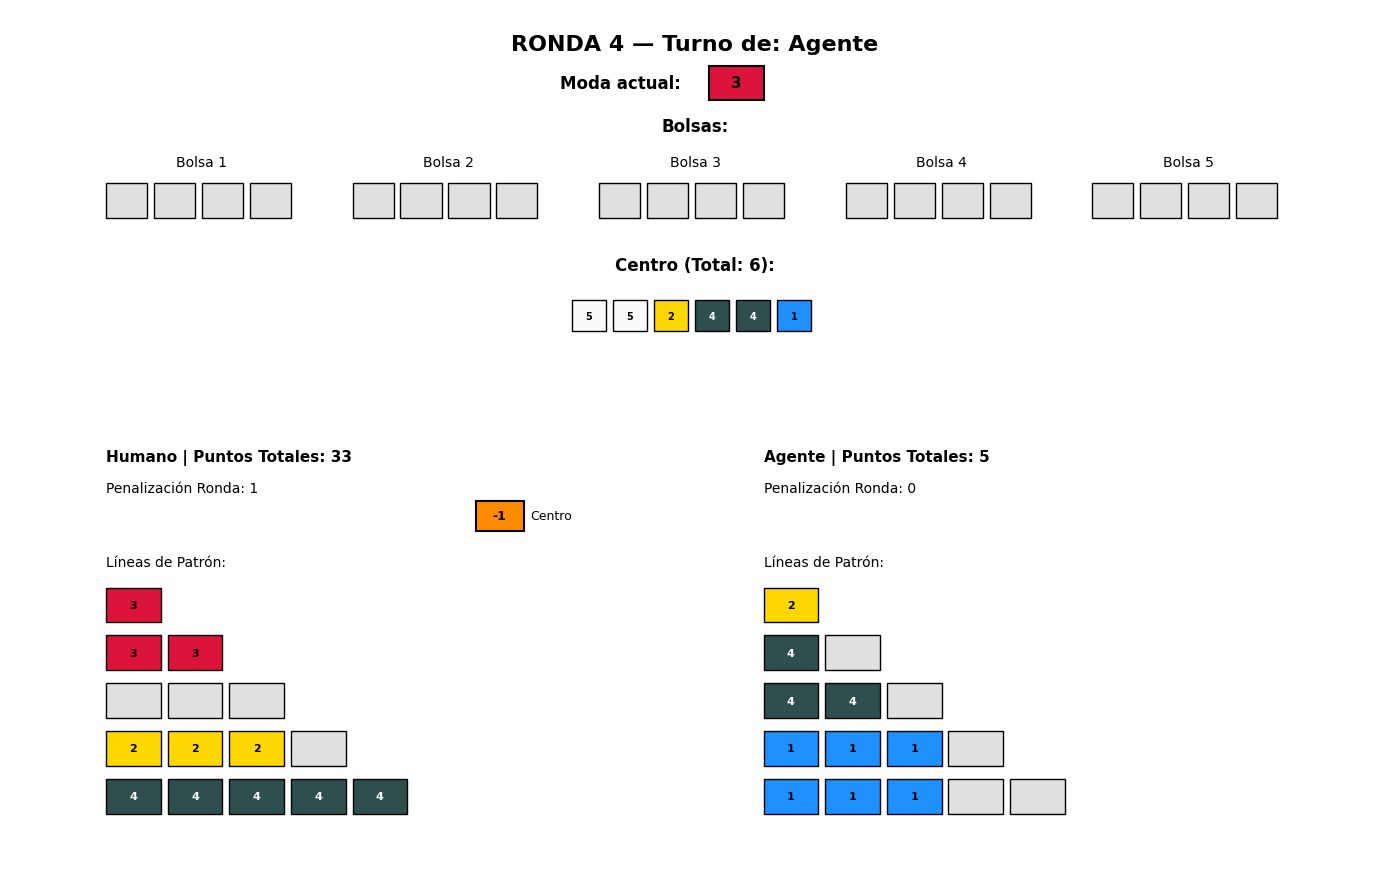


--------------------------------------
TURNO DEL AGENTE
--------------------------------------
Jugada elegida: (0, 1, 4)

Turno de Agente: (0, 1, 4)
Fichas tomadas: 1
Fichas sobrantes: 0


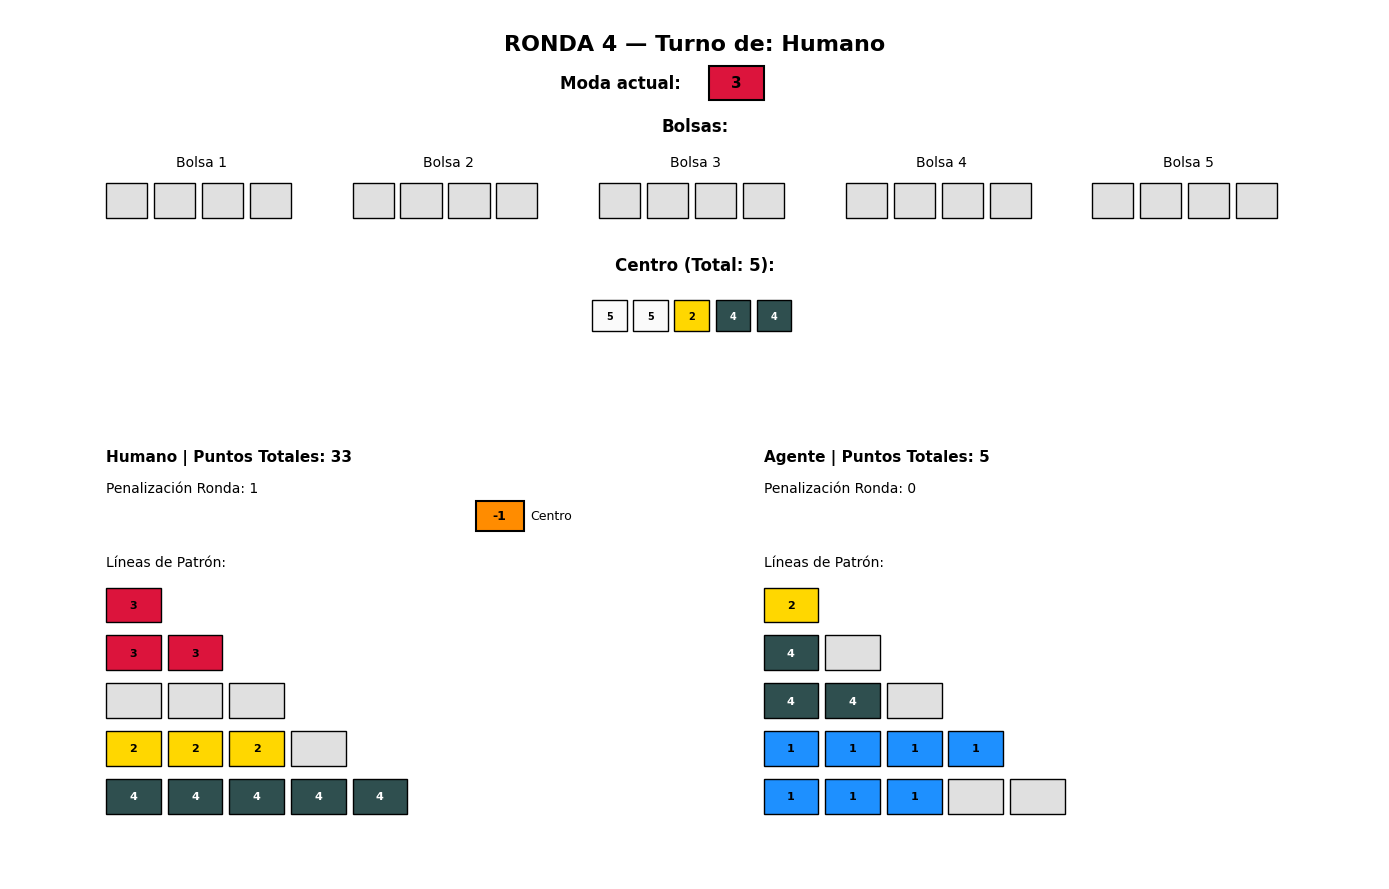


TURNO DEL HUMANO

JUGADAS DISPONIBLES:

  0 -> Centro     | Color 2 | Descarte
  1 -> Centro     | Color 2 | Fila 3
  2 -> Centro     | Color 2 | Fila 4
  3 -> Centro     | Color 4 | Descarte
  4 -> Centro     | Color 4 | Fila 3
  5 -> Centro     | Color 5 | Descarte
  6 -> Centro     | Color 5 | Fila 3

Elige el número de la jugada: 2

Jugada elegida: (0, 2, 4)

Turno de Humano: (0, 2, 4)
Fichas tomadas: 1
Fichas sobrantes: 0


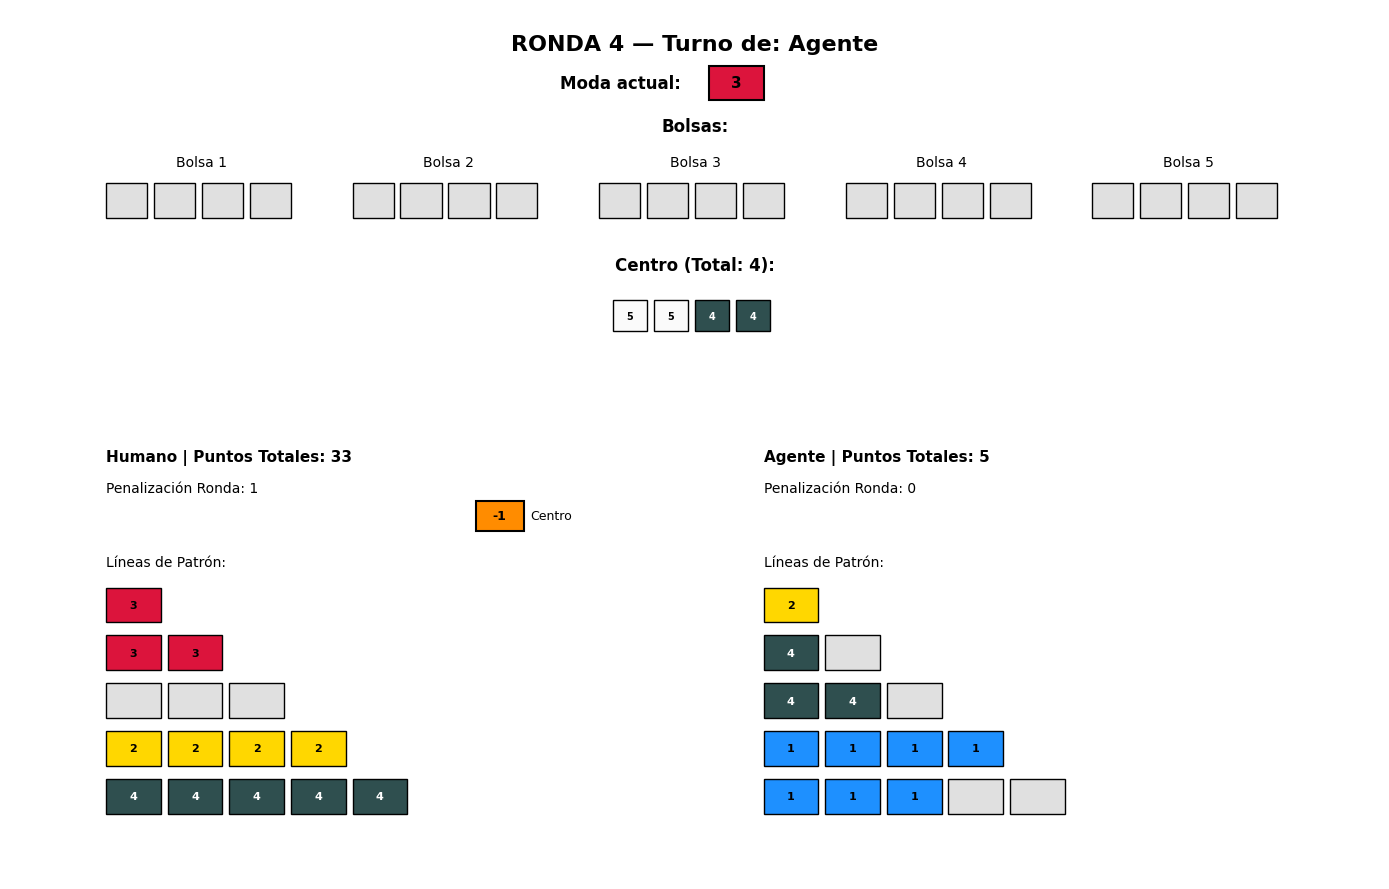


--------------------------------------
TURNO DEL AGENTE
--------------------------------------
Jugada elegida: (0, 4, 3)

Turno de Agente: (0, 4, 3)
Fichas tomadas: 2
Fichas sobrantes: 1


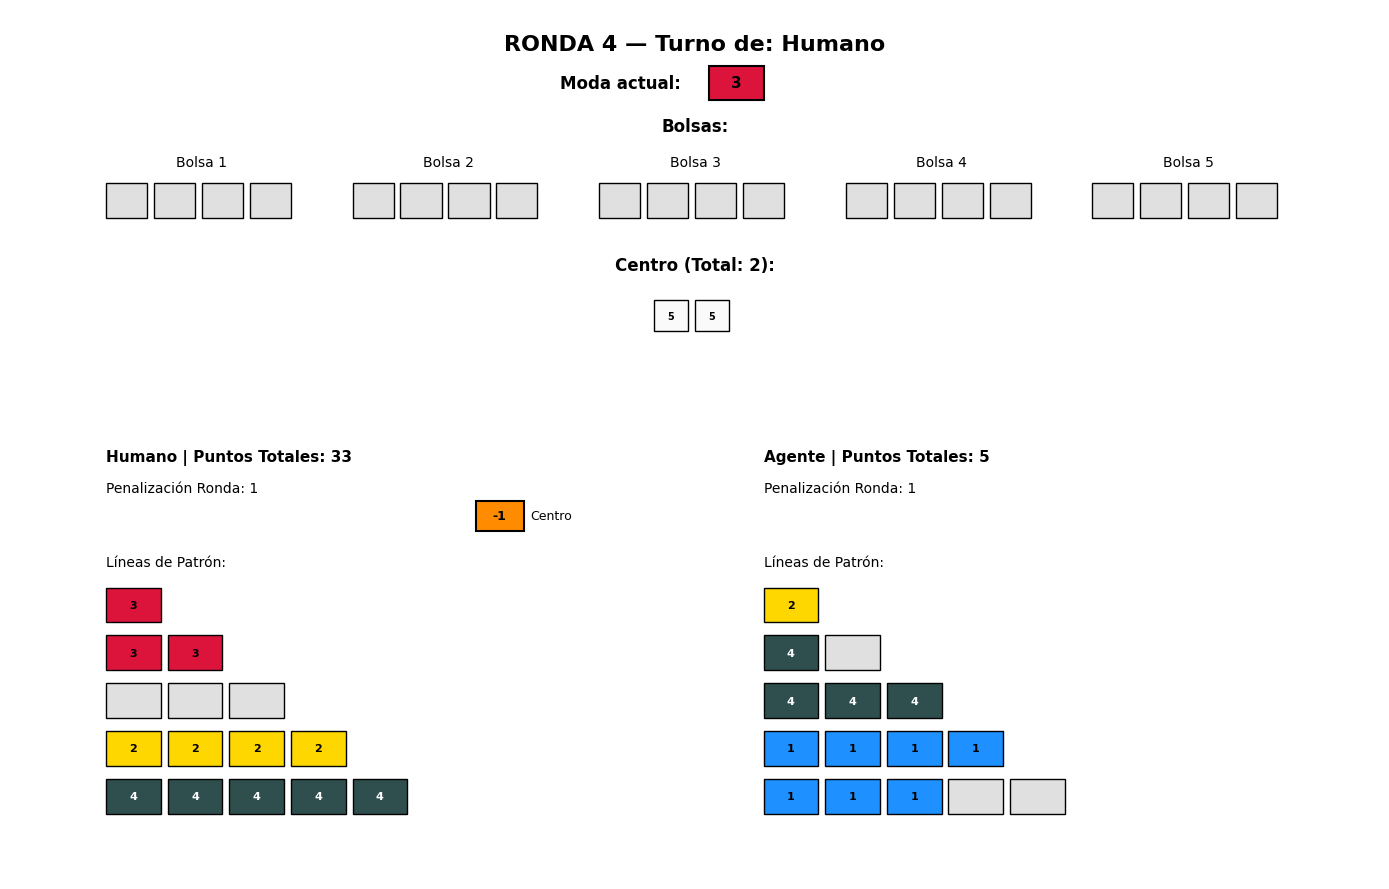


TURNO DEL HUMANO

JUGADAS DISPONIBLES:

  0 -> Centro     | Color 5 | Descarte
  1 -> Centro     | Color 5 | Fila 3

Elige el número de la jugada: 1

Jugada elegida: (0, 5, 3)

Turno de Humano: (0, 5, 3)
Fichas tomadas: 2
Fichas sobrantes: 0

Resultados de la ronda 4
Moda: 3

Humano
Puntos por filas: 12
Puntos por moda: 3
Descuentos: 1
Puntos de la ronda: 14
Total acumulado: 47

Agente
Puntos por filas: 8
Puntos por moda: 0
Descuentos: 1
Puntos de la ronda: 7
Total acumulado: 12

========== RONDA 5 ==========
Moda de la ronda: 2


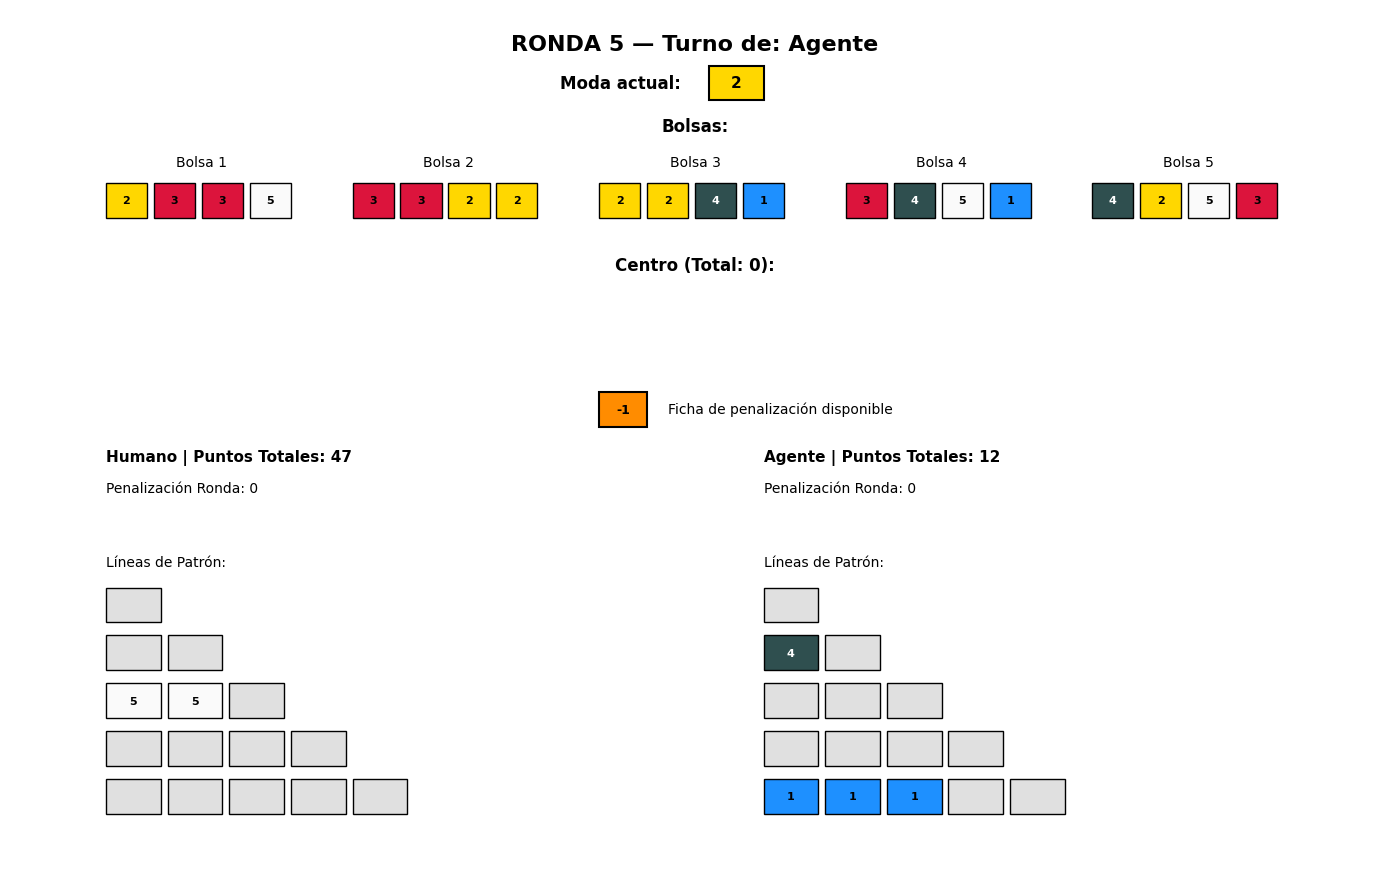


--------------------------------------
TURNO DEL AGENTE
--------------------------------------
Jugada elegida: (1, 3, 3)

Turno de Agente: (1, 3, 3)
Fichas tomadas: 2
Fichas sobrantes: 0


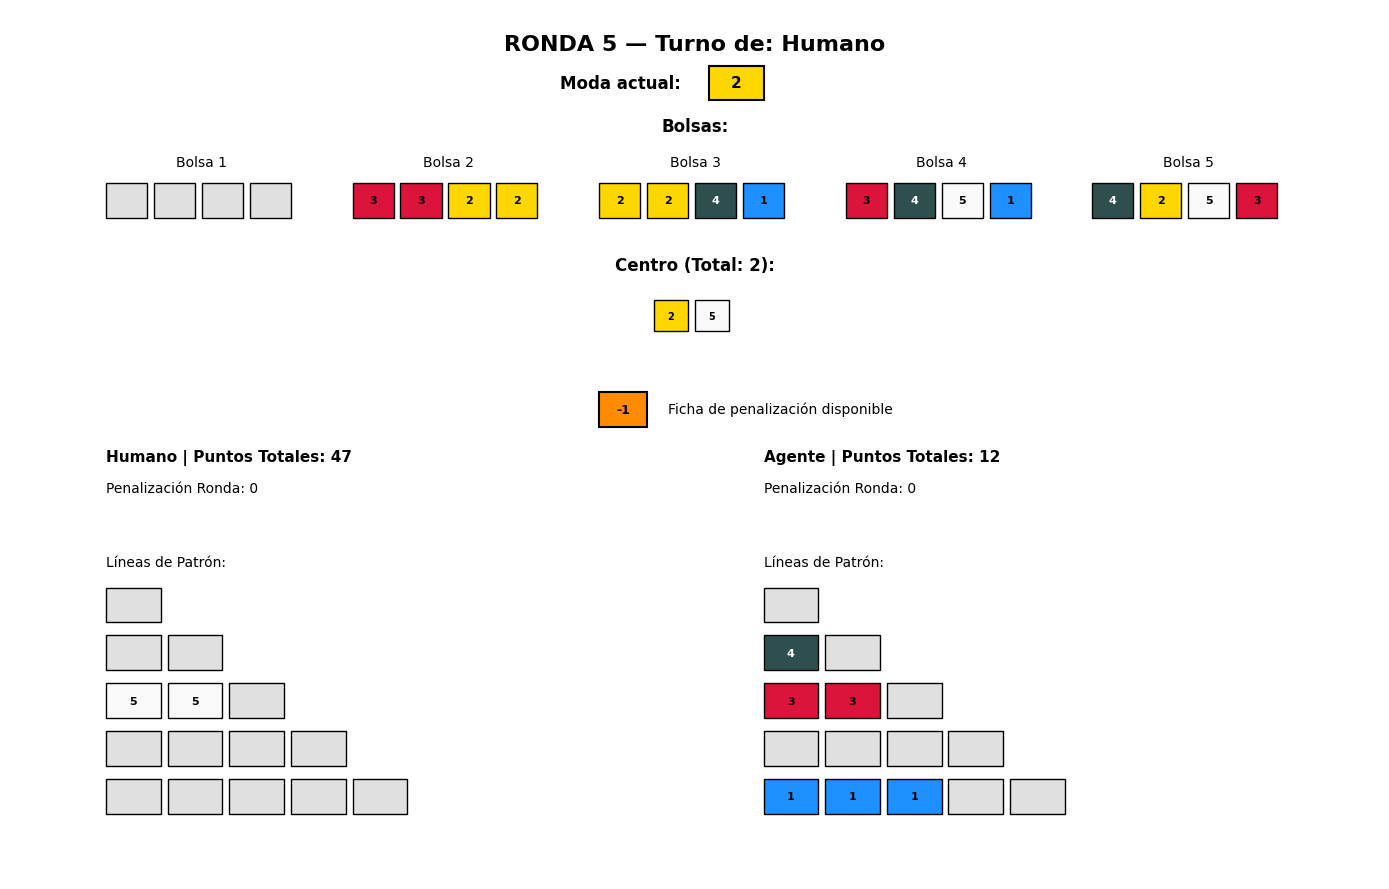


TURNO DEL HUMANO

JUGADAS DISPONIBLES:

  0 -> Centro     | Color 2 | Descarte
  1 -> Centro     | Color 2 | Fila 1
  2 -> Centro     | Color 2 | Fila 2
  3 -> Centro     | Color 2 | Fila 4
  4 -> Centro     | Color 2 | Fila 5
  5 -> Centro     | Color 5 | Descarte
  6 -> Centro     | Color 5 | Fila 1
  7 -> Centro     | Color 5 | Fila 2
  8 -> Centro     | Color 5 | Fila 3
  9 -> Centro     | Color 5 | Fila 4
 10 -> Centro     | Color 5 | Fila 5
 11 -> Bolsa 2    | Color 2 | Descarte
 12 -> Bolsa 2    | Color 2 | Fila 1
 13 -> Bolsa 2    | Color 2 | Fila 2
 14 -> Bolsa 2    | Color 2 | Fila 4
 15 -> Bolsa 2    | Color 2 | Fila 5
 16 -> Bolsa 2    | Color 3 | Descarte
 17 -> Bolsa 2    | Color 3 | Fila 1
 18 -> Bolsa 2    | Color 3 | Fila 2
 19 -> Bolsa 2    | Color 3 | Fila 4
 20 -> Bolsa 2    | Color 3 | Fila 5
 21 -> Bolsa 3    | Color 1 | Descarte
 22 -> Bolsa 3    | Color 1 | Fila 1
 23 -> Bolsa 3    | Color 1 | Fila 2
 24 -> Bolsa 3    | Color 1 | Fila 4
 25 -> Bolsa 3    | Colo

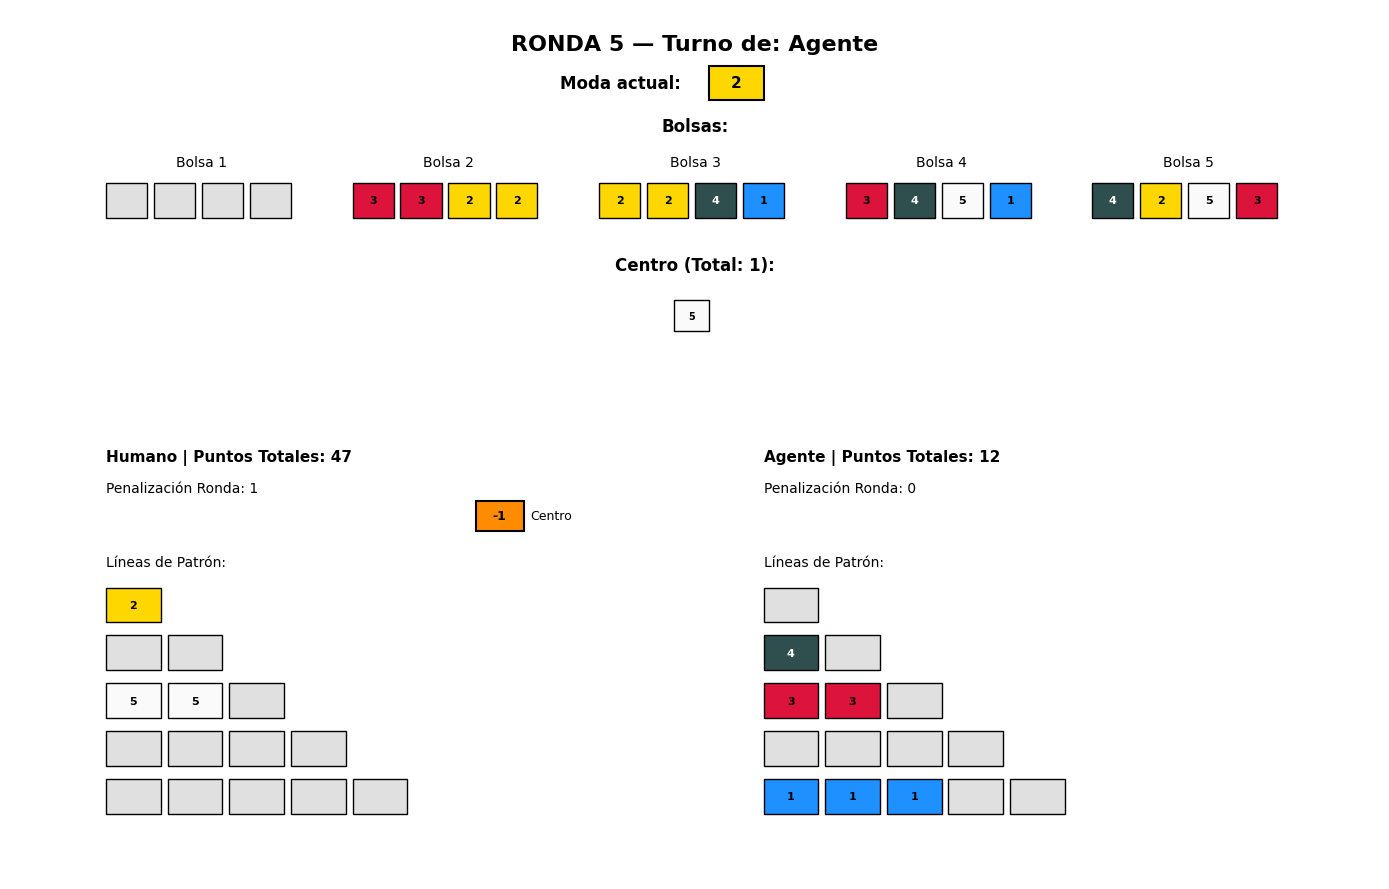


--------------------------------------
TURNO DEL AGENTE
--------------------------------------
Jugada elegida: (4, 3, 4)

Turno de Agente: (4, 3, 4)
Fichas tomadas: 1
Fichas sobrantes: 0


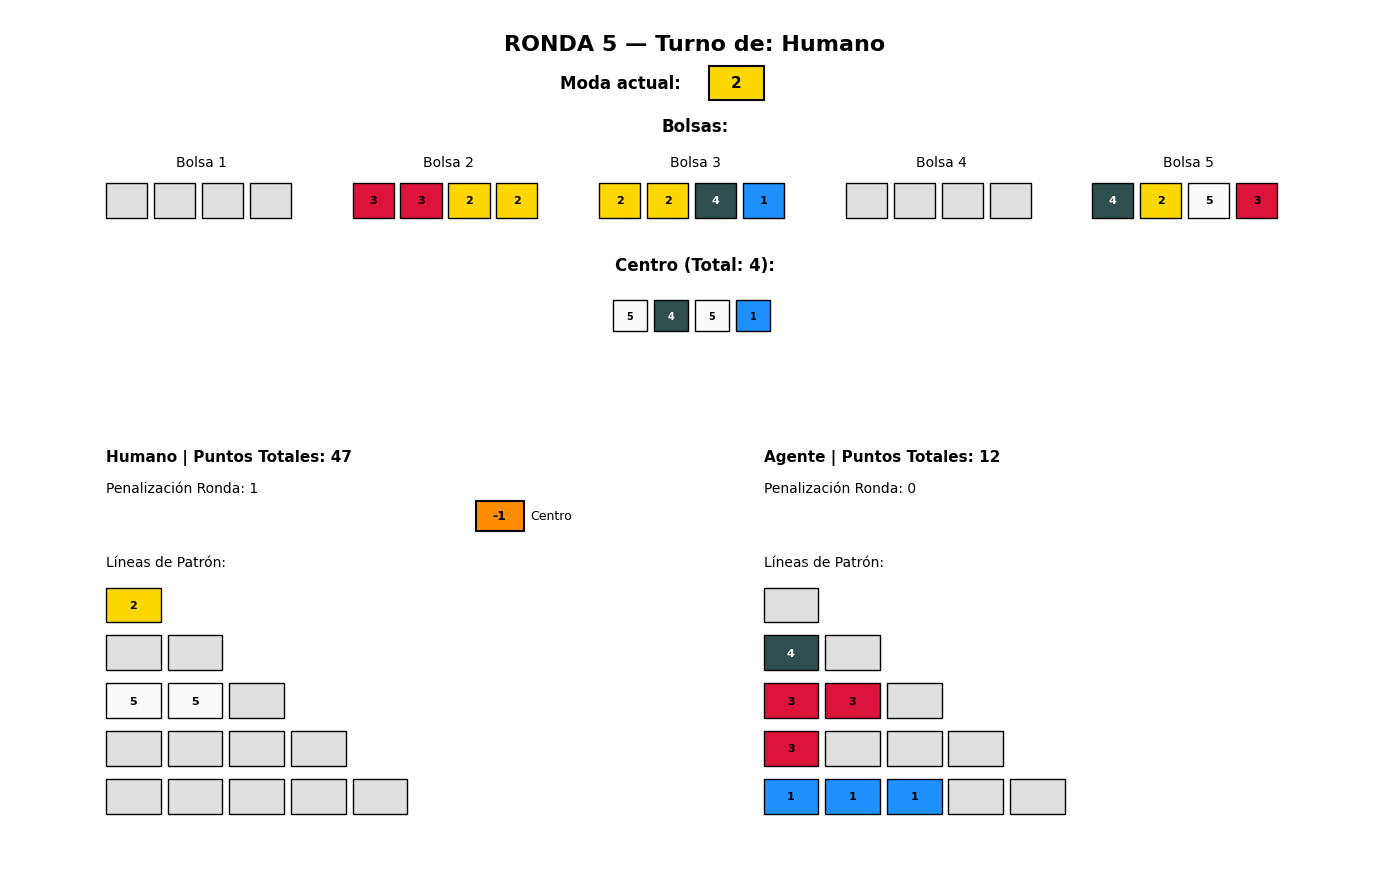


TURNO DEL HUMANO

JUGADAS DISPONIBLES:

  0 -> Centro     | Color 1 | Descarte
  1 -> Centro     | Color 1 | Fila 2
  2 -> Centro     | Color 1 | Fila 4
  3 -> Centro     | Color 1 | Fila 5
  4 -> Centro     | Color 4 | Descarte
  5 -> Centro     | Color 4 | Fila 2
  6 -> Centro     | Color 4 | Fila 4
  7 -> Centro     | Color 4 | Fila 5
  8 -> Centro     | Color 5 | Descarte
  9 -> Centro     | Color 5 | Fila 2
 10 -> Centro     | Color 5 | Fila 3
 11 -> Centro     | Color 5 | Fila 4
 12 -> Centro     | Color 5 | Fila 5
 13 -> Bolsa 2    | Color 2 | Descarte
 14 -> Bolsa 2    | Color 2 | Fila 2
 15 -> Bolsa 2    | Color 2 | Fila 4
 16 -> Bolsa 2    | Color 2 | Fila 5
 17 -> Bolsa 2    | Color 3 | Descarte
 18 -> Bolsa 2    | Color 3 | Fila 2
 19 -> Bolsa 2    | Color 3 | Fila 4
 20 -> Bolsa 2    | Color 3 | Fila 5
 21 -> Bolsa 3    | Color 1 | Descarte
 22 -> Bolsa 3    | Color 1 | Fila 2
 23 -> Bolsa 3    | Color 1 | Fila 4
 24 -> Bolsa 3    | Color 1 | Fila 5
 25 -> Bolsa 3    | Co

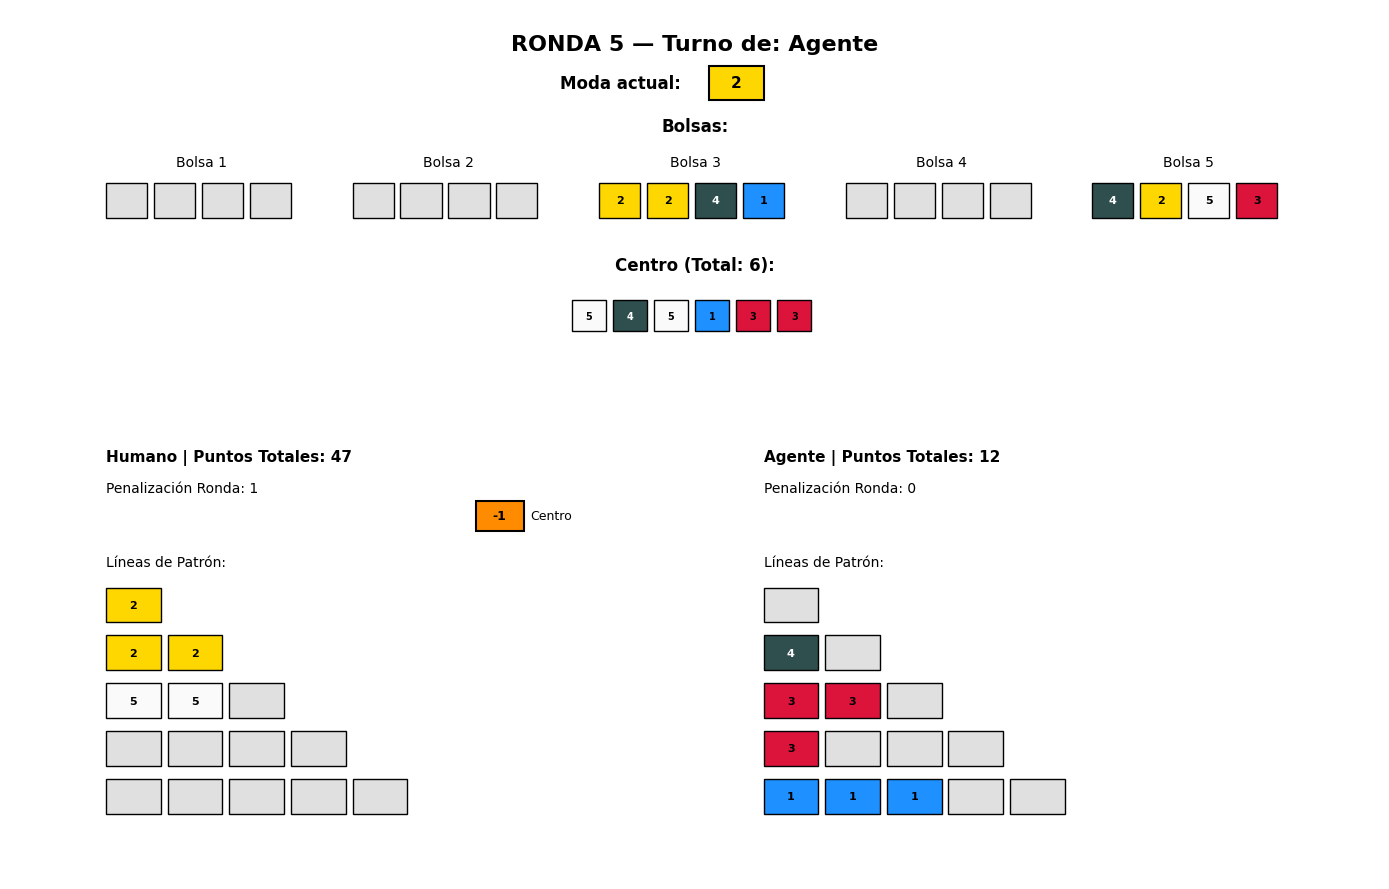


--------------------------------------
TURNO DEL AGENTE
--------------------------------------
Jugada elegida: (0, 3, 3)

Turno de Agente: (0, 3, 3)
Fichas tomadas: 2
Fichas sobrantes: 1


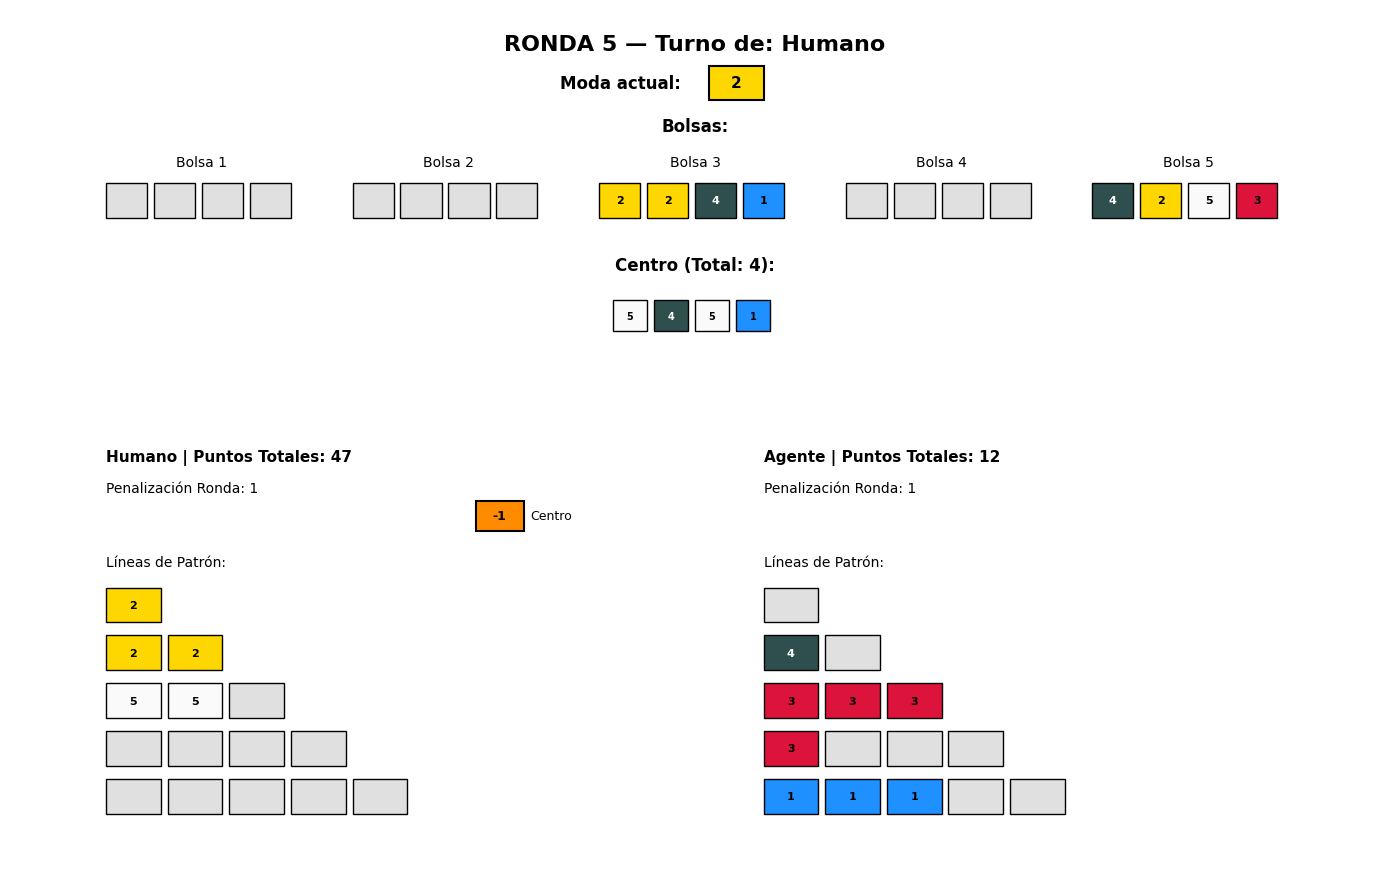


TURNO DEL HUMANO

JUGADAS DISPONIBLES:

  0 -> Centro     | Color 1 | Descarte
  1 -> Centro     | Color 1 | Fila 4
  2 -> Centro     | Color 1 | Fila 5
  3 -> Centro     | Color 4 | Descarte
  4 -> Centro     | Color 4 | Fila 4
  5 -> Centro     | Color 4 | Fila 5
  6 -> Centro     | Color 5 | Descarte
  7 -> Centro     | Color 5 | Fila 3
  8 -> Centro     | Color 5 | Fila 4
  9 -> Centro     | Color 5 | Fila 5
 10 -> Bolsa 3    | Color 1 | Descarte
 11 -> Bolsa 3    | Color 1 | Fila 4
 12 -> Bolsa 3    | Color 1 | Fila 5
 13 -> Bolsa 3    | Color 2 | Descarte
 14 -> Bolsa 3    | Color 2 | Fila 4
 15 -> Bolsa 3    | Color 2 | Fila 5
 16 -> Bolsa 3    | Color 4 | Descarte
 17 -> Bolsa 3    | Color 4 | Fila 4
 18 -> Bolsa 3    | Color 4 | Fila 5
 19 -> Bolsa 5    | Color 2 | Descarte
 20 -> Bolsa 5    | Color 2 | Fila 4
 21 -> Bolsa 5    | Color 2 | Fila 5
 22 -> Bolsa 5    | Color 3 | Descarte
 23 -> Bolsa 5    | Color 3 | Fila 4
 24 -> Bolsa 5    | Color 3 | Fila 5
 25 -> Bolsa 5    

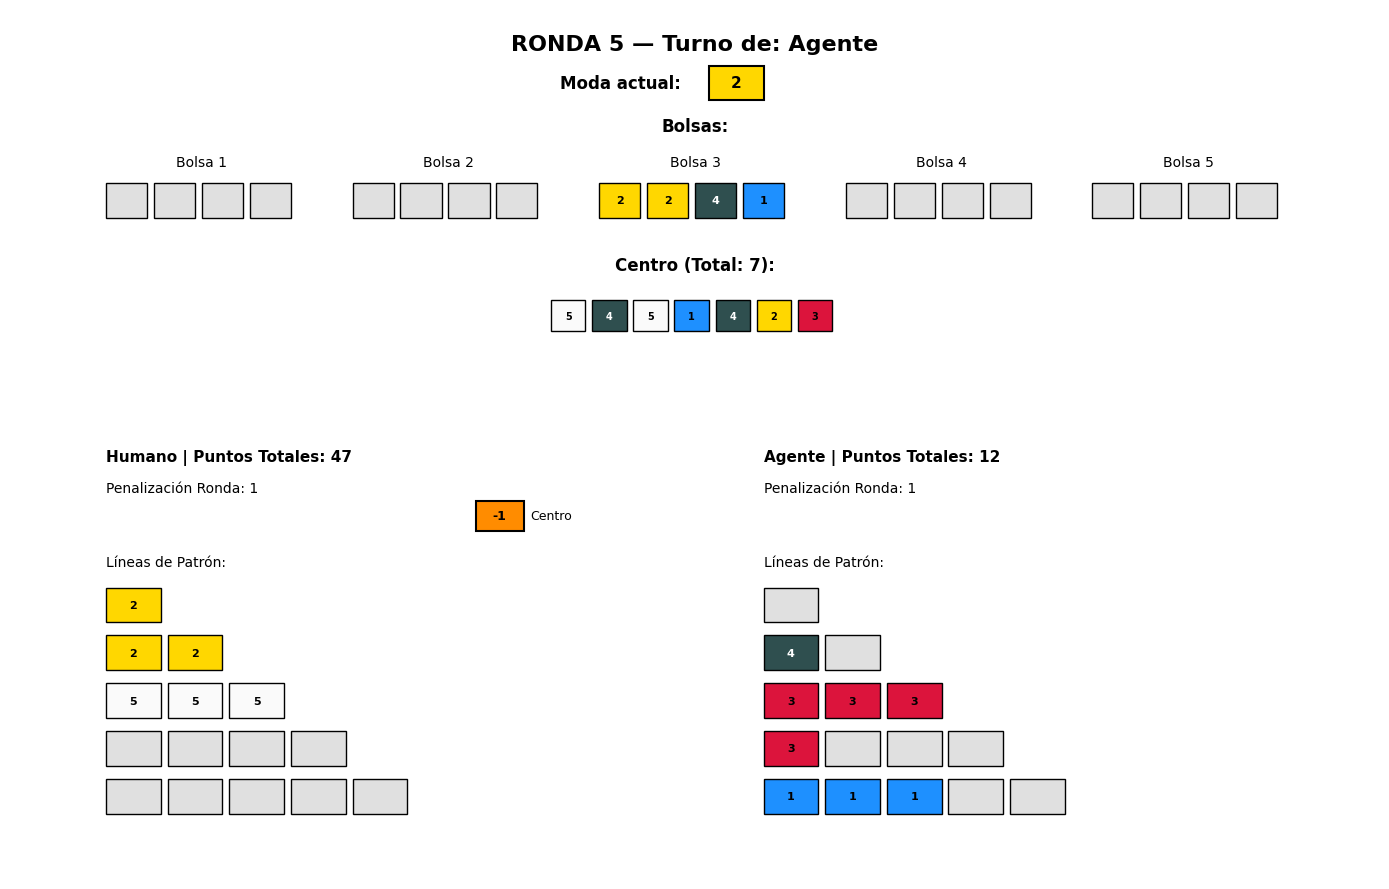


--------------------------------------
TURNO DEL AGENTE
--------------------------------------
Jugada elegida: (0, 1, 5)

Turno de Agente: (0, 1, 5)
Fichas tomadas: 1
Fichas sobrantes: 0


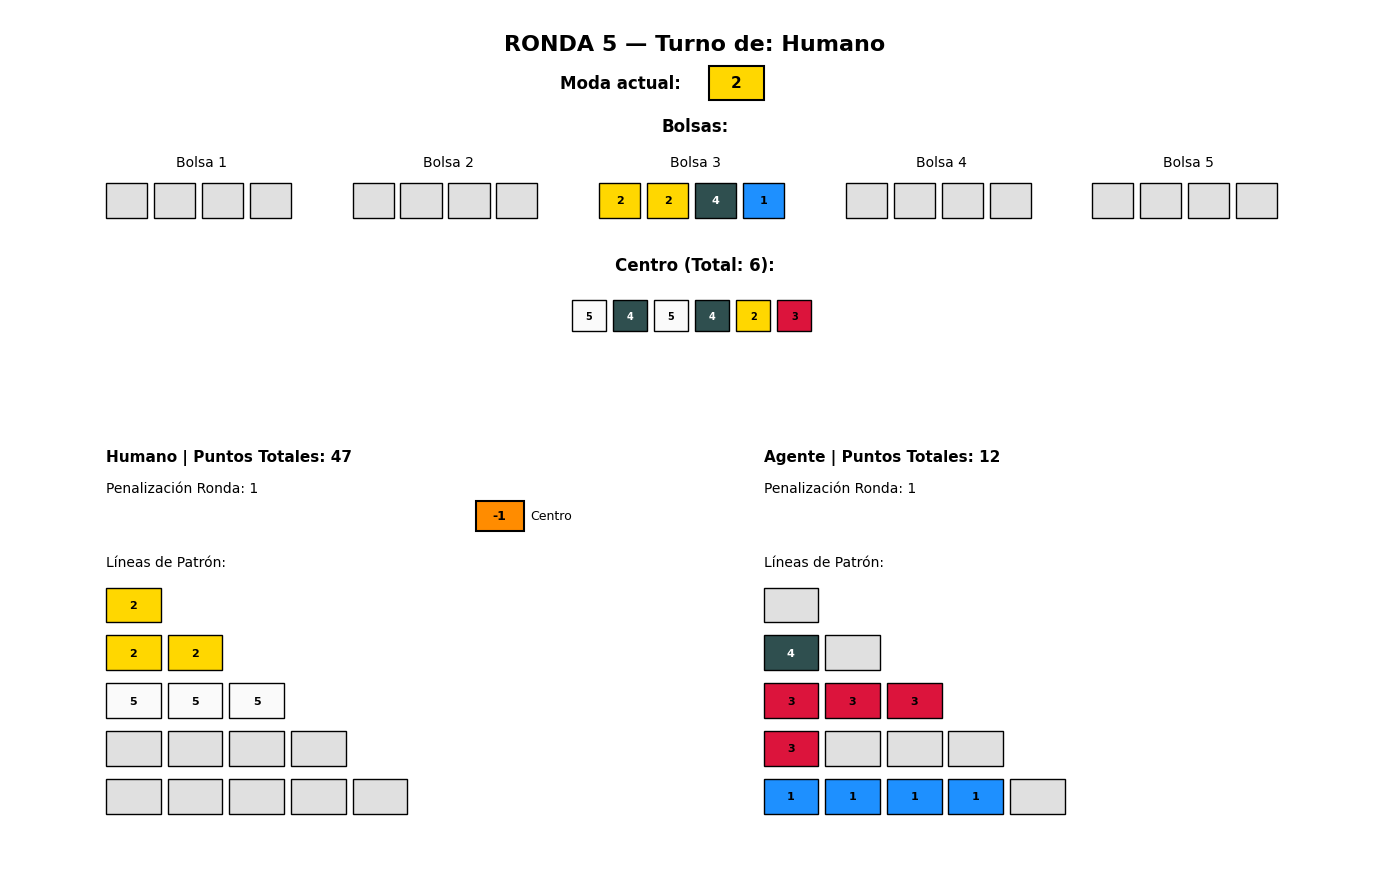


TURNO DEL HUMANO

JUGADAS DISPONIBLES:

  0 -> Centro     | Color 2 | Descarte
  1 -> Centro     | Color 2 | Fila 4
  2 -> Centro     | Color 2 | Fila 5
  3 -> Centro     | Color 3 | Descarte
  4 -> Centro     | Color 3 | Fila 4
  5 -> Centro     | Color 3 | Fila 5
  6 -> Centro     | Color 4 | Descarte
  7 -> Centro     | Color 4 | Fila 4
  8 -> Centro     | Color 4 | Fila 5
  9 -> Centro     | Color 5 | Descarte
 10 -> Centro     | Color 5 | Fila 4
 11 -> Centro     | Color 5 | Fila 5
 12 -> Bolsa 3    | Color 1 | Descarte
 13 -> Bolsa 3    | Color 1 | Fila 4
 14 -> Bolsa 3    | Color 1 | Fila 5
 15 -> Bolsa 3    | Color 2 | Descarte
 16 -> Bolsa 3    | Color 2 | Fila 4
 17 -> Bolsa 3    | Color 2 | Fila 5
 18 -> Bolsa 3    | Color 4 | Descarte
 19 -> Bolsa 3    | Color 4 | Fila 4
 20 -> Bolsa 3    | Color 4 | Fila 5

Elige el número de la jugada: 16

Jugada elegida: (3, 2, 4)

Turno de Humano: (3, 2, 4)
Fichas tomadas: 2
Fichas sobrantes: 0


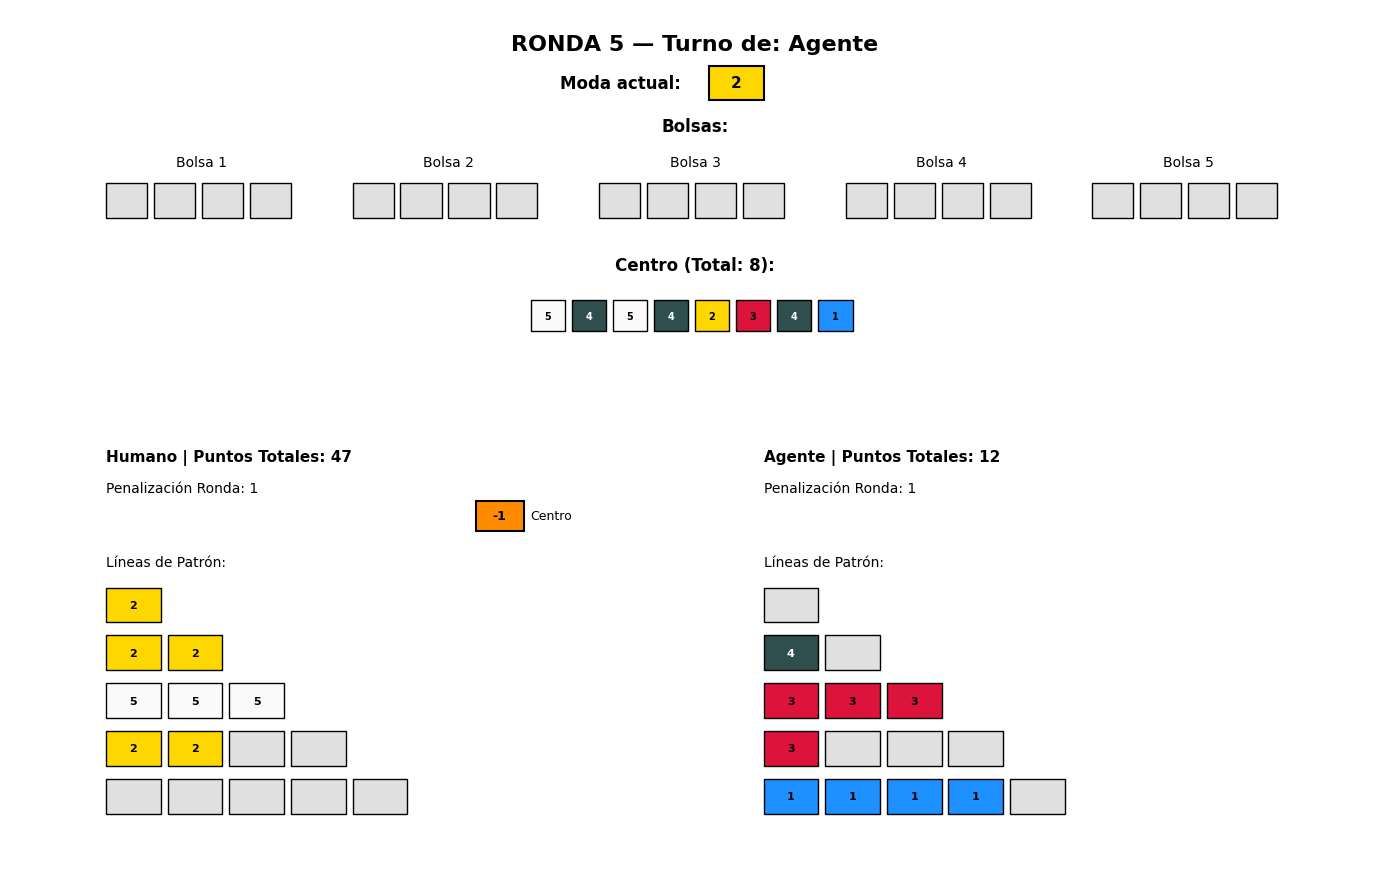


--------------------------------------
TURNO DEL AGENTE
--------------------------------------
Jugada elegida: (0, 1, 5)

Turno de Agente: (0, 1, 5)
Fichas tomadas: 1
Fichas sobrantes: 0


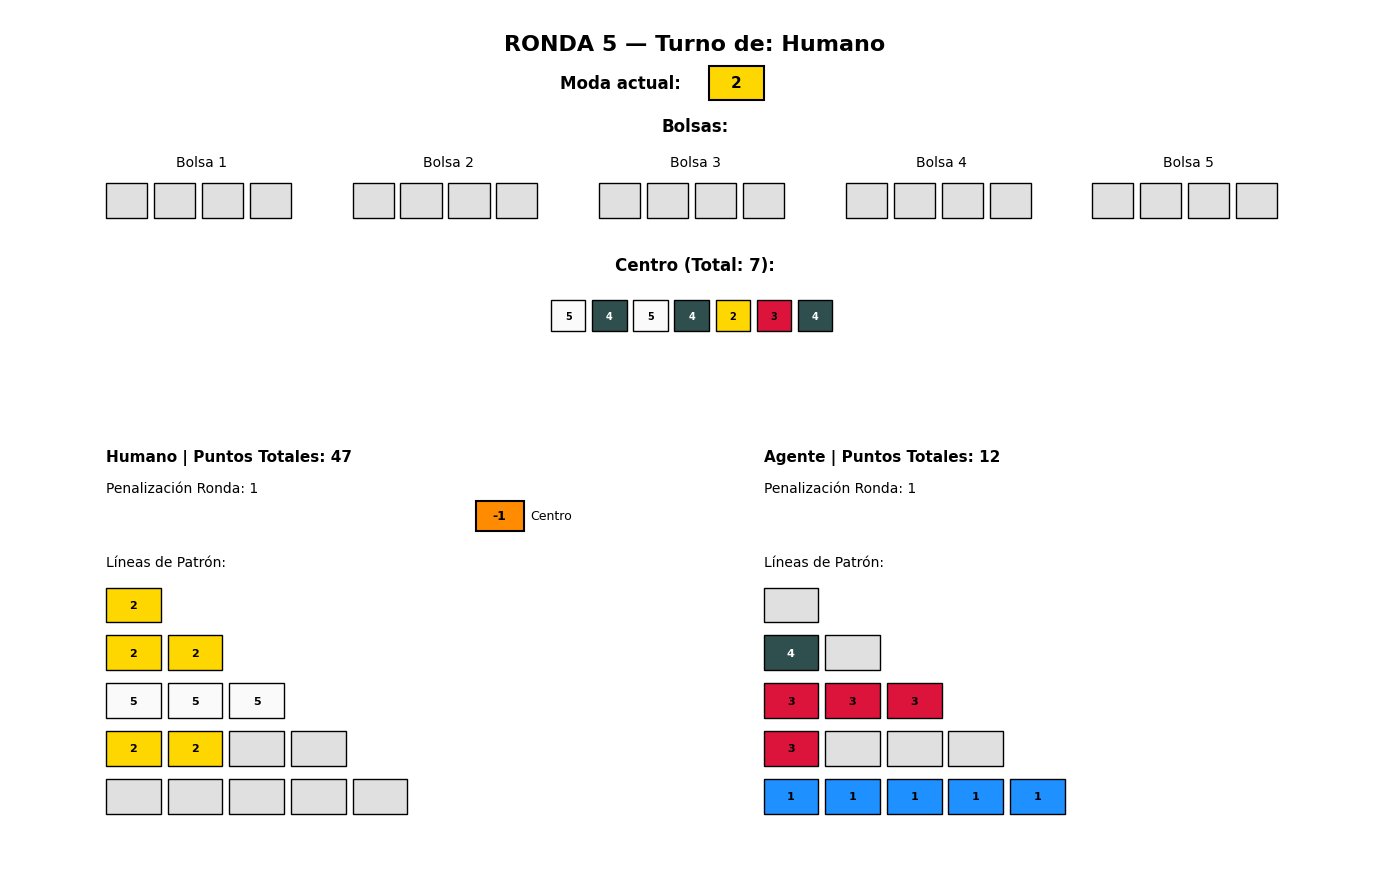


TURNO DEL HUMANO

JUGADAS DISPONIBLES:

  0 -> Centro     | Color 2 | Descarte
  1 -> Centro     | Color 2 | Fila 4
  2 -> Centro     | Color 2 | Fila 5
  3 -> Centro     | Color 3 | Descarte
  4 -> Centro     | Color 3 | Fila 5
  5 -> Centro     | Color 4 | Descarte
  6 -> Centro     | Color 4 | Fila 5
  7 -> Centro     | Color 5 | Descarte
  8 -> Centro     | Color 5 | Fila 5

Elige el número de la jugada: 1

Jugada elegida: (0, 2, 4)

Turno de Humano: (0, 2, 4)
Fichas tomadas: 1
Fichas sobrantes: 0


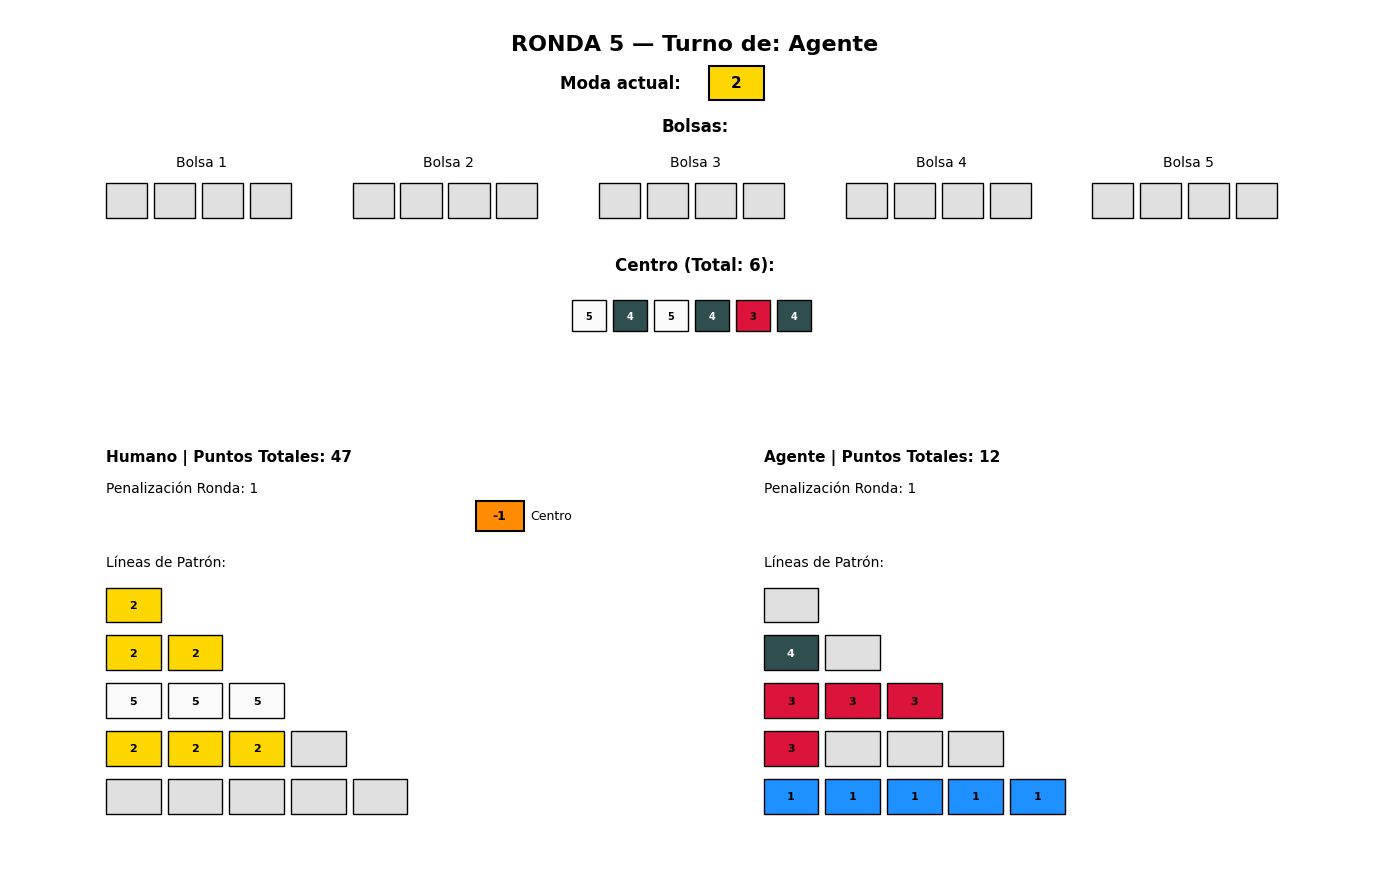


--------------------------------------
TURNO DEL AGENTE
--------------------------------------
Jugada elegida: (0, 3, 4)

Turno de Agente: (0, 3, 4)
Fichas tomadas: 1
Fichas sobrantes: 0


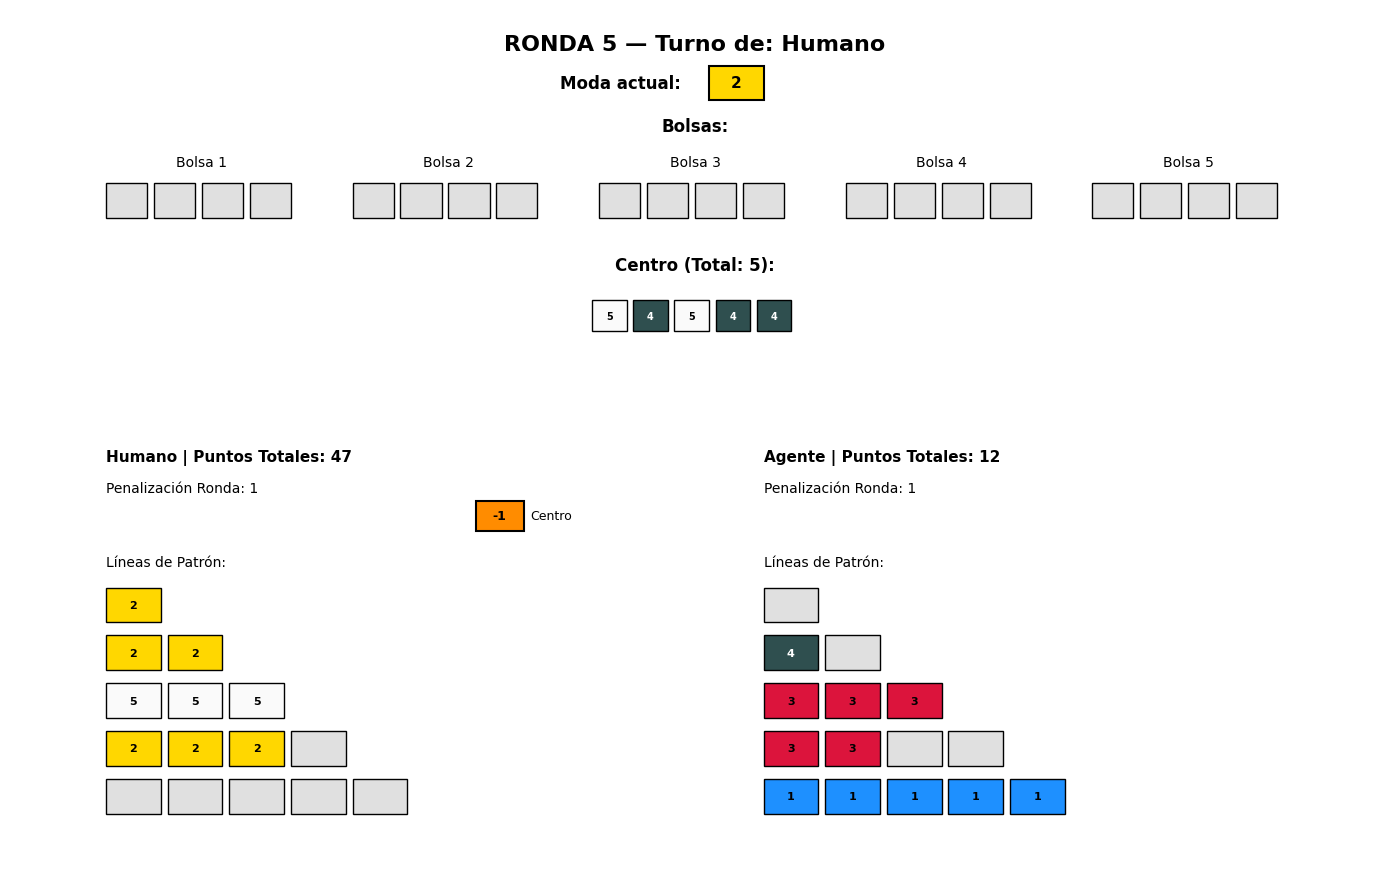


TURNO DEL HUMANO

JUGADAS DISPONIBLES:

  0 -> Centro     | Color 4 | Descarte
  1 -> Centro     | Color 4 | Fila 5
  2 -> Centro     | Color 5 | Descarte
  3 -> Centro     | Color 5 | Fila 5

Elige el número de la jugada: 1

Jugada elegida: (0, 4, 5)

Turno de Humano: (0, 4, 5)
Fichas tomadas: 3
Fichas sobrantes: 0


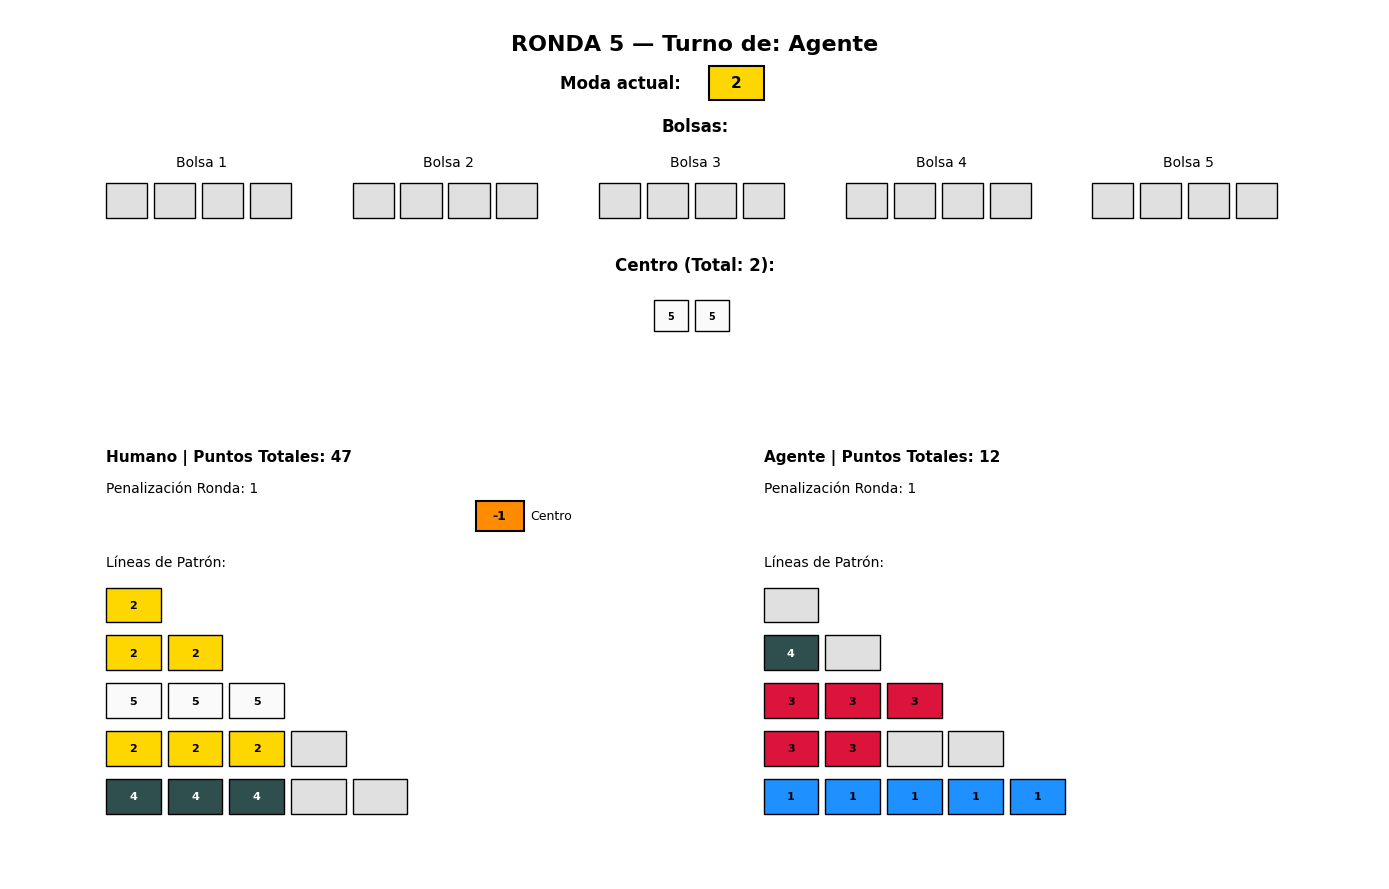


--------------------------------------
TURNO DEL AGENTE
--------------------------------------
Jugada elegida: (0, 5, 1)

Turno de Agente: (0, 5, 1)
Fichas tomadas: 2
Fichas sobrantes: 1

Resultados de la ronda 5
Moda: 2

Humano
Puntos por filas: 6
Puntos por moda: 6
Descuentos: 1
Puntos de la ronda: 11
Total acumulado: 58

Agente
Puntos por filas: 9
Puntos por moda: 0
Descuentos: 2
Puntos de la ronda: 7
Total acumulado: 19

========== FIN DE PARTIDA ==========
Humano : 58
Agente : 19

Ganador: Humano con 58 puntos.

========== FIN DE PARTIDA ==========
Humano : 58
Agente : 19

Ganador: Humano con 58 puntos.


In [ ]:
partida.jugar_partida()

JUGADA 59 | RONDA 5
Agente: R6
Origen: Centro
Color: Amarillo
Fichas tomadas: 1
Destino: Descarte

MARCADOR
R6: 26 puntos
R17: 42 puntos


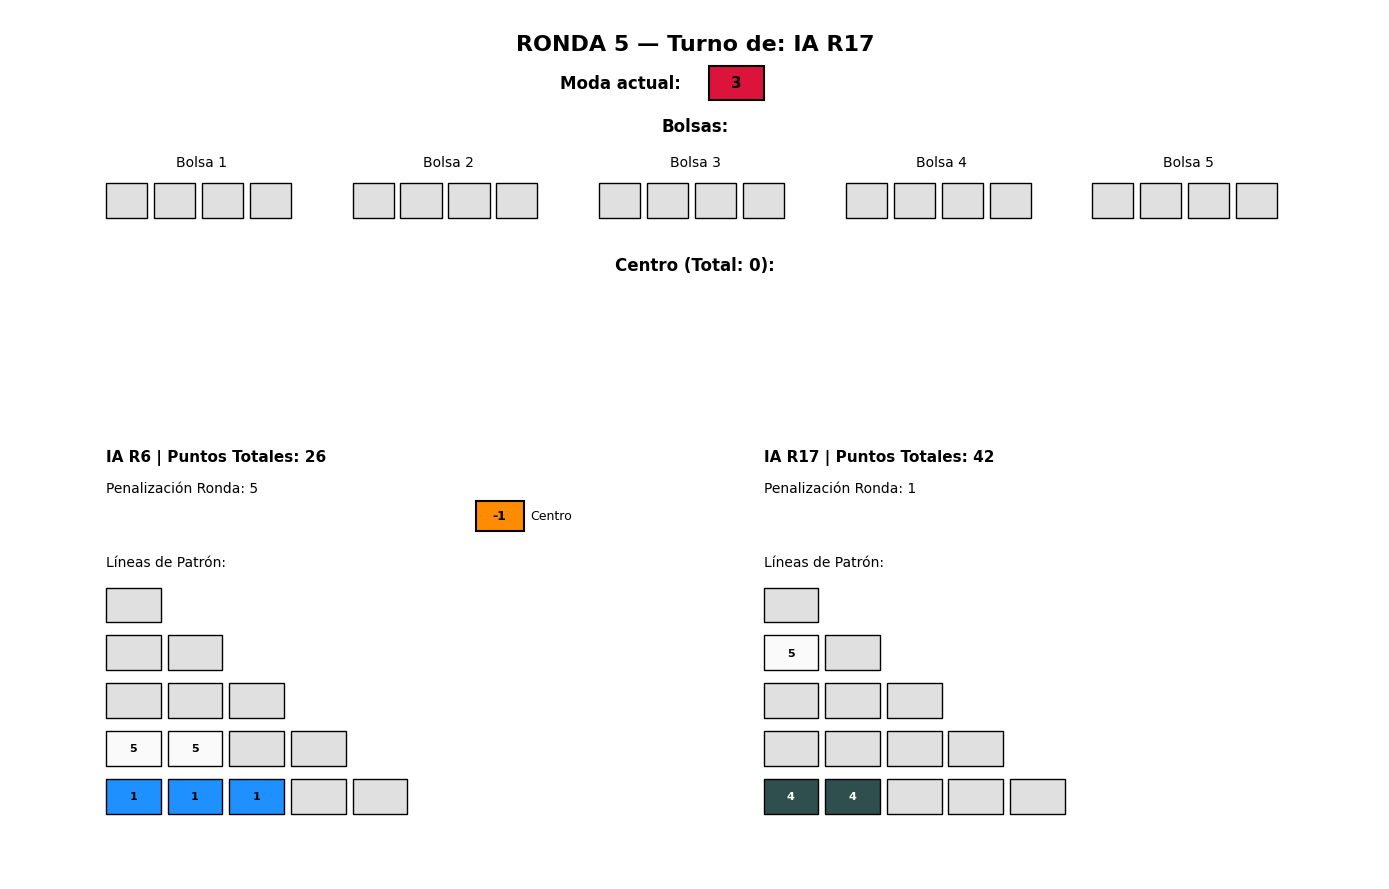


RESULTADO DE LA PARTIDA
R6: 26 puntos
R17: 42 puntos
GANADOR: R17


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Turno,Ronda,Agente,Origen,Color,Cantidad,Destino,Puntos R6,Puntos R17
0,1,1,R6,Bolsa 1,Negro,1,Fila 1,0,0
1,2,1,R17,Bolsa 4,Blanco,1,Fila 3,0,0
2,3,1,R6,Bolsa 2,Blanco,3,Fila 4,0,0
3,4,1,R17,Centro,Amarillo,3,Fila 5,0,0
4,5,1,R6,Centro,Blanco,1,Fila 4,0,0
5,6,1,R17,Centro,Rojo,3,Fila 4,0,0
6,7,1,R6,Bolsa 5,Amarillo,2,Fila 2,0,0
7,8,1,R17,Centro,Rojo,1,Fila 4,0,0
8,9,1,R6,Bolsa 3,Amarillo,1,Fila 5,0,0
9,10,1,R17,Centro,Azul,2,Fila 2,0,0



Historial guardado en: partida_R6_vs_R17.csv


In [21]:
# @title
#Hecho con IA
CARPETA = Path("modelos_Azul_5")

PASO_A_PASO = False
SEMILLA_PARTIDA = 2026

AGENTES_MANUALES = None

PARTIDAS_RANKING = 10



archivos = sorted(CARPETA.glob("R*.zip"),key=lambda p: int(p.stem[1:]))

modelos_duelo = {int(archivo.stem[1:]): MaskablePPO.load(str(archivo)) for archivo in archivos}

if len(modelos_duelo) < 2:
    raise ValueError("Se necesitan al menos dos modelos guardados.")



if AGENTES_MANUALES is not None:
    mejores = list(AGENTES_MANUALES)

else:
    matriz_actual = globals().get("matriz_Azul_2")

    if (matriz_actual is None or set(matriz_actual["indices"]) != set(modelos_duelo)):
        print("Calculando ranking entre los agentes...")

        matriz_actual = construir_matriz_enfrentamientos(modelos_duelo,partidas=PARTIDAS_RANKING,semilla=750000)

    indices = matriz_actual["indices"]
    W = np.array(matriz_actual["winrates"], dtype=float)

    puntuaciones = {}

    for i, numero in enumerate(indices):
        fila = W[i].copy()
        fila[i] = np.nan

        puntuaciones[numero] = np.nanmean(fila)

    mejores = sorted(puntuaciones,key=puntuaciones.get,reverse=True)[:2]

if len(mejores) != 2 or any( i not in modelos_duelo for i in mejores):
    raise ValueError("Los agentes seleccionados no están disponibles.")

A, B = mejores

print(f"Agentes seleccionados: R{A} y R{B}")


partida_duelo = nueva_partida(SEMILLA_PARTIDA)

partida_duelo.jugadores[0].nombre = f"IA R{A}"
partida_duelo.jugadores[1].nombre = f"IA R{B}"

modelos_partida = [modelos_duelo[A],modelos_duelo[B]]

historial = []
turno_numero = 0

nombres_colores = {1: "Azul",2: "Amarillo",3: "Rojo",4: "Negro",5: "Blanco"}

print("\nESTADO INICIAL")
partida_duelo.mostrar_estado()

if PASO_A_PASO:
    input("Presiona ENTER para comenzar...")


while not partida_duelo.terminada:

    if turno_numero >= 300:
        raise RuntimeError("La partida superó 300 turnos.")

    jugador = partida_duelo.turno
    numero_agente = mejores[jugador]
    modelo = modelos_partida[jugador]

    ronda = partida_duelo.azul.ronda

    obs = observacion(partida_duelo, jugador)
    mascara = mascara_acciones(partida_duelo)

    accion, _ = modelo.predict(obs,action_masks=mascara,deterministic=True)

    jugada = decodificar(int(np.asarray(accion).item()))

    bolsa, color, fila = jugada

    if jugada not in partida_duelo.jugadas_posibles():
        raise RuntimeError(f"Jugada ilegal: {jugada}")

    fuente = (partida_duelo.azul.centro if bolsa == 0 else partida_duelo.azul.bolsas[bolsa - 1])

    cantidad = int(np.count_nonzero(np.asarray(fuente) == color))

    origen = "Centro" if bolsa == 0 else f"Bolsa {bolsa}"
    destino = "Descarte" if fila == 0 else f"Fila {fila}"

    _jugar_sin_imprimir(partida_duelo, jugada)

    turno_numero += 1

    puntos_A = partida_duelo.jugadores[0].puntos
    puntos_B = partida_duelo.jugadores[1].puntos

    historial.append({"Turno": turno_numero,"Ronda": ronda,"Agente": f"R{numero_agente}","Origen": origen,"Color": nombres_colores[color],"Cantidad": cantidad,"Destino": destino,f"Puntos R{A}": puntos_A,f"Puntos R{B}": puntos_B})

    clear_output(wait=True)

    print("=" * 55)
    print(f"JUGADA {turno_numero} | RONDA {ronda}")
    print("=" * 55)

    print(f"Agente: R{numero_agente}")
    print(f"Origen: {origen}")
    print(f"Color: {nombres_colores[color]}")
    print(f"Fichas tomadas: {cantidad}")
    print(f"Destino: {destino}")

    print("\nMARCADOR")
    print(f"R{A}: {puntos_A} puntos")
    print(f"R{B}: {puntos_B} puntos")

    partida_duelo.mostrar_estado()

    if PASO_A_PASO and not partida_duelo.terminada:
        respuesta = input("ENTER = siguiente jugada | salir = detener: ")

        if respuesta.lower().strip() == "salir":
            print("Partida detenida manualmente.")
            break

print("\n" + "=" * 55)
print("RESULTADO DE LA PARTIDA")
print("=" * 55)

puntos_A = partida_duelo.jugadores[0].puntos
puntos_B = partida_duelo.jugadores[1].puntos

print(f"R{A}: {puntos_A} puntos")
print(f"R{B}: {puntos_B} puntos")

if partida_duelo.terminada:
    if puntos_A > puntos_B:
        print(f"GANADOR: R{A}")
    elif puntos_B > puntos_A:
        print(f"GANADOR: R{B}")
    else:
        print("EMPATE")

df_historial = pd.DataFrame(historial)
display(df_historial)

archivo = f"partida_R{A}_vs_R{B}.csv"
df_historial.to_csv(archivo, index=False)

print(f"\nHistorial guardado en: {archivo}")
#Termina lo hecho con IA

Generación de gráfico

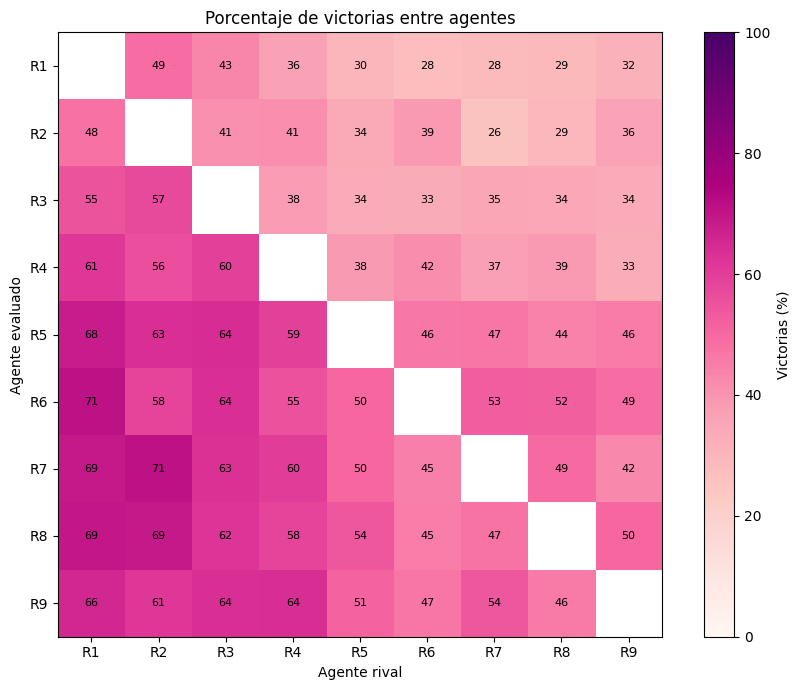

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


TypeError: 'int' object is not subscriptable

In [ ]:
# @title
#Hecho con IA
# 1. MATRIZ DE ENFRENTAMIENTOS
indices = matriz_info_2["indices"]
M = 100 * matriz_info_2["winrates"]

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(M, cmap="RdPu", vmin=0, vmax=100)

ax.set_xticks(range(len(indices)))
ax.set_yticks(range(len(indices)))
ax.set_xticklabels([f"R{i}" for i in indices])
ax.set_yticklabels([f"R{i}" for i in indices])

ax.set_xlabel("Agente rival")
ax.set_ylabel("Agente evaluado")
ax.set_title("Porcentaje de victorias entre agentes")

for i in range(len(indices)):
    for j in range(len(indices)):
        if i != j and np.isfinite(M[i, j]):
            ax.text(j, i, f"{M[i,j]:.0f}",
                    ha="center", va="center", fontsize=8)

fig.colorbar(im, ax=ax, label="Victorias (%)")
plt.tight_layout()
plt.show()


# 2. LONGITUD DE CADENA SEGÚN UMBRAL
umbrales = [
    r["umbral"] * 100
    for r in cadena_2
]
longitudes = [
    r["longitud"]
    for r in cadena_2
]

orden = np.argsort(umbrales)

plt.figure(figsize=(8, 4))
plt.plot(
    np.array(umbrales)[orden],
    np.array(longitudes)[orden],
    marker="o",
    linewidth=2
)
plt.xlabel("Porcentaje mínimo de victorias (%)")
plt.ylabel("Longitud de la cadena")
plt.title("Longitud de la cadena según el umbral")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# 3. PASOS DE ENTRENAMIENTO POR AGENTE
ruta = Path("modelos_Azul_2/resultados_generaciones.json")

with open(ruta, encoding="utf-8") as f:
    datos = json.load(f)

nombres = [r["modelo"] for r in datos]
pasos = [r["pasos_entrenamiento"] for r in datos]

colores = [
    "tab:green" if r["alcanzo_umbral"]
    else "tab:red"
    for r in datos
]

plt.figure(figsize=(9, 4))
plt.bar(nombres, pasos, color=colores)
plt.xlabel("Agente")
plt.ylabel("Pasos de entrenamiento")
plt.title("Costo de entrenamiento por agente")
plt.tight_layout()
plt.show()


# 4. DESEMPEÑO CONTRA UNIFORME
victorias = [
    100 * resultados_cadenas_2[i]["winrate"]
    for i in indices
]

plt.figure(figsize=(9, 4))
plt.bar(
    [f"R{i}" for i in indices],
    victorias
)
plt.axhline(
    70, linestyle="--",
    label="Referencia del 70 %"
)
plt.xlabel("Agente")
plt.ylabel("Porcentaje de victorias (%)")
plt.title("Desempeño contra estrategia uniforme")
plt.ylim(0, 105)
plt.legend()
plt.tight_layout()
plt.show()
#Termina lo hecho con IA

Generación de Gif/MP4  IA vs IA

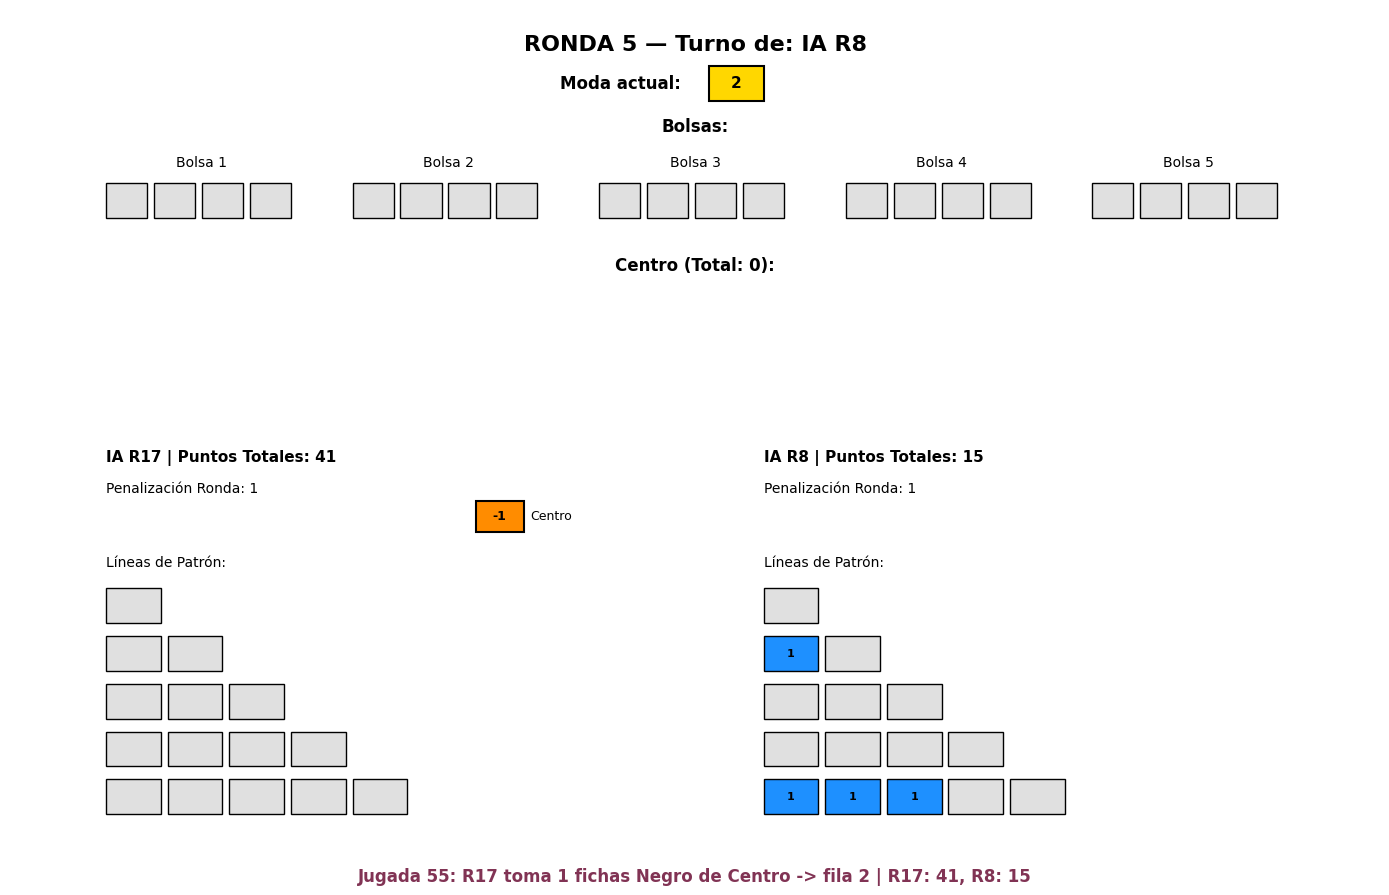

Jugada 55: R17 toma 1 fichas Negro de Centro -> fila 2 | R17: 41, R8: 15
MP4 guardado: /content/duelo_R17_vs_R8_semilla3000/R17_vs_R8.mp4
GIF guardado: /content/duelo_R17_vs_R8_semilla3000/R17_vs_R8.gif
Fotogramas PNG: /content/duelo_R17_vs_R8_semilla3000/imagenes
Historial CSV: /content/duelo_R17_vs_R8_semilla3000/historial.csv
Marcador final R17: 41, R8: 15. Ganador: R17


In [32]:
# @title
#Hecho con IA
if "mejores" not in globals() or "modelos_duelo" not in globals():
    raise RuntimeError("Primero ejecuta la celda del duelo que carga los agentes y elige 'mejores'.")

A, B = map(int, mejores)
A = 17
B = 8
SEMILLA_VIDEO = 3000
PASO_A_PASO = False   # True: Enter después de cada movimiento
DURACION_GIF = 0.8  # Segundos por imagen
FPS_MP4 = 2

partida_video = nueva_partida(SEMILLA_VIDEO)
partida_video.jugadores[0].nombre = f"IA R{A}"
partida_video.jugadores[1].nombre = f"IA R{B}"
modelos_video = [modelos_duelo[A], modelos_duelo[B]]

carpeta = Path(f"duelo_R{A}_vs_R{B}_semilla{SEMILLA_VIDEO}")
carpeta_png = carpeta / "imagenes"
carpeta_png.mkdir(parents=True, exist_ok=True)
fotogramas = []
historial = []
colores = {1: "Azul", 2: "Amarillo", 3: "Rojo", 4: "Negro", 5: "Blanco"}


def guardar_fotograma(etiqueta):
    with patch.object(plt, "show", lambda *args, **kwargs: None):
        partida_video.mostrar_estado()
    fig = plt.gcf()
    fig.text(0.5, 0.015, etiqueta, ha="center", fontsize=12,
             color="#813354", fontweight="bold")
    ruta = carpeta_png / f"fotograma_{len(fotogramas):03d}.png"
    fig.savefig(ruta, dpi=80, facecolor="white")  # 1120 x 720 px
    fotogramas.append(ruta)
    clear_output(wait=True)
    display(fig)
    print(etiqueta)
    plt.close(fig)

guardar_fotograma(f"Inicio: IA R{A} vs IA R{B}")
if PASO_A_PASO:
    input("ENTER para empezar...")

for turno in range(1, 301):
    if partida_video.terminada:
        break
    jugador = partida_video.turno
    agente = (A, B)[jugador]
    modelo = modelos_video[jugador]
    ronda = partida_video.azul.ronda

    obs = observacion(partida_video, jugador)
    mascara = mascara_acciones(partida_video)
    accion, _ = modelo.predict(obs, action_masks=mascara, deterministic=True)
    jugada = decodificar(int(np.asarray(accion).item()))
    if jugada not in partida_video.jugadas_posibles():
        raise RuntimeError(f"Acción ilegal de R{agente}: {jugada}")

    bolsa, color, fila = jugada
    fuente = partida_video.azul.centro if bolsa == 0 else partida_video.azul.bolsas[bolsa - 1]
    cantidad = sum(f == color for f in fuente)
    origen = "Centro" if bolsa == 0 else f"Bolsa {bolsa}"
    destino = "descarte" if fila == 0 else f"fila {fila}"
    _jugar_sin_imprimir(partida_video, jugada)

    puntos_A = int(partida_video.jugadores[0].puntos)
    puntos_B = int(partida_video.jugadores[1].puntos)
    texto = (f"Jugada {turno}: R{agente} toma {cantidad} fichas {colores[color]} " f"de {origen} -> {destino} | R{A}: {puntos_A}, R{B}: {puntos_B}")
    historial.append({"jugada": turno, "ronda": ronda, "agente": f"R{agente}","origen": origen, "color": colores[color], "cantidad": cantidad,"destino": destino, f"puntos_R{A}": puntos_A, f"puntos_R{B}": puntos_B})
    guardar_fotograma(texto)

    if PASO_A_PASO and not partida_video.terminada:
        if input("ENTER = siguiente | salir = terminar: ").strip().lower() == "salir":
            break

pd.DataFrame(historial).to_csv(carpeta / "historial.csv", index=False)
ruta_gif = carpeta / f"R{A}_vs_R{B}.gif"
ruta_mp4 = carpeta / f"R{A}_vs_R{B}.mp4"

with imageio.get_writer(str(ruta_gif), mode="I", duration=DURACION_GIF, loop=0) as gif:
    for ruta in fotogramas:
        gif.append_data(np.asarray(Image.open(ruta).convert("RGB")))

try:
    with imageio.get_writer(str(ruta_mp4), fps=FPS_MP4, codec="libx264", quality=7) as video:
        for ruta in fotogramas:
            video.append_data(np.asarray(Image.open(ruta).convert("RGB")))
    print("MP4 guardado:", ruta_mp4.resolve())
except Exception as e:
    print("No se pudo guardar el MP4 (quizás falta imageio-ffmpeg):", e)

print("GIF guardado:", ruta_gif.resolve())
print("Fotogramas PNG:", carpeta_png.resolve())
print("Historial CSV:", (carpeta / "historial.csv").resolve())
if partida_video.terminada:
    pA, pB = (int(j.puntos) for j in partida_video.jugadores)
    ganador = f"R{A}" if pA > pB else f"R{B}" if pB > pA else "Empate"
    print(f"Marcador final R{A}: {pA}, R{B}: {pB}. Ganador: {ganador}")
#Termina lo hecho con IA

Generación de Gif/MP4 IA vs Uniforme

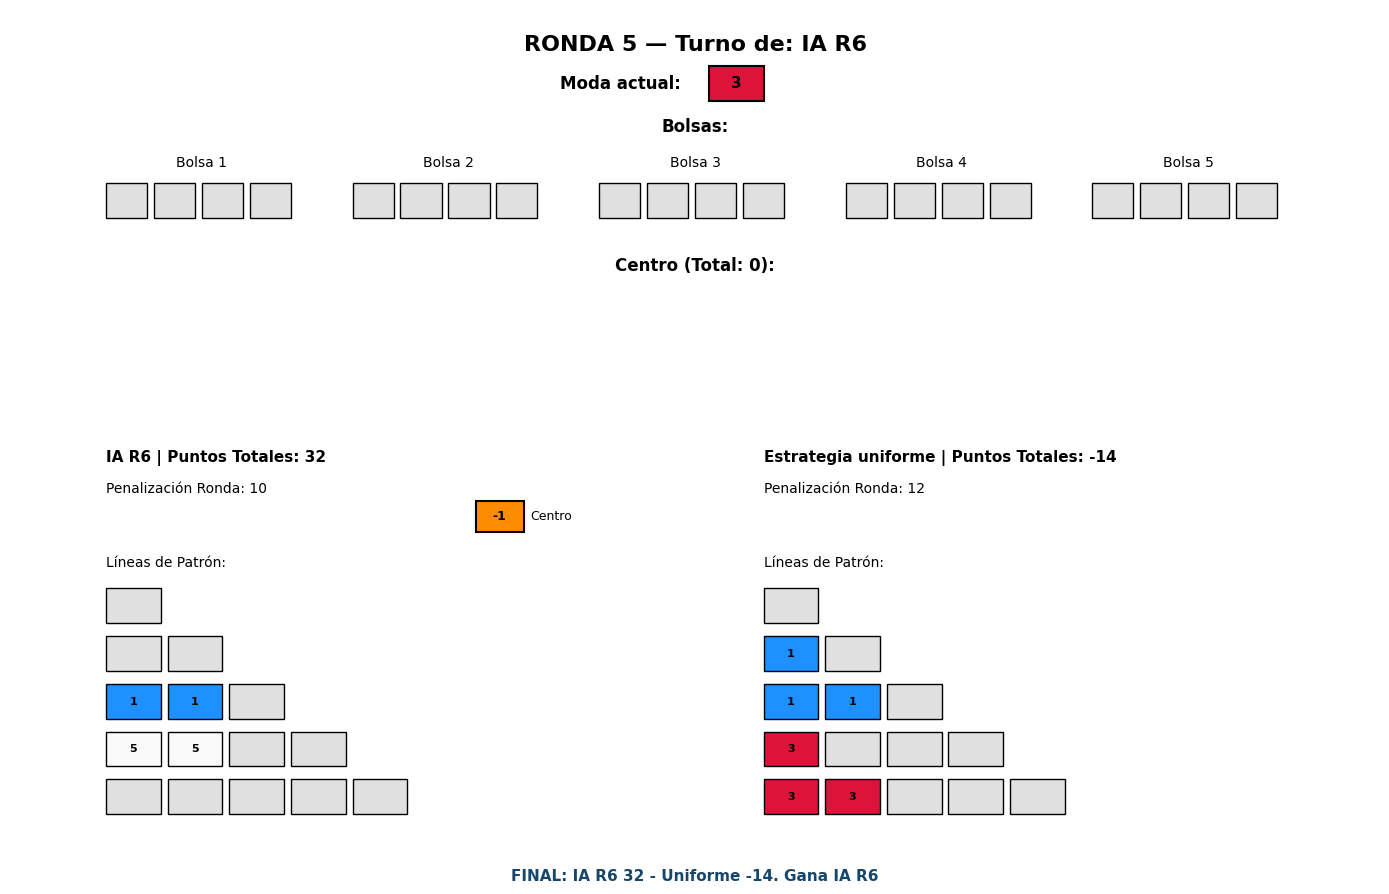

FINAL: IA R6 32 - Uniforme -14. Gana IA R6

VIDEO MP4: /content/video_R6_vs_uniforme_semilla2026/R6_vs_uniforme.mp4
HISTORIAL: /content/video_R6_vs_uniforme_semilla2026/historial.csv
GIF: /content/duelo_R17_vs_R8_semilla3000/R6_vs_uniforme.gif
CAPTURAS: /content/video_R6_vs_uniforme_semilla2026/imagenes
Resultado: FINAL: IA R6 32 - Uniforme -14. Gana IA R6


In [40]:
# @title
#Fue hecho con IA
CARPETA_MODELOS = Path('modelos_Azul_5')
AGENTE_MANUAL = 6       # Ej.: 10. None = mejor según ranking_agentes.csv.
ASIENTO_IA = 0             # 0: IA comienza; 1: comienza la uniforme.
SEMILLA_VIDEO = 2026
FPS_MP4 = 2                # 2 imágenes por segundo.
PASO_A_PASO = False       # True: ENTER para cada jugada.
MOSTRAR_EN_NOTEBOOK = True
GUARDAR_PNG = True
MAX_JUGADAS = 300

requeridas = ('nueva_partida', 'observacion', 'mascara_acciones','decodificar', 'jugada_uniforme', '_jugar_sin_imprimir')
faltantes = [nombre for nombre in requeridas if nombre not in globals()]
if faltantes:
    raise RuntimeError('Ejecuta primero las celdas de definiciones del notebook. ' f'Faltan: {faltantes}')

if ASIENTO_IA not in (0, 1):
    raise ValueError('ASIENTO_IA debe ser 0 o 1')

archivos_modelo = {int(p.stem[1:]): p for p in CARPETA_MODELOS.glob('R[0-9]*.zip') if p.stem[1:].isdigit()}
if not archivos_modelo:
    raise FileNotFoundError(f'No encontré modelos R*.zip en {CARPETA_MODELOS.resolve()}. ' 'Ejecuta esto en la carpeta que contiene tus modelos entrenados.')

if AGENTE_MANUAL is None:
    ruta_ranking = CARPETA_MODELOS / 'ranking_agentes.csv'
    if ruta_ranking.exists():
        ranking = pd.read_csv(ruta_ranking)
        if not {'agente', 'victorias_promedio_otros_%'}.issubset(ranking.columns):
            raise ValueError('El archivo ranking_agentes.csv tiene columnas inesperadas.')
        ranking = ranking.sort_values('victorias_promedio_otros_%', ascending=False)
        candidatos = []
        for nombre in ranking['agente'].astype(str):
            if nombre.startswith('R') and nombre[1:].isdigit():
                numero = int(nombre[1:])
                if numero in archivos_modelo:
                    candidatos.append(numero)
        if not candidatos:
            raise ValueError('El ranking no contiene modelos disponibles en la carpeta.')
        NUMERO_IA = candidatos[0]
        print(f'Mejor IA por el ranking: R{NUMERO_IA}')
    else:
        NUMERO_IA = max(archivos_modelo)
        print(f'No hay ranking: usaré R{NUMERO_IA}, el más reciente; '
              'NO necesariamente es el mejor. Puedes fijar AGENTE_MANUAL.')
else:
    NUMERO_IA = int(AGENTE_MANUAL)

if NUMERO_IA not in archivos_modelo:
    raise FileNotFoundError(f'No encontré R{NUMERO_IA}.zip en {CARPETA_MODELOS}')

modelo_ia = MaskablePPO.load(str(archivos_modelo[NUMERO_IA]))

partida_video = nueva_partida(SEMILLA_VIDEO)
partida_video.jugadores[ASIENTO_IA].nombre = f'IA R{NUMERO_IA}'
partida_video.jugadores[1-ASIENTO_IA].nombre = 'Estrategia uniforme'
rng_uniforme = np.random.default_rng(SEMILLA_VIDEO + 12345)

salida = Path(f'video_R{NUMERO_IA}_vs_uniforme_semilla{SEMILLA_VIDEO}')
imagenes = salida / 'imagenes'
salida.mkdir(exist_ok=True, parents=True)
if GUARDAR_PNG:
    imagenes.mkdir(exist_ok=True, parents=True)

ruta_mp4 = salida / f'R{NUMERO_IA}_vs_uniforme.mp4'
ruta_gif = carpeta / f"R{NUMERO_IA}_vs_uniforme.gif"
ruta_csv = salida / 'historial.csv'
colores = {1: 'azul', 2: 'amarillo', 3: 'rojo', 4: 'negro', 5: 'blanco'}
historial = []
numero_imagen = 0
ultimo_fotograma = None

video = imageio.get_writer(str(ruta_mp4), fps=FPS_MP4, codec='libx264',quality=7, macro_block_size=16)
frames_gif = []


def guardar_fotograma(etiqueta, repetir=1):
    global numero_imagen, ultimo_fotograma
    with patch.object(plt, 'show', lambda *args, **kwargs: None):
        partida_video.mostrar_estado()
    fig = plt.gcf()
    fig.text(0.50, 0.015, etiqueta, ha='center', fontsize=11,color='#17466B', fontweight='bold', wrap=True)
    fig.canvas.draw()

    # El tablero mide aproximadamente 1120 x 720 a dpi=80.
    if GUARDAR_PNG:
        destino = imagenes / f'fotograma_{numero_imagen:03d}.png'
        fig.savefig(destino, dpi=80, facecolor='white')
        with Image.open(destino) as im:
            frame = np.array(im.convert('RGB'))
    else:
        # Sin PNG intermedio; toma los píxeles del lienzo.
        frame = np.asarray(Image.fromarray(np.asarray(fig.canvas.buffer_rgba()).copy()[:, :, :3]).resize((1120, 720)))

    for _ in range(repetir):
        video.append_data(frame)
        frames_gif.append(frame.copy())
    ultimo_fotograma = frame

    if MOSTRAR_EN_NOTEBOOK:
        clear_output(wait=True)
        display(fig)
        print(etiqueta)
    plt.close(fig)
    numero_imagen += 1


incompleta = False
try:
    guardar_fotograma(f'Inicio: IA R{NUMERO_IA} contra uniforme', repetir=3)
    if PASO_A_PASO:
        input('ENTER para comenzar...')

    for turno in range(1, MAX_JUGADAS + 1):
        if partida_video.terminada:
            break

        jugador = int(partida_video.turno)
        ronda = int(partida_video.azul.ronda)
        quien = f'IA R{NUMERO_IA}' if jugador == ASIENTO_IA else 'Uniforme'

        if jugador == ASIENTO_IA:
            obs = observacion(partida_video, jugador)
            mascara = mascara_acciones(partida_video)
            accion, _ = modelo_ia.predict(obs, action_masks=mascara, deterministic=True)
            jugada = tuple(decodificar(int(np.asarray(accion).item())))
        else:
            jugada = tuple(jugada_uniforme(partida_video, rng_uniforme))

        if jugada not in partida_video.jugadas_posibles():
            raise RuntimeError(f'{quien} eligió una jugada ilegal: {jugada}')

        bolsa, color, fila = jugada
        fuente = (partida_video.azul.centro if bolsa == 0
                  else partida_video.azul.bolsas[bolsa - 1])
        cantidad = int(sum(int(f == color) for f in fuente))
        origen = 'centro' if bolsa == 0 else f'bolsa {bolsa}'
        destino = 'descarte' if fila == 0 else f'fila {fila}'

        _jugar_sin_imprimir(partida_video, jugada)
        puntos_ia = int(partida_video.jugadores[ASIENTO_IA].puntos)
        puntos_uniforme = int(partida_video.jugadores[1-ASIENTO_IA].puntos)

        historial.append({'turno': turno, 'ronda': ronda, 'jugador': quien,'bolsa': bolsa, 'color': color, 'fila': fila,'cantidad': cantidad, 'puntos_ia': puntos_ia,'puntos_uniforme': puntos_uniforme})
        etiqueta = (f'Turno {turno} (ronda {ronda}): {quien} toma {cantidad} ' f'fichas {colores[color]} de {origen} a {destino}  |  ' f'IA: {puntos_ia}  -  Uniforme: {puntos_uniforme}')
        guardar_fotograma(etiqueta)

        if PASO_A_PASO and not partida_video.terminada:
            if input('ENTER = siguiente | salir = detener: ').strip().lower() == 'salir':
                incompleta = True
                break
    else:
        incompleta = not partida_video.terminada

    p_ia = int(partida_video.jugadores[ASIENTO_IA].puntos)
    p_u = int(partida_video.jugadores[1-ASIENTO_IA].puntos)
    if partida_video.terminada:
        resultado = (f'Gana IA R{NUMERO_IA}' if p_ia > p_u else 'Gana uniforme' if p_u > p_ia else 'Empate')
        final = f'FINAL: IA R{NUMERO_IA} {p_ia} - Uniforme {p_u}. {resultado}'
    else:
        final = f'Partida interrumpida: IA {p_ia} - Uniforme {p_u}'
    guardar_fotograma(final, repetir=5)

# finally:
#     video.close()
#     pd.DataFrame(historial).to_csv(ruta_csv, index=False, encoding='utf-8-sig')
finally:
    video.close()
    if frames_gif:
        imageio.mimsave(str(ruta_gif),frames_gif,duration=1 / FPS_MP4,loop=0)

    pd.DataFrame(historial).to_csv(ruta_csv,index=False,encoding='utf-8-sig')

print(f'\nVIDEO MP4: {ruta_mp4.resolve()}')
print(f'HISTORIAL: {ruta_csv.resolve()}')
print(f'GIF: {ruta_gif.resolve()}')
if GUARDAR_PNG:
    print(f'CAPTURAS: {imagenes.resolve()}')
print(f'Resultado: {final if "final" in locals() else "interrumpido por error"}')

#Termina lo hecho con IA